# Project Name : Bank_Good_Credit 
## Project ID : PM-PR-0015
## Category : Banking_Credit_Risk

## Business Case :
- Bank GoodCredit wants to know which of its current credit card customers are likely to miss payments. The bank needs a credit score that shows how trustworthy a customer is with money, so it can lower the risk of defaults. The target column is Bad_label. A value of 0 means the customer has a good credit history, and 1 means the customer has gone 30 or more days past due. The bank's current model has a Gini of 37.9, so my goal is to build a model that beats it and ranks customers from low to high risk.

## Attributes :

**Target variable:** Bad_label

- 0 means the customer has a good credit history.
- 1 means the customer has a bad credit history, which is when a payment is 30 or more days late.

The data is stored in a MySQL database with three tables:

- **Cust_Account:** the old accounts of each customer and how they paid over time, like balance, credit limit and payment history.
- **Cust_Enquiry:** the credit enquiries made by each customer, like the enquiry date, the purpose and the amount.
- **Cust_Demographics:** the current customer applications. It has 79 hidden features (feature_1 to feature_79) and the target column Bad_label.

The bank hid the demographic features to protect customer privacy, so their real meaning is not known. I will explain the important columns of the other two tables in the data cleaning part.

## Goal :

The goal of this project is to build a model that predicts whether a credit card customer will have a bad credit history (Bad_label = 1) using the data given by Bank GoodCredit. The model should rank customers from low risk to high risk, so the bank can reduce credit default losses.

The project has three main deliverables:

- **Data exploration insights :** what I found in the data and what decisions I took because of it.
- **Feature matrix :** the list of selected features along with their gain.
- **Model evaluation :** the Gini score and the decile rank ordering, compared with the bank's benchmark Gini of 37.9.

## Domain Analysis :

Credit risk analysis is how a bank decides whether a customer is safe to lend to. The bank studies a customer's past accounts, payment habits and credit enquiries to estimate how likely the customer is to miss payments. If the risk is high, the bank may reject the application or give a lower credit limit. If the risk is low, the bank can approve it with more confidence.

Banks measure late payments in DPD (days past due). A customer who is 30 or more days late (30+ DPD) is treated as having a bad credit history, and this is how Bad_label is defined in this project.

A few things usually matter in credit risk:

- **Payment history:** how often and how late the customer has missed payments in the past.
- **Credit utilisation:** how much of the credit limit the customer is using. A high ratio can be a sign of financial stress.
- **Credit enquiries:** many recent enquiries can mean the customer is looking for credit in a hurry.

The bank also needs to rank customers from low risk to high risk, not just label them good or bad. That is why the model is judged by Gini and decile rank ordering instead of accuracy.

## Data Set Fields :
                                              
- For getting a Dataset we have to install pymysql and mysql connector. And the help of mysql we load dataset to work on this project.                                              

# Python Implimentation :

In [1]:
!pip install pymysql
!pip install mysql-connector-python

# Imports and Configurations :

In [2]:
import numpy as np 
import pandas as pd
# For EDA import Libraries:
import matplotlib.pyplot as plt 
import seaborn as sns 

In [3]:
import warnings
warnings.filterwarnings("ignore")

In [4]:
import os
import mysql.connector

In [5]:
conn=mysql.connector.connect(
    host='18.136.157.135',
    user='dm_team1',
    password='DM!$Team&279@20!',
    database='project_banking',
)

ca=pd.read_sql('select * from Cust_Account',conn)
ce=pd.read_sql('select * from Cust_Enquiry',conn)
cd=pd.read_sql('select * from Cust_Demographics',conn)


In [6]:
pd.set_option('display.max_columns', None)
ca.head()

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,cur_balance_amt,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,12265,20-Oct-15,6,1,09-Jun-13,30-Jun-14,05-Jul-14,30-Sep-15,20900,0,,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",,01-Sep-15,01-Jul-14,,,,,
1,10-Nov-15,12265,20-Oct-15,10,1,25-May-12,06-Sep-15,,03-Oct-15,16201,10390,,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",01-Oct-15,01-Nov-12,14000,1400,,3,5603
2,10-Nov-15,12265,20-Oct-15,10,1,22-Mar-12,31-Aug-15,,30-Sep-15,41028,34420,,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Sep-15,01-Oct-12,,,,,
3,20-Jul-15,15606,09-Jul-15,10,1,13-Jan-06,,26-Jul-07,31-Jan-09,93473,0,,"""""""1200900600600600300000000000000000000000000...",,01-Jul-07,01-Feb-06,,,,,
4,20-Jul-15,15606,09-Jul-15,6,1,18-Jan-15,05-May-15,,31-May-15,20250,13500,,"""""""000000000000000""""""",,01-May-15,01-Jan-15,,,,,


In [7]:
pd.set_option('display.max_columns', None)
ce.head()

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
0,18-Apr-15,1,21-Apr-15,19-Dec-14,2,3500000
1,18-Apr-15,1,21-Apr-15,05-Mar-14,5,500000
2,18-Apr-15,1,21-Apr-15,05-Mar-14,0,50000
3,18-Apr-15,1,21-Apr-15,22-Feb-14,10,50000
4,18-Apr-15,1,21-Apr-15,11-Jun-13,10,1000


In [8]:
pd.set_option('display.max_columns', None)
cd.head()

,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37,feature_38,feature_39,feature_40,feature_41,feature_42,feature_43,feature_44,feature_45,feature_46,feature_47,feature_48,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57,feature_58,feature_59,feature_60,feature_61,feature_62,feature_63,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_70,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
0,18-Apr-15,1,13-Apr-15,Insignia,13-Apr-15,650,2,Card Setup,14,500000,,,,Y,IS1,,0,159,4284,4284,,1,ADFPNXXXXX,03-Sep-65,98332XXXXX,N,@REDIFFMAIL.COM,1,2,,Mumbai / Navi Mumbai / Thane,400610,1965,0,Self,Y,2,90000,,,,0,0,0,0,Mumbai,400059,@CODOGNOTTO.NET,PAN Card,ADFPNXXXXX,The Ratnakar Bank Ltd.,,Y,State Bank of India,0,01-Jun-13,17-Jun-16,1,21,,Y,Y,N,,Y,1965-0,21,15,400610,0,2,90000,Nov-00,21,R,,,0000-00-00,0,98332XXXXX,1,N,0
1,21-Apr-15,2,21-Apr-15,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,,,,Y,IS1,,0,91,B001,4077,,1,AJWPRXXXXX,14-Jul-62,99455XXXXX,N,@GMAIL.COM,1,2,,Bengaluru,560042,1969,0,Self,Y,2,1,,,,0,0,0,0,Bangalore,560042,,PAN Card,AJWPRXXXXX,The Ratnakar Bank Ltd.,,N,,0,,17-Jun-16,1,17,,Y,Y,N,,Y,1969-0,17,12,560042,0,2,1,Nov-00,17,R,,,0000-00-00,0,99455XXXXX,1,N,0
2,22-Apr-15,3,21-Apr-15,Insignia,21-Apr-15,774,1,Card Setup,14,700000,,,,Y,IS1,,0,91,B001,4077,,2,AFAPNXXXXX,10-Apr-66,98456XXXXX,N,@SHOBANARAYAN.COM,1,0,,Bengaluru,560042,1966,0,Self,Y,2,1,,,,0,0,0,0,Bangalore,560042,,PAN Card,AFAPNXXXXX,,,N,,0,,17-Jun-16,3,17,,N,Y,N,,Y,1966-0,17,12,560042,0,2,1,Nov-00,17,R,,,0000-00-00,0,98456XXXXX,1,N,0
3,25-Apr-15,4,15-Apr-15,Insignia,20-Apr-15,770,1,Card Setup,14,500000,,,,Y,IS1,,0,157,5107,5107,,1,AAAPDXXXXX,16-Apr-64,98220XXXXX,N,@VSNL.COM,1,3,,Pune,411001,1988,0,Self,Y,2,100000,,,,0,0,0,0,Pune,411026,@ALBAJ.COM,PAN Card,AAAPDXXXXX,The Ratnakar Bank Ltd.,,Y,HDFC Bank,0,,17-Jun-16,1,21,,Y,Y,N,,Y,1988-0,21,16,411001,0,2,100000,Nov-00,21,R,,,6/15/65,1,98220XXXXX,1,N,0
4,06-May-15,5,30-Apr-15,Insignia,,,3,Card Setup,14,500000,,,,Y,IS1,,0,100,D016,4564,,1,ABEPSXXXXX,03-Jan-54,98111XXXXX,N,@REDIFFMAIL.COM,1,3,,Gurgaon,122009,1995,0,Self,Y,2,300000,,,,0,0,0,0,Gurgaon,122009,,PAN Card,ABEPSXXXXX,The Ratnakar Bank Ltd.,,N,,0,,17-Jun-16,1,13,,Y,Y,N,,Y,1995-0,13,3,122009,0,2,300000,Nov-00,13,R,,,0000-00-00,0,98111XXXXX,1,N,0


### Insights from the First Look at the Data :

I checked the first 5 rows of each table. This is a small sample, so these are first observations. I will confirm them on the full data.

#### Cust_Account

- One customer can have many accounts (customer 12265 has 3 rows), so I will combine them into one row per customer.
- The dates are stored as text, like `10-Nov-15`. I will convert them to a proper date format.
- `paymenthistory1` has extra `"""` quotes at the start and end, so I will remove them.
- `closed_dt`, `creditlimit` and `cashlimit` have many empty values. I will check the missing percentage.

#### Cust_Enquiry

- All enquiries of customer 1 were made before the application date. I will check the full table for any enquiry date after `dt_opened`, because that would be data leakage.
- `enq_purpose` is a code, so it is a category and not a number.

#### Cust_Demographics

- This table has one row per customer.
- Some features have the same value in every row (feature_5, feature_6, feature_11, feature_12) and some look empty (feature_8 to feature_10). I will check with `nunique()` and `isnull().sum()` and drop what gives no information.
- feature_20, feature_22 and feature_24 look like personal information (ID, phone number, email). I will confirm and drop them.
- feature_21 looks like a date of birth. Pandas may read the year `65` as 2065, so I need to fix it before calculating age.

#### Things to check next

- How many customers have no rows in the other two tables?
- What is the distribution of `Bad_label`?

# Basic checks for Customer Account Table :

In [9]:
print('shape :',ca.shape)
print('Columns : \n',ca.columns.to_list())

shape : (186329, 21)
Columns : 
 ['dt_opened', 'customer_no', 'upload_dt', 'acct_type', 'owner_indic', 'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt', 'high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'paymenthistory1', 'paymenthistory2', 'paymt_str_dt', 'paymt_end_dt', 'creditlimit', 'cashlimit', 'rateofinterest', 'paymentfrequency', 'actualpaymentamount']


In [10]:
ca.head()

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,cur_balance_amt,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,12265,20-Oct-15,6,1,09-Jun-13,30-Jun-14,05-Jul-14,30-Sep-15,20900,0,,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",,01-Sep-15,01-Jul-14,,,,,
1,10-Nov-15,12265,20-Oct-15,10,1,25-May-12,06-Sep-15,,03-Oct-15,16201,10390,,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",01-Oct-15,01-Nov-12,14000,1400,,3,5603
2,10-Nov-15,12265,20-Oct-15,10,1,22-Mar-12,31-Aug-15,,30-Sep-15,41028,34420,,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Sep-15,01-Oct-12,,,,,
3,20-Jul-15,15606,09-Jul-15,10,1,13-Jan-06,,26-Jul-07,31-Jan-09,93473,0,,"""""""1200900600600600300000000000000000000000000...",,01-Jul-07,01-Feb-06,,,,,
4,20-Jul-15,15606,09-Jul-15,6,1,18-Jan-15,05-May-15,,31-May-15,20250,13500,,"""""""000000000000000""""""",,01-May-15,01-Jan-15,,,,,


In [11]:
ca.tail()

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,cur_balance_amt,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
186324,11-Jun-15,1611,25-May-15,10,1,02-May-07,21-Apr-15,,30-Apr-15,24228,24228,,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Apr-15,01-May-12,,,,,
186325,11-Jun-15,1611,25-May-15,10,1,11-Apr-07,22-Jun-09,02-Apr-10,30-Apr-15,19584,0,,"""""""000179146119089058029000XXX""""""",,01-Apr-10,01-Aug-09,,,,3,
186326,11-Jun-15,1611,25-May-15,10,1,20-Nov-06,,12-Apr-12,31-Dec-13,50844,0,,"""""""000XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX...",,01-Apr-12,01-Dec-10,,,,3,
186327,11-Jun-15,1611,25-May-15,10,1,17-Oct-06,,07-Mar-12,15-Apr-15,35587,0,,"""""""000010000000000000000000000000000XXXXXXXXXX...","""""""XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX...",01-Mar-12,01-Apr-09,15000,6000,,3,
186328,11-Jun-15,1611,25-May-15,6,1,29-Nov-05,,31-Dec-08,11-Jun-10,26000,0,,"""""""000000000000000000000000000XXXXXXXXXXXXXXX0...",,01-Dec-08,01-Oct-07,,,,,


In [12]:
ca.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186329 entries, 0 to 186328
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   dt_opened            186329 non-null  object
 1   customer_no          186329 non-null  object
 2   upload_dt            186329 non-null  object
 3   acct_type            186329 non-null  object
 4   owner_indic          186329 non-null  object
 5   opened_dt            186329 non-null  object
 6   last_paymt_dt        186329 non-null  object
 7   closed_dt            186329 non-null  object
 8   reporting_dt         186329 non-null  object
 9   high_credit_amt      186329 non-null  object
 10  cur_balance_amt      186329 non-null  object
 11  amt_past_due         186329 non-null  object
 12  paymenthistory1      186329 non-null  object
 13  paymenthistory2      186329 non-null  object
 14  paymt_str_dt         186329 non-null  object
 15  paymt_end_dt         186329 non-nu

In [13]:
ca.duplicated().sum()

np.int64(2401)

In [14]:
ca.isnull().sum()

dt_opened              0
customer_no            0
upload_dt              0
acct_type              0
owner_indic            0
opened_dt              0
last_paymt_dt          0
closed_dt              0
reporting_dt           0
high_credit_amt        0
cur_balance_amt        0
amt_past_due           0
paymenthistory1        0
paymenthistory2        0
paymt_str_dt           0
paymt_end_dt           0
creditlimit            0
cashlimit              0
rateofinterest         0
paymentfrequency       0
actualpaymentamount    0
dtype: int64

In [15]:
ca.describe(include='O')

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,cur_balance_amt,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
count,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329
unique,197,23896,75,31,4,6246,4511,4840,1877,67555,56425,630,18311,11912,234,235,1380,1456,1476,3,18300
top,16-Nov-15,8516,21-Apr-15,10,1,13-Apr-12,,,31-Jul-15,,0,,"""""""0000000000000000000000000000000000000000000...",,01-Jul-15,01-Jan-15,,,,,
freq,4643,120,5128,100239,177287,514,25487,109075,12654,8875,89872,185453,44979,107824,16747,5640,137477,151047,161496,122436,145276


In [16]:
for i in ca.columns:
    ca.loc[ca[i]=='',i]=np.nan

In [17]:
ca.isnull().sum()

dt_opened                   0
customer_no                 0
upload_dt                   0
acct_type                   0
owner_indic                 0
opened_dt                 455
last_paymt_dt           25487
closed_dt              109075
reporting_dt                0
high_credit_amt          8875
cur_balance_amt             0
amt_past_due           185453
paymenthistory1             0
paymenthistory2        107824
paymt_str_dt                1
paymt_end_dt                1
creditlimit            137477
cashlimit              151047
rateofinterest         161496
paymentfrequency       122436
actualpaymentamount    145276
dtype: int64

# Data Cleaning and change datatype :

In [18]:
# change datatype to 'datetime64'
date_columns=['dt_opened','upload_dt','opened_dt','last_paymt_dt','closed_dt','closed_dt','reporting_dt','paymt_str_dt','paymt_end_dt']
for dc in date_columns:
    ca[dc]=ca[dc].astype('datetime64[ns]')

In [19]:
# change datatype from object to int64 and float64
f_col = ['high_credit_amt', 'cur_balance_amt', 'amt_past_due','paymenthistory1','paymenthistory2', 'creditlimit', 'cashlimit', 'actualpaymentamount']

for oc in f_col:
    ca[oc] = pd.to_numeric(ca[oc], errors='coerce').astype('float64')

i_col = ['customer_no', 'acct_type', 'owner_indic','paymentfrequency']

for ic in i_col:
    ca[ic] = pd.to_numeric(ca[ic], errors='coerce').astype('float64')

In [20]:
ca.loc[ca['rateofinterest'] == '"9', 'rateofinterest'] = '9'
ca.loc[ca['rateofinterest'] == '"8', 'rateofinterest'] = '8'
ca.loc[ca['rateofinterest'] == '"7', 'rateofinterest'] = '7'

ca['rateofinterest'] = pd.to_numeric(ca['rateofinterest'], errors='coerce').astype('float64')

In [21]:
ca.rateofinterest = ca['rateofinterest'].astype('float64')

In [22]:
ca.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186329 entries, 0 to 186328
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   dt_opened            186329 non-null  datetime64[ns]
 1   customer_no          186329 non-null  float64       
 2   upload_dt            186329 non-null  datetime64[ns]
 3   acct_type            186329 non-null  float64       
 4   owner_indic          186329 non-null  float64       
 5   opened_dt            185874 non-null  datetime64[ns]
 6   last_paymt_dt        160842 non-null  datetime64[ns]
 7   closed_dt            77254 non-null   datetime64[ns]
 8   reporting_dt         186329 non-null  datetime64[ns]
 9   high_credit_amt      177454 non-null  float64       
 10  cur_balance_amt      186329 non-null  float64       
 11  amt_past_due         876 non-null     float64       
 12  paymenthistory1      0 non-null       float64       
 13  paymenthistory

# EDA(Bank_Good_Credit) :

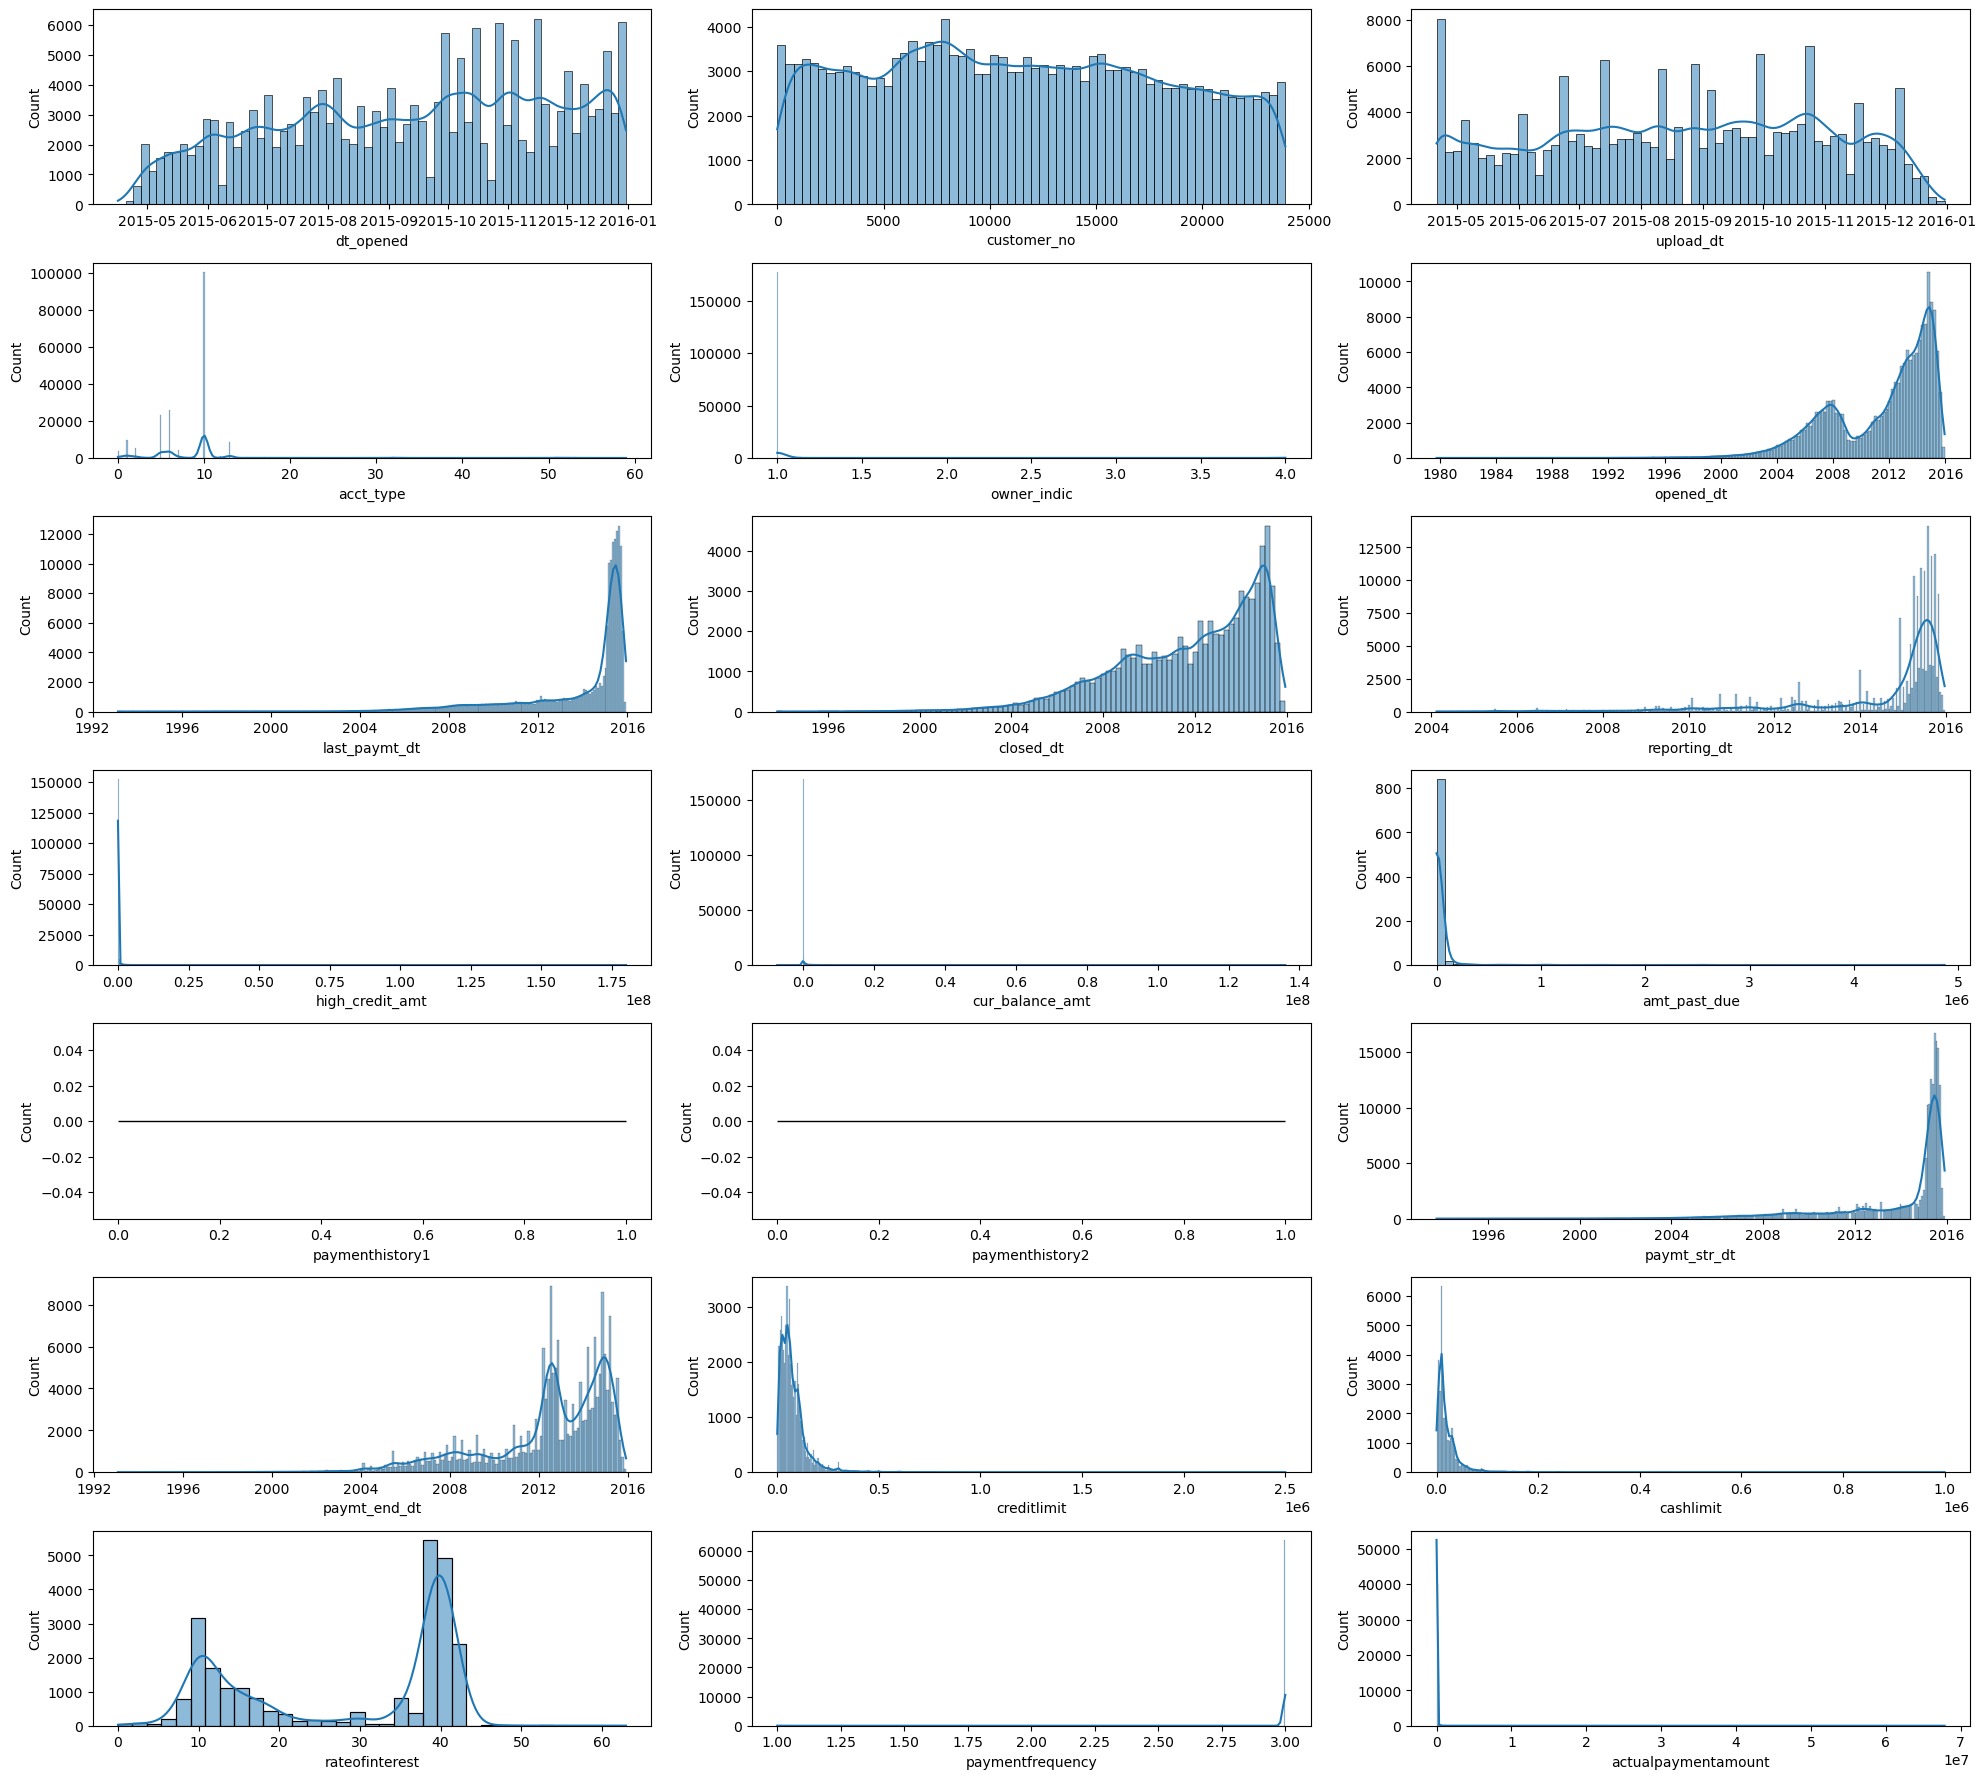

In [23]:
plt.figure(figsize=(20,20))
for i,col in enumerate(ca,1):
    plt.subplot(8,3,i)
    sns.histplot(ca[col],kde=1)
plt.tight_layout()
plt.show()

#### Insights from the Cust_Account Histograms :

- `dt_opened` and `upload_dt` run from May 2015 to January 2016, which looks like the application window.
- `opened_dt` goes back to 1980, but most accounts were opened after 2008.
- `last_paymt_dt`, `reporting_dt` and `paymt_str_dt` are mostly from 2015 to 2016, so most accounts are active or recently reported.
- `acct_type` has one huge spike at code 10, so I will group the rare codes later.
- `owner_indic` is almost all 1, so it may not help the model much.
- `high_credit_amt` and `cur_balance_amt` are very skewed. Almost all values are near zero and a few go up to 1e8. I will check the outliers and try a log transform.
- `amt_past_due` has a much lower count than the other columns, so it may be mostly empty. I will confirm with `isnull().sum()`.
- `paymenthistory1` and `paymenthistory2` are text strings, so the histogram shows nothing. I need to parse them first.

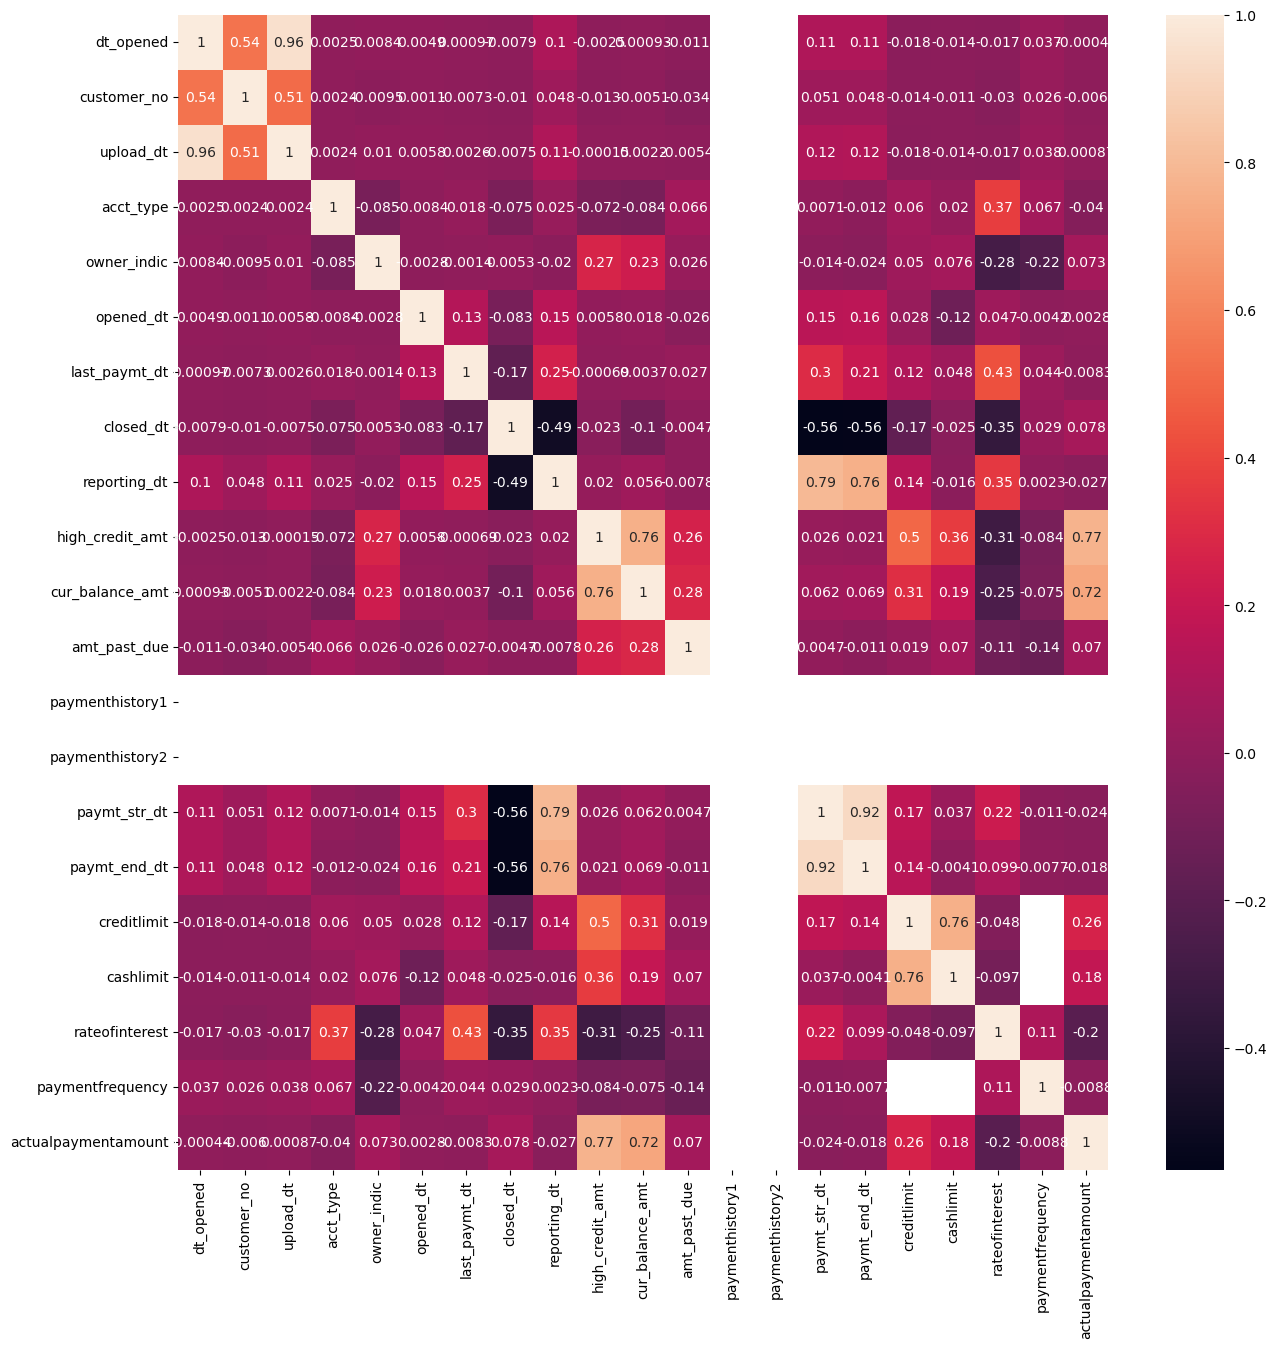

In [24]:
plt.figure(figsize=(15,15))
sns.heatmap(data=ca.corr(),annot=True)
plt.show()

In [25]:
drop_col=['last_paymt_dt','upload_dt','dt_opened','paymenthistory1','paymenthistory2','paymt_str_dt','paymt_end_dt','closed_dt','reporting_dt']

In [26]:
cad=ca.drop(drop_col,axis=1)

#### Insights from the Cust_Account Heatmap :

- `dt_opened` and `upload_dt` are highly correlated (0.96), so I will keep only one.
- `paymt_str_dt` and `paymt_end_dt` are also highly correlated (0.92), so I can drop one.
- `high_credit_amt`, `cur_balance_amt` and `actualpaymentamount` are strongly related (0.72 to 0.77).
- `creditlimit` and `cashlimit` are correlated (0.76).
- `paymenthistory1` and `paymenthistory2` are empty because they are text columns.

<Axes: >

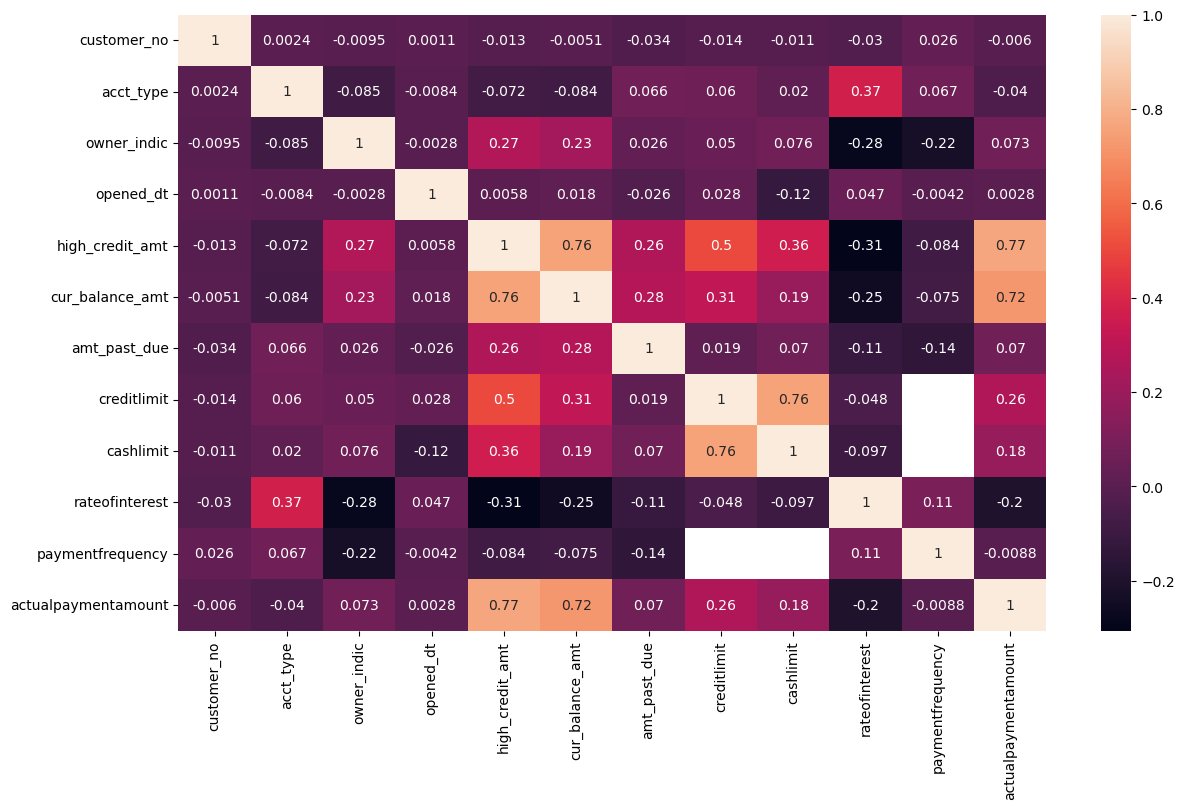

In [27]:
plt.figure(figsize=(14,8))
sns.heatmap(data=cad.corr(),annot=True)

#### Insights :
- `high_credit_amt`, `cur_balance_amt` and `actualpaymentamount` are strongly correlated (0.72 to 0.77).
- `creditlimit` and `cashlimit` are also strongly correlated (0.76), and `creditlimit` has a moderate link with `high_credit_amt` (0.5).
- Most other columns have weak correlations with each other.

# Handling Null Values :

In [28]:
cad.isnull().sum()

customer_no                 0
acct_type                   0
owner_indic                 0
opened_dt                 455
high_credit_amt          8875
cur_balance_amt             0
amt_past_due           185453
creditlimit            137477
cashlimit              151047
rateofinterest         161496
paymentfrequency       122436
actualpaymentamount    145276
dtype: int64

In [29]:
over_null_value=['amt_past_due','creditlimit','cashlimit','rateofinterest','paymentfrequency','actualpaymentamount','rateofinterest']

In [30]:
cad=cad.drop(over_null_value,axis=1)

In [31]:
cad.isnull().sum()

customer_no           0
acct_type             0
owner_indic           0
opened_dt           455
high_credit_amt    8875
cur_balance_amt       0
dtype: int64

In [32]:
cad

,customer_no,acct_type,owner_indic,opened_dt,high_credit_amt,cur_balance_amt
0,12265.0,6.0,1.0,2013-06-09,20900.0,0.0
1,12265.0,10.0,1.0,2012-05-25,16201.0,10390.0
2,12265.0,10.0,1.0,2012-03-22,41028.0,34420.0
3,15606.0,10.0,1.0,2006-01-13,93473.0,0.0
4,15606.0,6.0,1.0,2015-01-18,20250.0,13500.0
...,...,...,...,...,...,...
186324,1611.0,10.0,1.0,2007-05-02,24228.0,24228.0
186325,1611.0,10.0,1.0,2007-04-11,19584.0,0.0
186326,1611.0,10.0,1.0,2006-11-20,50844.0,0.0
186327,1611.0,10.0,1.0,2006-10-17,35587.0,0.0


In [33]:
cad.loc[cad['opened_dt'].isnull(),'opened_dt']=cad['opened_dt'].mode()[0]

In [34]:
cad.isnull().sum()

customer_no           0
acct_type             0
owner_indic           0
opened_dt             0
high_credit_amt    8875
cur_balance_amt       0
dtype: int64

In [35]:
cad.isnull().sum()

customer_no           0
acct_type             0
owner_indic           0
opened_dt             0
high_credit_amt    8875
cur_balance_amt       0
dtype: int64

In [36]:
cad['high_credit_amt'].median()

45223.5

In [37]:
cad.loc[cad['high_credit_amt'].isnull(),'high_credit_amt']=cad['high_credit_amt'].median()

In [38]:
cad.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186329 entries, 0 to 186328
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   customer_no      186329 non-null  float64       
 1   acct_type        186329 non-null  float64       
 2   owner_indic      186329 non-null  float64       
 3   opened_dt        186329 non-null  datetime64[ns]
 4   high_credit_amt  186329 non-null  float64       
 5   cur_balance_amt  186329 non-null  float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 8.5 MB


# Basic Checks  for customer demographics table :

In [39]:
cd.head(10) 

,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37,feature_38,feature_39,feature_40,feature_41,feature_42,feature_43,feature_44,feature_45,feature_46,feature_47,feature_48,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57,feature_58,feature_59,feature_60,feature_61,feature_62,feature_63,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_70,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
0,18-Apr-15,1,13-Apr-15,Insignia,13-Apr-15,650,2,Card Setup,14,500000,,,,Y,IS1,,0,159,4284,4284,,1,ADFPNXXXXX,03-Sep-65,98332XXXXX,N,@REDIFFMAIL.COM,1,2,,Mumbai / Navi Mumbai / Thane,400610,1965,0,Self,Y,2,90000,,,,0,0,0,0,Mumbai,400059,@CODOGNOTTO.NET,PAN Card,ADFPNXXXXX,The Ratnakar Bank Ltd.,,Y,State Bank of India,0,01-Jun-13,17-Jun-16,1,21,,Y,Y,N,,Y,1965-0,21,15,400610,0,2,90000,Nov-00,21,R,,,0000-00-00,0,98332XXXXX,1,N,0
1,21-Apr-15,2,21-Apr-15,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,,,,Y,IS1,,0,91,B001,4077,,1,AJWPRXXXXX,14-Jul-62,99455XXXXX,N,@GMAIL.COM,1,2,,Bengaluru,560042,1969,0,Self,Y,2,1,,,,0,0,0,0,Bangalore,560042,,PAN Card,AJWPRXXXXX,The Ratnakar Bank Ltd.,,N,,0,,17-Jun-16,1,17,,Y,Y,N,,Y,1969-0,17,12,560042,0,2,1,Nov-00,17,R,,,0000-00-00,0,99455XXXXX,1,N,0
2,22-Apr-15,3,21-Apr-15,Insignia,21-Apr-15,774,1,Card Setup,14,700000,,,,Y,IS1,,0,91,B001,4077,,2,AFAPNXXXXX,10-Apr-66,98456XXXXX,N,@SHOBANARAYAN.COM,1,0,,Bengaluru,560042,1966,0,Self,Y,2,1,,,,0,0,0,0,Bangalore,560042,,PAN Card,AFAPNXXXXX,,,N,,0,,17-Jun-16,3,17,,N,Y,N,,Y,1966-0,17,12,560042,0,2,1,Nov-00,17,R,,,0000-00-00,0,98456XXXXX,1,N,0
3,25-Apr-15,4,15-Apr-15,Insignia,20-Apr-15,770,1,Card Setup,14,500000,,,,Y,IS1,,0,157,5107,5107,,1,AAAPDXXXXX,16-Apr-64,98220XXXXX,N,@VSNL.COM,1,3,,Pune,411001,1988,0,Self,Y,2,100000,,,,0,0,0,0,Pune,411026,@ALBAJ.COM,PAN Card,AAAPDXXXXX,The Ratnakar Bank Ltd.,,Y,HDFC Bank,0,,17-Jun-16,1,21,,Y,Y,N,,Y,1988-0,21,16,411001,0,2,100000,Nov-00,21,R,,,6/15/65,1,98220XXXXX,1,N,0
4,06-May-15,5,30-Apr-15,Insignia,,,3,Card Setup,14,500000,,,,Y,IS1,,0,100,D016,4564,,1,ABEPSXXXXX,03-Jan-54,98111XXXXX,N,@REDIFFMAIL.COM,1,3,,Gurgaon,122009,1995,0,Self,Y,2,300000,,,,0,0,0,0,Gurgaon,122009,,PAN Card,ABEPSXXXXX,The Ratnakar Bank Ltd.,,N,,0,,17-Jun-16,1,13,,Y,Y,N,,Y,1995-0,13,3,122009,0,2,300000,Nov-00,13,R,,,0000-00-00,0,98111XXXXX,1,N,0
5,12-May-15,6,06-May-15,Insignia,06-May-15,779,1,Card Setup,14,1000000,,,,Y,IS1,,0,88,5231,5231,,1,ABQPNXXXXX,10-Jul-63,99202XXXXX,N,@GMAIL.COM,1,3,,Mumbai / Navi Mumbai / Thane,400012,2000,0,Self,Y,2,1,,,,0,0,0,0,Mumbai,400001,@HSBC.CO.IN,,XXXXX,The Ratnakar Bank Ltd.,,N,,0,,17-Jun-16,1,21,,Y,Y,N,,Y,2000-0,21,15,400012,0,2,1,Nov-00,21,R,,,10/27/63,1,99870XXXXX,1,N,0
6,22-May-15,7,06-May-15,Insignia,06-May-15,762,1,Card Setup,14,100000,,,,Y,IS2,,0,100,5957,6031,,1,AAKPDXXXXX,22-Apr-54,98100XXXXX,N,@VSNL.NET,1,0,,New Delhi,110075,1964,0,Self,Y,1,1,Government Organisation,Others,ADMIN OFFICER,2014,1,11,0,New Delhi,110021,@VSNL.NET,PAN Card,AAKPDXXXXX,The Ratnakar Bank Ltd.,,N,,0,,17-Jun-16,1,10,,Y,Y,N,,Y,1964-0,10,157,110075,0,1,1,0-0,10,O,,,0000-00-00,0,98100XXXXX,1,N,0
7,22-May-15,8,15-May-15,Insignia,15-May-15,799,1,Card Setup,14,357000,,,,Y,IS2,,0,88,5785,5785,,1,ABZPDXXXXX,26-Apr-51,96865XXXXX,N,@PRUDENTBROKERS.COM,1,3,,Bengaluru,560052,1964,0,Self,Y,2,1,,,,0,0,0,0,Mumbai,400025,,PAN Card,ABZPDXXXXX,,,N,,0,,17-Jun-16,1,17,,N,Y,N,,Y,1964-0,17,12,560052,0,2,1,Nov-00,21,R,,,0000-00-00,0,96865XXXXX,1,N,0
8,28-May-15,9,15-May-15,Insignia,15-May-15,762,1,Card Setup,14,550000,,,,Y,IS2,,0,88,5785,5785,,1,AAFPDXXXXX,01-Sep-

In [40]:
cd.describe()

,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37,feature_38,feature_39,feature_40,feature_41,feature_42,feature_43,feature_44,feature_45,feature_46,feature_47,feature_48,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57,feature_58,feature_59,feature_60,feature_61,feature_62,feature_63,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_70,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
count,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896
unique,197,23896,297,8,282,263,4,2,2,485,20,20,8,3,17,15,3,365,523,303,13,3,10610,8463,3251,3,722,3,12,11,63,965,53,14,6,3,4,4334,10,12,5664,19,14,13,13,71,937,4473,6,11250,57,19,3,11,660,181,2,5,13,3,3,3,3,9,3,492,28,425,3013,3,4,4334,134,14,3,3,4,63,6,3124,4,3,2
top,16-Nov-15,1,19-Oct-15,Platinum Maxima,,,3,Card Setup,14,35000,,,,Y,PM1,,12,SA03,AS19,,,1,AXMPKXXXXX,01-Jan-85,99999XXXXX,N,@GMAIL.COM,1,0,Graduate,New Delhi,110059,2010,0,Self,Y,1,1,Private Ltd. Co.,Banking/Financial Services,,0,0,0,0,New Delhi,201301,,PAN Card,XXXXX,,,Y,,0,,17-Jun-16,1,10,,N,Y,N,,Y,2010-0,10,157,110059,0,1,1,0-0,10,R,,,0000-00-00,0,XXXXX,1,N,0
freq,699,1,180,9056,2836,2836,14593,23881,23881,797,22635,22635,23845,22611,8853,13004,10892,9331,1374,22869,23878,22701,16,33,194,21528,15595,18295,15503,14610,12539,1097,1839,21315,10833,19478,18214,8392,8677,13187,5682,5667,6344,5944,23181,9760,2320,13713,22796,94,18399,23792,12565,11422,11807,11610,23881,22693,12539,21503,23425,22611,23563,23887,23876,1670,10257,10257,944,19478,18214,8392,18235,9760,15617,20951,23879,23820,23817,2149,22958,23876,22892


In [41]:
cd.duplicated().sum()

np.int64(0)

In [42]:
cd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23896 entries, 0 to 23895
Data columns (total 83 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   dt_opened    23896 non-null  object
 1   customer_no  23896 non-null  object
 2   entry_time   23896 non-null  object
 3   feature_1    23896 non-null  object
 4   feature_2    23896 non-null  object
 5   feature_3    23896 non-null  object
 6   feature_4    23896 non-null  object
 7   feature_5    23896 non-null  object
 8   feature_6    23896 non-null  object
 9   feature_7    23896 non-null  object
 10  feature_8    23896 non-null  object
 11  feature_9    23896 non-null  object
 12  feature_10   23896 non-null  object
 13  feature_11   23896 non-null  object
 14  feature_12   23896 non-null  object
 15  feature_13   23896 non-null  object
 16  feature_14   23896 non-null  object
 17  feature_15   23896 non-null  object
 18  feature_16   23896 non-null  object
 19  feature_17   23896 non-nu

In [43]:
cd.isnull().sum()

dt_opened      0
customer_no    0
entry_time     0
feature_1      0
feature_2      0
              ..
feature_76     0
feature_77     0
feature_78     0
feature_79     0
Bad_label      0
Length: 83, dtype: int64

In [44]:
for j in cd.columns:
    cd.loc[cd[j]=='',j]=np.nan

In [45]:
cd.isnull().sum()

dt_opened         0
customer_no       0
entry_time       15
feature_1        15
feature_2      2836
               ... 
feature_76       15
feature_77        0
feature_78       15
feature_79       15
Bad_label         0
Length: 83, dtype: int64

# Data cleaning and change datatype :

In [46]:
datetime64=['dt_opened','entry_time','feature_2','feature_21','feature_53','feature_54']
for d in datetime64:
    cd[d]=cd[d].astype('datetime64[ns]')

In [47]:
cd[datetime64].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23896 entries, 0 to 23895
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dt_opened   23896 non-null  datetime64[ns]
 1   entry_time  23881 non-null  datetime64[ns]
 2   feature_2   21060 non-null  datetime64[ns]
 3   feature_21  23881 non-null  datetime64[ns]
 4   feature_53  12286 non-null  datetime64[ns]
 5   feature_54  23881 non-null  datetime64[ns]
dtypes: datetime64[ns](6)
memory usage: 1.1 MB


In [48]:
#  To create a variable named "num_obj_col" which contain only Numerical & Catagorical data.
num_obj_col = cd.drop(datetime64,axis=1)

In [49]:
# To convert Numerical values from 'Object' to 'Float' using Loop.
for i in num_obj_col.columns:
    try:
        cd[i] = cd[i].astype(float)
    except ValueError:
        pass

In [50]:
# After converting numerical values to 'Float',Separate those & put in a Variable named "num_col_2".
num_col_2 = []
for i in cd.columns :
    if cd[i].dtype == 'float':
                num_col_2.append(i)

In [51]:
# "num_col_2" varible which contain only Numerical data.
cd[num_col_2].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23896 entries, 0 to 23895
Data columns (total 34 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   customer_no  23896 non-null  float64
 1   feature_3    21060 non-null  float64
 2   feature_4    23881 non-null  float64
 3   feature_6    23881 non-null  float64
 4   feature_7    23881 non-null  float64
 5   feature_14   16163 non-null  float64
 6   feature_19   23881 non-null  float64
 7   feature_25   23881 non-null  float64
 8   feature_26   23881 non-null  float64
 9   feature_29   23881 non-null  float64
 10  feature_30   23881 non-null  float64
 11  feature_31   23881 non-null  float64
 12  feature_34   23881 non-null  float64
 13  feature_35   23881 non-null  float64
 14  feature_39   23881 non-null  float64
 15  feature_40   23881 non-null  float64
 16  feature_41   23881 non-null  float64
 17  feature_42   23881 non-null  float64
 18  feature_44   23881 non-null  float64
 19  feat

In [52]:
# TO Separate Catagorical data in a variable named "obj_col_2".
obj_col_2 = []
for i in cd.columns :
    if cd[i].dtype == "O" :
        obj_col_2.append(i)       

In [53]:
# "obj_col_2" varible which contain only Categorical data.
cd[obj_col_2].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23896 entries, 0 to 23895
Data columns (total 43 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   feature_1   23881 non-null  object
 1   feature_5   23881 non-null  object
 2   feature_8   1261 non-null   object
 3   feature_9   1261 non-null   object
 4   feature_10  51 non-null     object
 5   feature_11  23881 non-null  object
 6   feature_12  23881 non-null  object
 7   feature_13  10892 non-null  object
 8   feature_15  23873 non-null  object
 9   feature_16  23869 non-null  object
 10  feature_17  1027 non-null   object
 11  feature_18  18 non-null     object
 12  feature_20  23896 non-null  object
 13  feature_22  23896 non-null  object
 14  feature_23  23881 non-null  object
 15  feature_24  23256 non-null  object
 16  feature_27  20259 non-null  object
 17  feature_28  23881 non-null  object
 18  feature_32  23881 non-null  object
 19  feature_33  23881 non-null  object
 20  featur

#### Insights from `cd`: Separate KYC Document Columns :

| Feature | Meaning |
|---|---|
| `feature_20`, `feature_46`, `feature_47` | PAN No |
| `feature_22`, `feature_77` | Phone Number |
| `feature_24` | Email ID |
| `feature_27` | Degree |
| `feature_28` | Location |
| `feature_45` | Websites |

#### Insights from `cd`: Separate Columns with One Unique Value

| Feature | Note |
|---|---|
| `feature_5` | One unique value |
| `feature_6` | One unique value |
| `feature_54` | One unique value |

In [54]:
# Checking the unique value of 'feature_5','feature_6','feature_54' Columns.
cd.feature_5.unique()

array(['Card Setup', nan], dtype=object)

# EDA  for 'Cust_Demographics'  Table :

## EDA for all Numerical Data : in "num_col_2" variables :

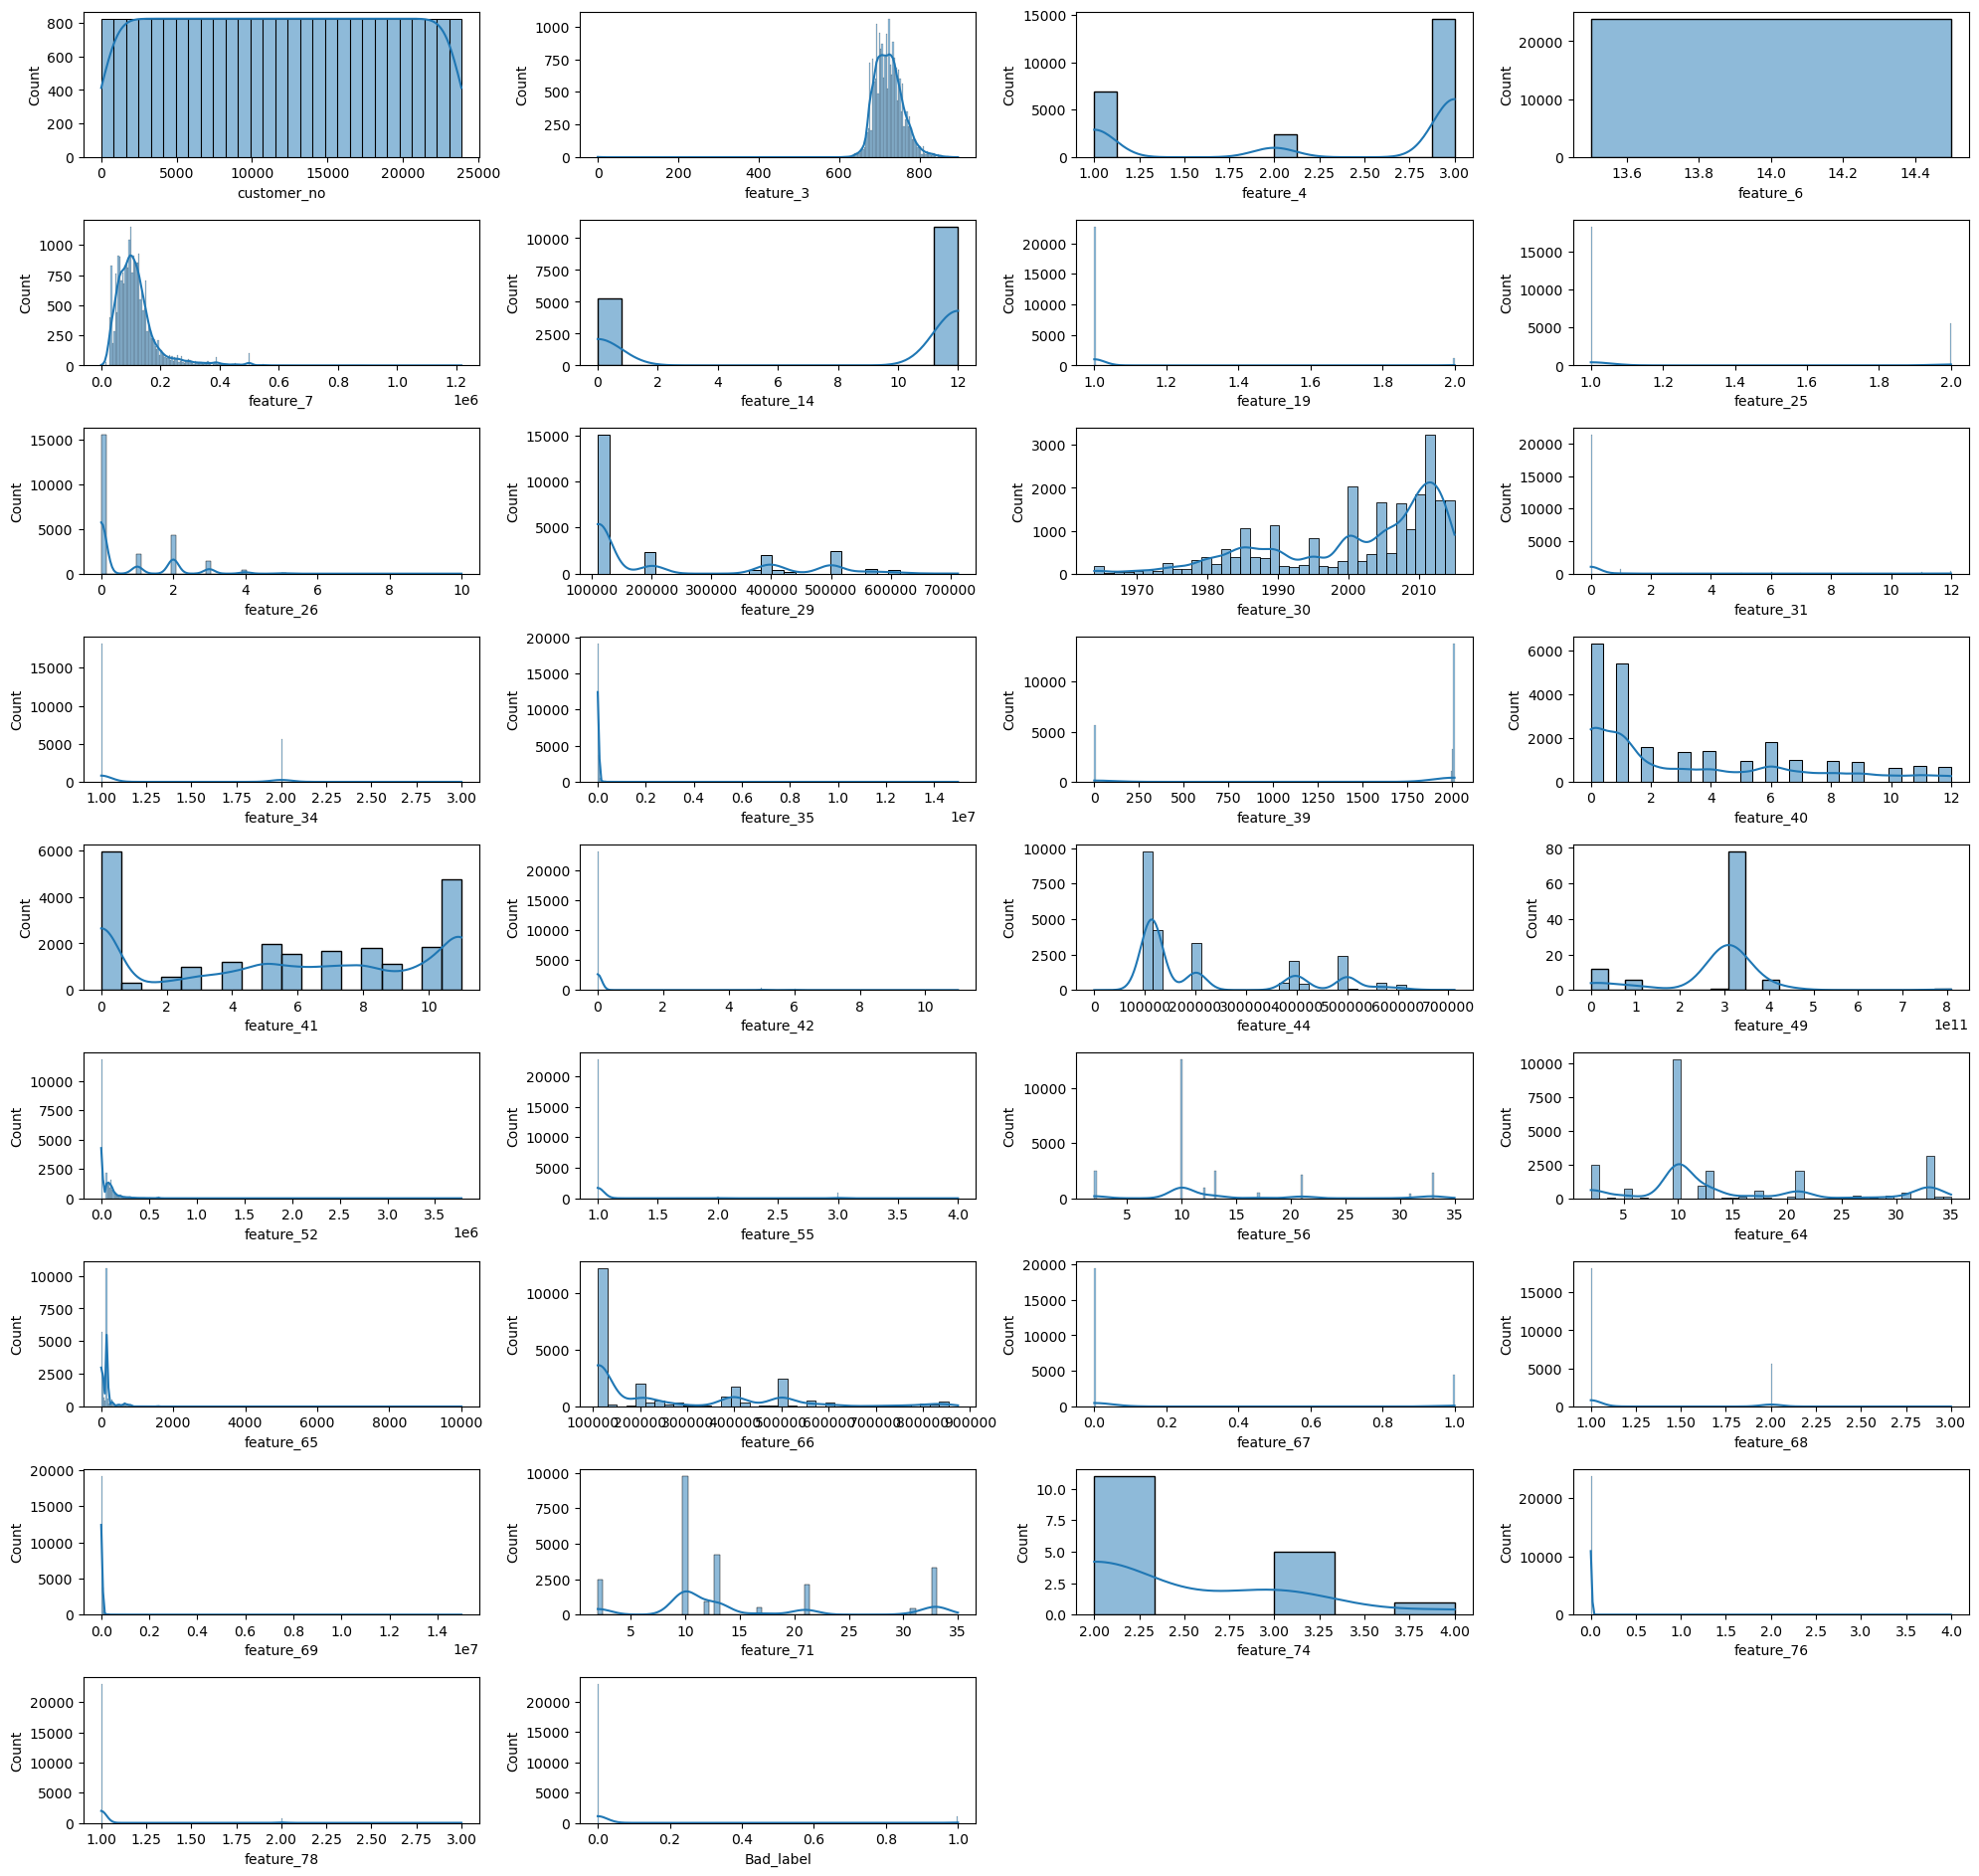

In [55]:
# EDA for all Numerical data of "cd" using a loop.
plt.figure(figsize=(20,29))  # (length,hight)
plotnumber=1
for i in cd[num_col_2] :
    plt.subplot(14,4,plotnumber)
    sns.histplot(x=cd[i],kde=1)
    plotnumber = plotnumber+1
plt.tight_layout()

#### Insights from `cd`: EDA of Numerical Columns

- `customer_no`: ID column, uniform shape, not useful for modeling
- `feature_3`: Near normal, mostly between 600 and 850
- `feature_4`: Only 3 values (1, 2, 3), looks categorical
- `feature_6`: One unique value
- `feature_7`, `feature_26`, `feature_29`: Right-skewed, may have outliers
- `feature_14`, `feature_19`, `feature_25`: Only 2 values, looks categorical
- `feature_30`: Left-skewed, looks like years (mostly after 2000)
- `feature_31`: Almost all values are 0, very little variation

In [56]:
len(obj_col_2)

43

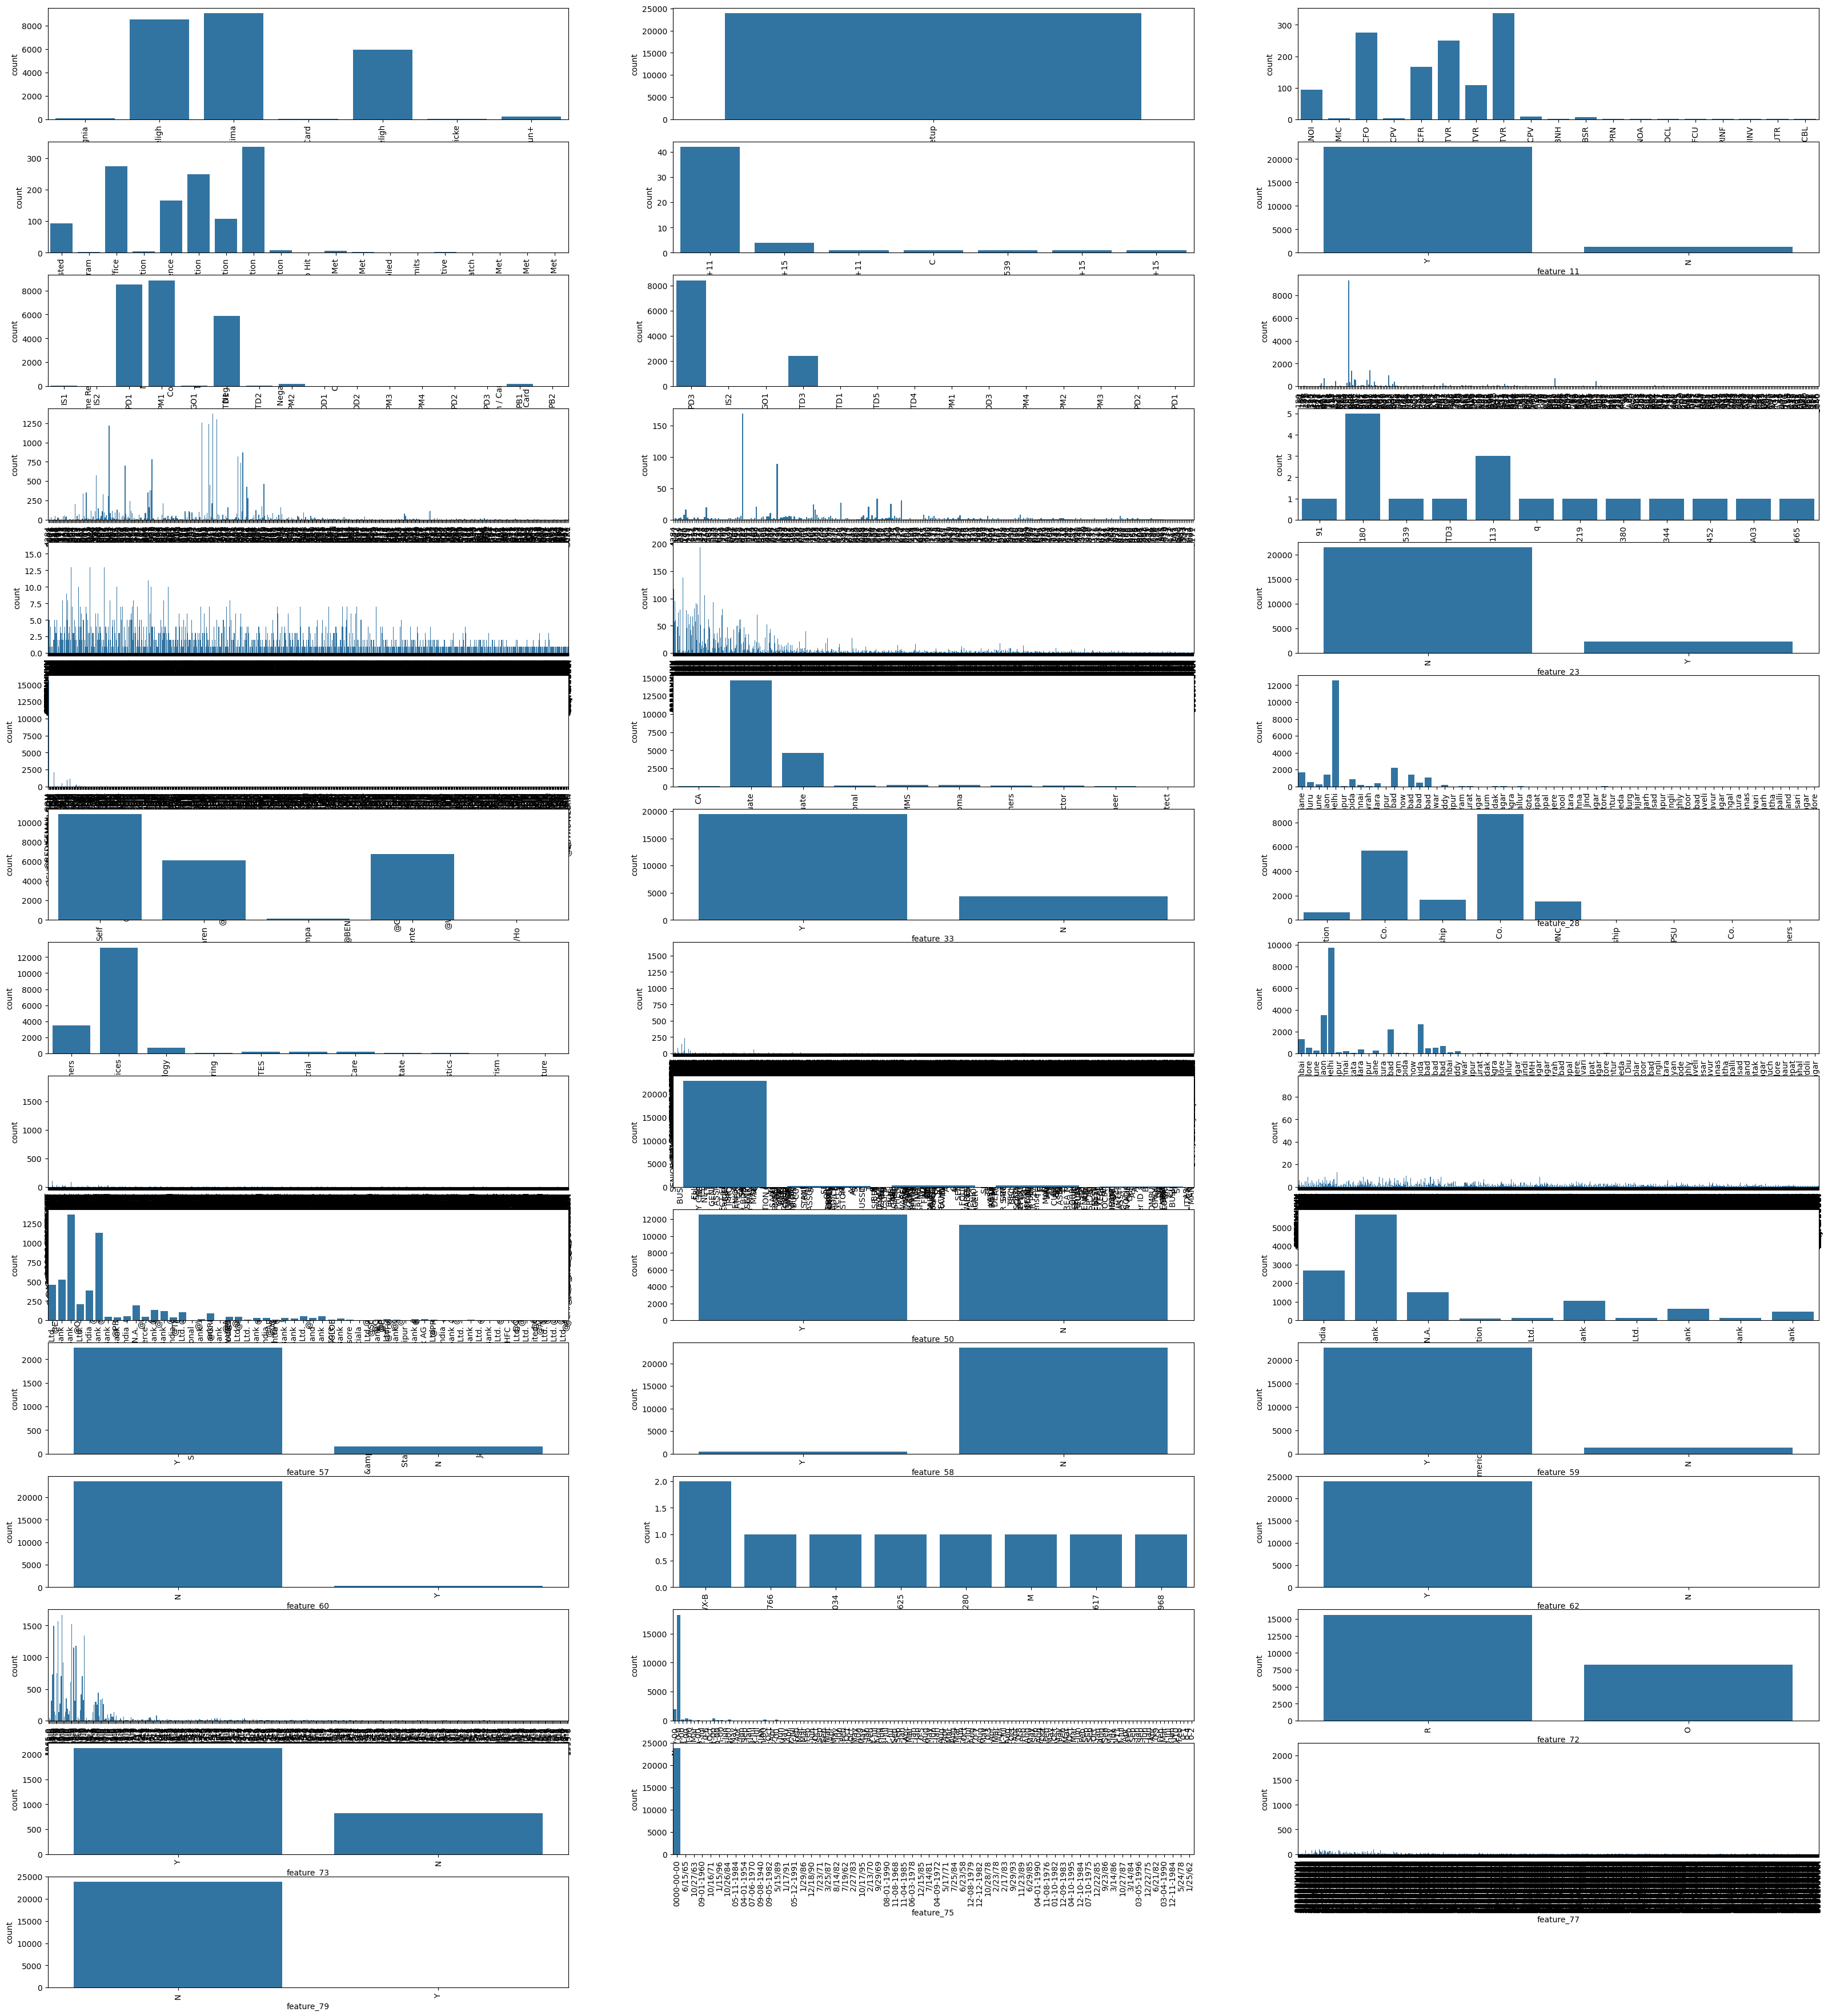

In [57]:
plt.figure(figsize=(40,45))  # (length,hight)
plotnumber=1
for i in cd[obj_col_2] :
    plt.subplot(15,3,plotnumber)
    sns.countplot(x=cd[i])
    plt.xticks(rotation = 90)
    plotnumber = plotnumber+1
plt.tight_layout()
plt.show()

In [58]:
!pip install sweetviz

In [59]:
import sweetviz as sv

In [60]:
report=sv.analyze(cd)
report.show_html('report_cd.html')

                                             |                                             | [  0%]   00:00 ->…

Report report_cd.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


In [61]:
# We can find from above Univariate Analysis there is some columns which has more than 50% missing value.
# Separate those Columns which has more than 50 % missing values, and put in a variable named "missing_value_2".
missing_value_2 = ['feature_8','feature_9','feature_10','feature_13','feature_17','feature_18','feature_45','feature_48',
                   'feature_49','feature_57','feature_61','feature_73','feature_74']

# KYC document columns
kyc_doc_2 = ['feature_20','feature_22','feature_24', 'feature_27','feature_28',
             'feature_45','feature_46','feature_47','feature_77']
# One unique value columns
unique_value_2 = ['feature_5','feature_6','feature_54']

#### Insights from above analysis :
- "dt_opened" columns is in which date  customere's Account has been oppened. which is same as Table_1, so we can drop this columns from Table_2.
- "customer_no" is a serial number of a customer, we can use it as a foraign key.
- "feature_1" column containing various types of "Credit Cards ", in which maximum is 'Platinum Maxima'(9056), & 'Platinum Deligh'(8541), and after that 'Titanium Deligh'(5943), and Others are 'RBL Bank Fun'(218),'Insignia'(67),'GolfCard'(30), & 'Platinum Cricke'(26).

- -----------------------------------------------------------------------------------------------------------------------------
### Columns which we need to drop , because those are not impacting Terget Class :

- From above insights we can say all columns which containing "dates" like [ 'entry_time', 'feature_2' , 'feature_21' ,'feature_53' , 'feature_54'] are not impacting to terget class,so we can drop those columns.
- Columns 'feature_20','feature_22','feature_24', 'feature_27','feature_28','feature_45','feature_46','feature_47',
&'feature_77' contain Customer details which is called KYC, This is we need to drop.
- 'feature_5','feature_6', & 'feature_54' columns have same unique value, thats why we can drop those columns.
- 'feature_8','feature_9','feature_10','feature_13','feature_17','feature_18','feature_45','feature_48','feature_49', 'feature_57','feature_61','feature_73','feature_74 in those columns , there are more than 50 % missing values, we can't replace those values , cause Terget class could be effected, like uder fitting or over fitting . So we need to drop those columns.

# Data Cleaning of cust_demographic table :

In [62]:
delete_col_2=datetime64 + kyc_doc_2 + unique_value_2 + missing_value_2

In [63]:
cd2=cd.drop(delete_col_2,axis=1)

In [64]:
cd2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23896 entries, 0 to 23895
Data columns (total 54 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   customer_no  23896 non-null  float64
 1   feature_1    23881 non-null  object 
 2   feature_3    21060 non-null  float64
 3   feature_4    23881 non-null  float64
 4   feature_7    23881 non-null  float64
 5   feature_11   23881 non-null  object 
 6   feature_12   23881 non-null  object 
 7   feature_14   16163 non-null  float64
 8   feature_15   23873 non-null  object 
 9   feature_16   23869 non-null  object 
 10  feature_19   23881 non-null  float64
 11  feature_23   23881 non-null  object 
 12  feature_25   23881 non-null  float64
 13  feature_26   23881 non-null  float64
 14  feature_29   23881 non-null  float64
 15  feature_30   23881 non-null  float64
 16  feature_31   23881 non-null  float64
 17  feature_32   23881 non-null  object 
 18  feature_33   23881 non-null  object 
 19  feat

# Handling Null Values :

In [65]:
# To filling Null values using 'Mode' for categorical data & 'Median' for numerical data, using a loop.
for i in cd2.columns:
    if cd2[i].isnull().sum()>=1:
        if cd2[i].dtype== 'O':
            cd2.loc[cd2[i].isnull(),i]=cd2[i].mode()[0]
        elif cd2[i].dtype=='float':
            cd2.loc[cd2[i].isnull(),i]=cd2[i].median()

In [66]:
cd2.isnull().sum()

customer_no    0
feature_1      0
feature_3      0
feature_4      0
feature_7      0
feature_11     0
feature_12     0
feature_14     0
feature_15     0
feature_16     0
feature_19     0
feature_23     0
feature_25     0
feature_26     0
feature_29     0
feature_30     0
feature_31     0
feature_32     0
feature_33     0
feature_34     0
feature_35     0
feature_36     0
feature_37     0
feature_38     0
feature_39     0
feature_40     0
feature_41     0
feature_42     0
feature_43     0
feature_44     0
feature_50     0
feature_51     0
feature_52     0
feature_55     0
feature_56     0
feature_58     0
feature_59     0
feature_60     0
feature_62     0
feature_63     0
feature_64     0
feature_65     0
feature_66     0
feature_67     0
feature_68     0
feature_69     0
feature_70     0
feature_71     0
feature_72     0
feature_75     0
feature_76     0
feature_78     0
feature_79     0
Bad_label      0
dtype: int64

# Basic Checks for cust_enquiry Table :

In [67]:
ce.head()

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
0,18-Apr-15,1,21-Apr-15,19-Dec-14,2,3500000
1,18-Apr-15,1,21-Apr-15,05-Mar-14,5,500000
2,18-Apr-15,1,21-Apr-15,05-Mar-14,0,50000
3,18-Apr-15,1,21-Apr-15,22-Feb-14,10,50000
4,18-Apr-15,1,21-Apr-15,11-Jun-13,10,1000


In [68]:
ce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413188 entries, 0 to 413187
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   dt_opened    413188 non-null  object
 1   customer_no  413188 non-null  object
 2   upload_dt    413188 non-null  object
 3   enquiry_dt   413188 non-null  object
 4   enq_purpose  413188 non-null  object
 5   enq_amt      413188 non-null  object
dtypes: object(6)
memory usage: 18.9+ MB


In [69]:
ce.describe()

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
count,413188,413188,413188,413188,413188,413188
unique,197,23896,76,3772,37,7384
top,16-Nov-15,10076,21-Apr-15,17-Mar-15,10,50000
freq,10538,308,11770,495,238150,79949


In [70]:
ce.duplicated().sum()

np.int64(13827)

In [71]:
ce.isnull().sum()

dt_opened      0
customer_no    0
upload_dt      0
enquiry_dt     0
enq_purpose    0
enq_amt        0
dtype: int64

# Handling with null values & Convert Object Datatype to required Datatype :

In [72]:
for i in ce.columns:
    ce.loc[ce[i]=='',i]=np.nan

In [73]:
ce.isnull().sum()

dt_opened        0
customer_no      0
upload_dt      110
enquiry_dt     110
enq_purpose    110
enq_amt        110
dtype: int64

In [74]:
# to change  datatype of dt_opened,upload_dt and enquiry_dt columns into "datetime 64 
date_columns=['dt_opened','upload_dt','enquiry_dt']
for column in date_columns:
    ce[column]=pd.to_datetime(ce[column])

In [75]:
ce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413188 entries, 0 to 413187
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   dt_opened    413188 non-null  datetime64[ns]
 1   customer_no  413188 non-null  object        
 2   upload_dt    413078 non-null  datetime64[ns]
 3   enquiry_dt   413078 non-null  datetime64[ns]
 4   enq_purpose  413078 non-null  object        
 5   enq_amt      413078 non-null  object        
dtypes: datetime64[ns](3), object(3)
memory usage: 18.9+ MB


In [76]:
num_columns=ce.drop(date_columns,axis=1)

In [77]:
for i in num_columns:
    ce[i]=pd.to_numeric(ce[i])

In [78]:
ce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413188 entries, 0 to 413187
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   dt_opened    413188 non-null  datetime64[ns]
 1   customer_no  413188 non-null  int64         
 2   upload_dt    413078 non-null  datetime64[ns]
 3   enquiry_dt   413078 non-null  datetime64[ns]
 4   enq_purpose  413078 non-null  float64       
 5   enq_amt      413078 non-null  float64       
dtypes: datetime64[ns](3), float64(2), int64(1)
memory usage: 18.9 MB


# EDA for cust_enquiry table :

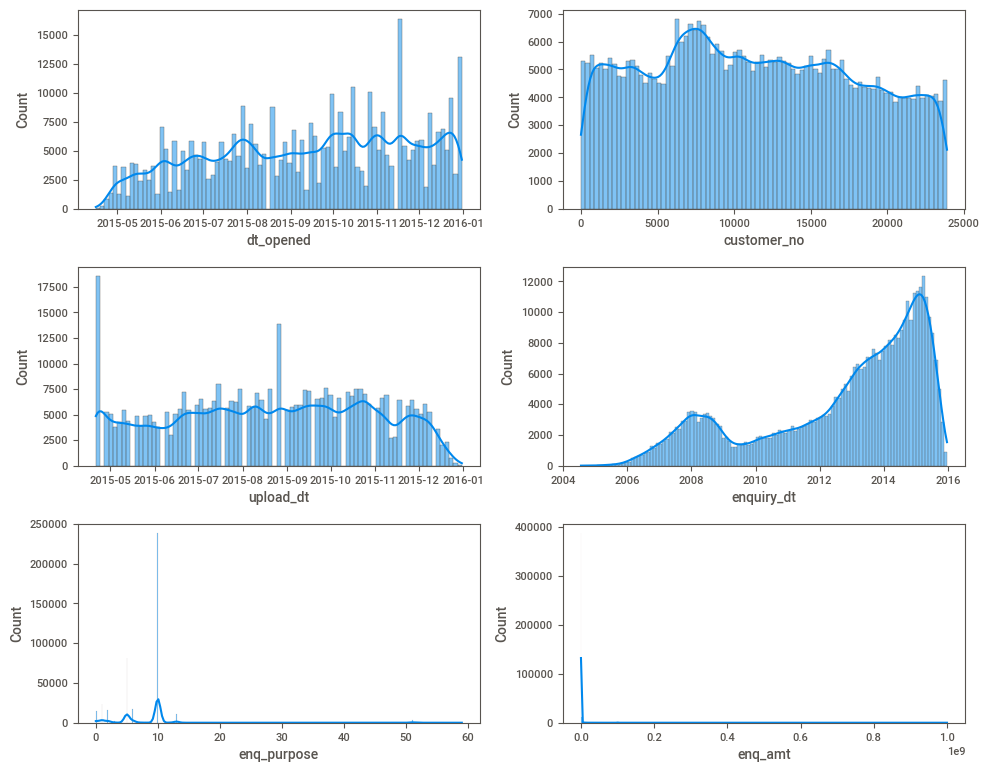

In [79]:
plt.figure(figsize=(10,10))
for i,col in enumerate(ce,1):
    plt.subplot(4,2,i)
    sns.histplot(x=ce[col],kde=1)
plt.tight_layout()
plt.show()

#### Insights :

- `dt_opened`: Dates run from about April 2015 to January 2016. The count goes up over time, with some big spikes (the highest is around November 2015).
- `customer_no`: Almost uniform from 0 to ~24000. It is an ID column, so the shape means nothing for modeling.
- `upload_dt`: Same period as `dt_opened`. The count stays fairly flat, with a very big spike at the start and another around August 2015. It drops near the end.
- `enquiry_dt`: Dates go from about 2004 to 2016. Most enquiries are from recent years (2013 to 2015), so the data is left-skewed. There is a small bump around 2008.
- `enq_purpose`: Most of the values are 10, with a few at 5 and a very small number at other codes up to 60. It looks like a categorical code, not a numeric column.
- `enq_amt`: Very highly skewed. Almost all values are near 0, but the x-axis goes up to 1e9, so there are extreme outliers. The plot is not readable as it is.

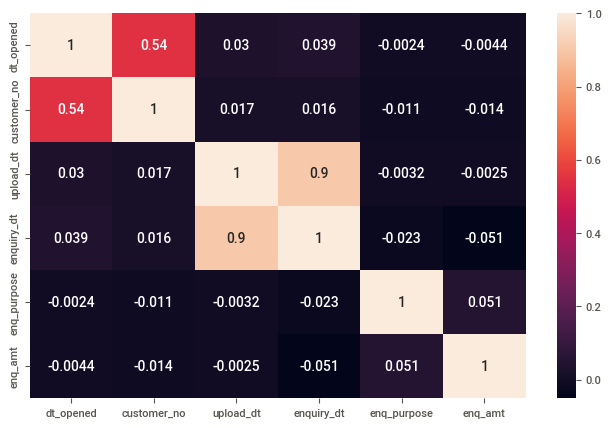

In [80]:
plt.figure(figsize=(8,5))
sns.heatmap(data=ce.corr(),annot=True)
plt.show()

#### Insight from `ce`: Correlation Heatmap 



- `upload_dt` and `enquiry_dt` have a very high correlation (0.9)
- `dt_opened` and `customer_no` have a moderate correlation (0.54)
- All other pairs are close to 0, so there is almost no linear relationship
- `enq_purpose` and `enq_amt` are not correlated with any other column

In [81]:
report_3=sv.analyze(ce)
report_3.show_html('report_3.html')

                                             |                                             | [  0%]   00:00 ->…

Report report_3.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


In [82]:
ce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413188 entries, 0 to 413187
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   dt_opened    413188 non-null  datetime64[ns]
 1   customer_no  413188 non-null  int64         
 2   upload_dt    413078 non-null  datetime64[ns]
 3   enquiry_dt   413078 non-null  datetime64[ns]
 4   enq_purpose  413078 non-null  float64       
 5   enq_amt      413078 non-null  float64       
dtypes: datetime64[ns](3), float64(2), int64(1)
memory usage: 18.9 MB


# After Data Preprosseing finally we got two tables : cad, cd2 

In [83]:
cad

,customer_no,acct_type,owner_indic,opened_dt,high_credit_amt,cur_balance_amt
0,12265.0,6.0,1.0,2013-06-09,20900.0,0.0
1,12265.0,10.0,1.0,2012-05-25,16201.0,10390.0
2,12265.0,10.0,1.0,2012-03-22,41028.0,34420.0
3,15606.0,10.0,1.0,2006-01-13,93473.0,0.0
4,15606.0,6.0,1.0,2015-01-18,20250.0,13500.0
...,...,...,...,...,...,...
186324,1611.0,10.0,1.0,2007-05-02,24228.0,24228.0
186325,1611.0,10.0,1.0,2007-04-11,19584.0,0.0
186326,1611.0,10.0,1.0,2006-11-20,50844.0,0.0
186327,1611.0,10.0,1.0,2006-10-17,35587.0,0.0


In [84]:
cd2

,customer_no,feature_1,feature_3,feature_4,feature_7,feature_11,feature_12,feature_14,feature_15,feature_16,feature_19,feature_23,feature_25,feature_26,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37,feature_38,feature_39,feature_40,feature_41,feature_42,feature_43,feature_44,feature_50,feature_51,feature_52,feature_55,feature_56,feature_58,feature_59,feature_60,feature_62,feature_63,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_70,feature_71,feature_72,feature_75,feature_76,feature_78,feature_79,Bad_label
0,1.0,Insignia,650.0,2.0,500000.0,Y,IS1,0.0,159,4284,1.0,N,1.0,2.0,400610.0,1965.0,0.0,Self,Y,2.0,90000.0,Private Ltd. Co.,Banking/Financial Services,MANAGER,0.0,0.0,0.0,0.0,Mumbai,400059.0,Y,State Bank of India,0.0,1.0,21.0,Y,Y,N,Y,1965-0,21.0,15.0,400610.0,0.0,2.0,90000.0,Nov-00,21.0,R,0000-00-00,0.0,1.0,N,0.0
1,2.0,Insignia,760.0,1.0,1200000.0,Y,IS1,0.0,91,B001,1.0,N,1.0,2.0,560042.0,1969.0,0.0,Self,Y,2.0,1.0,Private Ltd. Co.,Banking/Financial Services,MANAGER,0.0,0.0,0.0,0.0,Bangalore,560042.0,N,HDFC Bank,0.0,1.0,17.0,Y,Y,N,Y,1969-0,17.0,12.0,560042.0,0.0,2.0,1.0,Nov-00,17.0,R,0000-00-00,0.0,1.0,N,0.0
2,3.0,Insignia,774.0,1.0,700000.0,Y,IS1,0.0,91,B001,2.0,N,1.0,0.0,560042.0,1966.0,0.0,Self,Y,2.0,1.0,Private Ltd. Co.,Banking/Financial Services,MANAGER,0.0,0.0,0.0,0.0,Bangalore,560042.0,N,HDFC Bank,0.0,3.0,17.0,N,Y,N,Y,1966-0,17.0,12.0,560042.0,0.0,2.0,1.0,Nov-00,17.0,R,0000-00-00,0.0,1.0,N,0.0
3,4.0,Insignia,770.0,1.0,500000.0,Y,IS1,0.0,157,5107,1.0,N,1.0,3.0,411001.0,1988.0,0.0,Self,Y,2.0,100000.0,Private Ltd. Co.,Banking/Financial Services,MANAGER,0.0,0.0,0.0,0.0,Pune,411026.0,Y,HDFC Bank,0.0,1.0,21.0,Y,Y,N,Y,1988-0,21.0,16.0,411001.0,0.0,2.0,100000.0,Nov-00,21.0,R,6/15/65,1.0,1.0,N,0.0
4,5.0,Insignia,721.0,3.0,500000.0,Y,IS1,0.0,100,D016,1.0,N,1.0,3.0,122009.0,1995.0,0.0,Self,Y,2.0,300000.0,Private Ltd. Co.,Banking/Financial Services,MANAGER,0.0,0.0,0.0,0.0,Gurgaon,122009.0,N,HDFC Bank,0.0,1.0,13.0,Y,Y,N,Y,1995-0,13.0,3.0,122009.0,0.0,2.0,300000.0,Nov-00,13.0,R,0000-00-00,0.0,1.0,N,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23891,23892.0,Platinum Deligh,704.0,1.0,119000.0,Y,PD1,12.0,SA05,MA01,1.0,N,2.0,0.0,110045.0,1988.0,10.0,Paren,Y,1.0,33000.0,Private Ltd. Co.,Others,SERVICE ASSOCIATE,2015.0,6.0,0.0,6.0,Gurgaon,122001.0,Y,State Bank of India,99000.0,1.0,10.0,N,Y,N,Y,1988-10,10.0,157.0,110045.0,0.0,1.0,33000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,0.0
23892,23893.0,Platinum Deligh,721.0,2.0,35000.0,Y,PD1,12.0,SA03,AS33,1.0,N,2.0,0.0,110037.0,2014.0,12.0,Rente,N,1.0,1.0,Private Ltd. Co.,Others,ENGINEER,2012.0,12.0,3.0,0.0,New Delhi,110037.0,N,HDFC Bank,0.0,1.0,10.0,N,Y,N,Y,2014-12,33.0,102.0,282001.0,1.0,1.0,1.0,0-0,10.0,O,0000-00-00,0.0,1.0,N,0.0
23893,23894.0,Platinum Maxima,748.0,3.0,68000.0,Y,PM1,12.0,CD01,D066,1.0,Y,2.0,0.0,110033.0,1986.0,0.0,Paren,Y,1.0,1.0,Private Ltd. Co.,Health Care,SENIOR ANALYST,2015.0,1.0,3.0,0.0,Gurgaon,122016.0,Y,HDFC Bank,52000.0,1.0,10.0,N,Y,N,Y,1986-0,10.0,157.0,110033.0,0.0,1.0,1.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,0.0
23894,23895.0,Platinum Deligh,740.0,3.0,158000.0,Y,PD1,12.0,SA40,G011,1.0,N,1.0,0.0,110095.0,2010.0,0.0,Self,Y,2.0,25000.0,Private Ltd. Co.,Banking/Financial Services,MANAGER,0.0,0.0,0.0,0.0,New Delhi,110095.0,Y,Citibank N.A.,65000.0,2.0,10.0,N,Y,N,Y,2010-0,10.0,157.0,110095.0,0.0,2.0,25000.0,03-May,10.0,R,0000-00-00,0.0,1.0,N,0.0


# Adding those two table :

In [85]:
df=pd.merge(cad,cd2,on='customer_no',how='left',copy=False)

# Final data :

In [86]:
df

,customer_no,acct_type,owner_indic,opened_dt,high_credit_amt,cur_balance_amt,feature_1,feature_3,feature_4,feature_7,feature_11,feature_12,feature_14,feature_15,feature_16,feature_19,feature_23,feature_25,feature_26,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37,feature_38,feature_39,feature_40,feature_41,feature_42,feature_43,feature_44,feature_50,feature_51,feature_52,feature_55,feature_56,feature_58,feature_59,feature_60,feature_62,feature_63,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_70,feature_71,feature_72,feature_75,feature_76,feature_78,feature_79,Bad_label
0,12265.0,6.0,1.0,2013-06-09,20900.0,0.0,Platinum Maxima,683.0,3.0,56000.0,Y,PM1,12.0,SA05,MA01,1.0,N,1.0,0.0,110059.0,2006.0,0.0,Paren,Y,1.0,35000.0,Private Ltd. Co.,Others,SR EXE,2009.0,1.0,4.0,0.0,Gurgaon,122001.0,N,HDFC Bank,0.0,1.0,10.0,N,Y,N,Y,2006-0,10.0,157.0,110059.0,0.0,1.0,35000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,1.0
1,12265.0,10.0,1.0,2012-05-25,16201.0,10390.0,Platinum Maxima,683.0,3.0,56000.0,Y,PM1,12.0,SA05,MA01,1.0,N,1.0,0.0,110059.0,2006.0,0.0,Paren,Y,1.0,35000.0,Private Ltd. Co.,Others,SR EXE,2009.0,1.0,4.0,0.0,Gurgaon,122001.0,N,HDFC Bank,0.0,1.0,10.0,N,Y,N,Y,2006-0,10.0,157.0,110059.0,0.0,1.0,35000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,1.0
2,12265.0,10.0,1.0,2012-03-22,41028.0,34420.0,Platinum Maxima,683.0,3.0,56000.0,Y,PM1,12.0,SA05,MA01,1.0,N,1.0,0.0,110059.0,2006.0,0.0,Paren,Y,1.0,35000.0,Private Ltd. Co.,Others,SR EXE,2009.0,1.0,4.0,0.0,Gurgaon,122001.0,N,HDFC Bank,0.0,1.0,10.0,N,Y,N,Y,2006-0,10.0,157.0,110059.0,0.0,1.0,35000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,1.0
3,15606.0,10.0,1.0,2006-01-13,93473.0,0.0,Platinum Deligh,687.0,3.0,125000.0,Y,PD1,12.0,SA35,S001,1.0,N,1.0,2.0,121003.0,2009.0,0.0,Self,Y,1.0,100000.0,Private Ltd. Co.,Banking/Financial Services,GENRAL MANAGER OPERATIONS,2013.0,1.0,2.0,0.0,Faridabad,121003.0,N,HDFC Bank,0.0,1.0,13.0,N,Y,N,Y,2009-0,13.0,39.0,121003.0,0.0,1.0,100000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,1.0
4,15606.0,6.0,1.0,2015-01-18,20250.0,13500.0,Platinum Deligh,687.0,3.0,125000.0,Y,PD1,12.0,SA35,S001,1.0,N,1.0,2.0,121003.0,2009.0,0.0,Self,Y,1.0,100000.0,Private Ltd. Co.,Banking/Financial Services,GENRAL MANAGER OPERATIONS,2013.0,1.0,2.0,0.0,Faridabad,121003.0,N,HDFC Bank,0.0,1.0,13.0,N,Y,N,Y,2009-0,13.0,39.0,121003.0,0.0,1.0,100000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
186324,1611.0,10.0,1.0,2007-05-02,24228.0,24228.0,Titanium Deligh,746.0,3.0,138000.0,Y,TD1,0.0,BBOL,H004,1.0,N,1.0,3.0,500017.0,1995.0,0.0,Self,Y,1.0,45800.0,Private Ltd. Co.,Banking/Financial Services,MANAGER,1999.0,0.0,11.0,0.0,Hyderabad,500003.0,N,HDFC Bank,0.0,1.0,2.0,N,Y,N,Y,1995-0,2.0,14.0,500017.0,0.0,1.0,45800.0,0-0,2.0,R,0000-00-00,0.0,1.0,N,0.0
186325,1611.0,10.0,1.0,2007-04-11,19584.0,0.0,Titanium Deligh,746.0,3.0,138000.0,Y,TD1,0.0,BBOL,H004,1.0,N,1.0,3.0,500017.0,1995.0,0.0,Self,Y,1.0,45800.0,Private Ltd. Co.,Banking/Financial Services,MANAGER,1999.0,0.0,11.0,0.0,Hyderabad,500003.0,N,HDFC Bank,0.0,1.0,2.0,N,Y,N,Y,1995-0,2.0,14.0,500017.0,0.0,1.0,45800.0,0-0,2.0,R,0000-00-00,0.0,1.0,N,0.0
186326,1611.0,10.0,1.0,2006-11-20,50844.0,0.0,Titanium Deligh,746.0,3.0,138000.0,Y,TD1,0.0,BBOL,H004,1.0,N,1.0,3.0,500017.0,1995.0,0.0,Self,Y,1.0,45800.0,Private Ltd. Co.,Banking/Financial Services,MANAGER,1999.0,0.0,11.0,0.0,Hyderabad,500003.0,N,HDFC Bank,0.0,1.0,2.0,N,Y,N,Y,1995-0,2.0,14.0,500017.0,0.0,1.0,45800.0,0-0,2.0,R,0000-00-00,0.0,1.0,N,0.0
186327,1611.0,10.0,1.0,2006-10-17,35587.0,0.0,Titanium Deligh,746.0,3.0,138000.0,Y,TD1,0.0,BBOL,H004,1.0,N,1.0,3.0,500017.0,1995.0,0.0,Self,Y,1.0,45800.0,Private Ltd. Co.,Banking/Financial Services,MANAGER,1999.0,0.0,11.0,0.0,Hyderabad,500003.0,N,HDFC Bank,0.0,1.0,2.0,N,Y,N,Y,1995-0,2.0,14.0,50001

# Basic Checks of final data "df" :

In [87]:
df.head()

,customer_no,acct_type,owner_indic,opened_dt,high_credit_amt,cur_balance_amt,feature_1,feature_3,feature_4,feature_7,feature_11,feature_12,feature_14,feature_15,feature_16,feature_19,feature_23,feature_25,feature_26,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37,feature_38,feature_39,feature_40,feature_41,feature_42,feature_43,feature_44,feature_50,feature_51,feature_52,feature_55,feature_56,feature_58,feature_59,feature_60,feature_62,feature_63,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_70,feature_71,feature_72,feature_75,feature_76,feature_78,feature_79,Bad_label
0,12265.0,6.0,1.0,2013-06-09,20900.0,0.0,Platinum Maxima,683.0,3.0,56000.0,Y,PM1,12.0,SA05,MA01,1.0,N,1.0,0.0,110059.0,2006.0,0.0,Paren,Y,1.0,35000.0,Private Ltd. Co.,Others,SR EXE,2009.0,1.0,4.0,0.0,Gurgaon,122001.0,N,HDFC Bank,0.0,1.0,10.0,N,Y,N,Y,2006-0,10.0,157.0,110059.0,0.0,1.0,35000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,1.0
1,12265.0,10.0,1.0,2012-05-25,16201.0,10390.0,Platinum Maxima,683.0,3.0,56000.0,Y,PM1,12.0,SA05,MA01,1.0,N,1.0,0.0,110059.0,2006.0,0.0,Paren,Y,1.0,35000.0,Private Ltd. Co.,Others,SR EXE,2009.0,1.0,4.0,0.0,Gurgaon,122001.0,N,HDFC Bank,0.0,1.0,10.0,N,Y,N,Y,2006-0,10.0,157.0,110059.0,0.0,1.0,35000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,1.0
2,12265.0,10.0,1.0,2012-03-22,41028.0,34420.0,Platinum Maxima,683.0,3.0,56000.0,Y,PM1,12.0,SA05,MA01,1.0,N,1.0,0.0,110059.0,2006.0,0.0,Paren,Y,1.0,35000.0,Private Ltd. Co.,Others,SR EXE,2009.0,1.0,4.0,0.0,Gurgaon,122001.0,N,HDFC Bank,0.0,1.0,10.0,N,Y,N,Y,2006-0,10.0,157.0,110059.0,0.0,1.0,35000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,1.0
3,15606.0,10.0,1.0,2006-01-13,93473.0,0.0,Platinum Deligh,687.0,3.0,125000.0,Y,PD1,12.0,SA35,S001,1.0,N,1.0,2.0,121003.0,2009.0,0.0,Self,Y,1.0,100000.0,Private Ltd. Co.,Banking/Financial Services,GENRAL MANAGER OPERATIONS,2013.0,1.0,2.0,0.0,Faridabad,121003.0,N,HDFC Bank,0.0,1.0,13.0,N,Y,N,Y,2009-0,13.0,39.0,121003.0,0.0,1.0,100000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,1.0
4,15606.0,6.0,1.0,2015-01-18,20250.0,13500.0,Platinum Deligh,687.0,3.0,125000.0,Y,PD1,12.0,SA35,S001,1.0,N,1.0,2.0,121003.0,2009.0,0.0,Self,Y,1.0,100000.0,Private Ltd. Co.,Banking/Financial Services,GENRAL MANAGER OPERATIONS,2013.0,1.0,2.0,0.0,Faridabad,121003.0,N,HDFC Bank,0.0,1.0,13.0,N,Y,N,Y,2009-0,13.0,39.0,121003.0,0.0,1.0,100000.0,0-0,13.0,R,0000-00-00,0.0,1.0,N,1.0


In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186329 entries, 0 to 186328
Data columns (total 59 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   customer_no      186329 non-null  float64       
 1   acct_type        186329 non-null  float64       
 2   owner_indic      186329 non-null  float64       
 3   opened_dt        186329 non-null  datetime64[ns]
 4   high_credit_amt  186329 non-null  float64       
 5   cur_balance_amt  186329 non-null  float64       
 6   feature_1        186329 non-null  object        
 7   feature_3        186329 non-null  float64       
 8   feature_4        186329 non-null  float64       
 9   feature_7        186329 non-null  float64       
 10  feature_11       186329 non-null  object        
 11  feature_12       186329 non-null  object        
 12  feature_14       186329 non-null  float64       
 13  feature_15       186329 non-null  object        
 14  feature_16       186

In [89]:
df.describe()

,customer_no,acct_type,owner_indic,opened_dt,high_credit_amt,cur_balance_amt,feature_3,feature_4,feature_7,feature_14,feature_19,feature_25,feature_26,feature_29,feature_30,feature_31,feature_34,feature_35,feature_39,feature_40,feature_41,feature_42,feature_44,feature_52,feature_55,feature_56,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_71,feature_76,feature_78,Bad_label
count,186329.000000,186329.000000,186329.000000,186329,1.863290e+05,1.863290e+05,186329.000000,186329.000000,1.863290e+05,186329.000000,186329.000000,186329.000000,186329.000000,186329.000000,186329.000000,186329.000000,186329.000000,1.863290e+05,186329.000000,186329.000000,186329.000000,186329.000000,186329.000000,1.863290e+05,186329.000000,186329.000000,186329.000000,186329.000000,186329.000000,186329.000000,186329.000000,1.863290e+05,186329.000000,186329.000000,186329.000000,186329.000000
mean,11431.820447,8.403104,1.122128,2011-06-26 06:36:30.383676160,1.693999e+05,7.640269e+04,724.788170,2.318029,1.342520e+05,8.993318,1.039360,1.158784,0.853469,242928.848875,2000.285651,0.602359,1.281910,3.857267e+04,1446.395172,3.107664,5.966565,0.109677,246258.904953,8.346268e+04,1.070316,13.375513,14.247610,142.725641,274996.582067,0.137515,1.281910,3.857267e+04,14.278733,0.005463,1.040831,0.035491
min,1.000000,0.000000,1.000000,1979-10-01 00:00:00,1.000000e+00,-7.355205e+06,-1.000000,1.000000,0.000000e+00,0.000000,1.000000,1.000000,0.000000,110001.000000,1964.000000,0.000000,1.000000,1.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,1.000000,2.000000,2.000000,1.000000,110001.000000,0.000000,1.000000,1.000000e+00,2.000000,0.000000,1.000000,0.000000
25%,5879.000000,6.000000,1.000000,2008-06-16 00:00:00,2.400000e+04,0.000000e+00,702.000000,1.000000,8.000000e+04,0.000000,1.000000,1.000000,0.000000,110056.000000,1990.000000,0.000000,1.000000,1.000000e+00,0.000000,0.000000,0.000000,0.000000,110051.000000,0.000000e+00,1.000000,10.000000,10.000000,15.000000,110059.000000,0.000000,1.000000,1.000000e+00,10.000000,0.000000,1.000000,0.000000
50%,11169.000000,10.000000,1.000000,2012-10-31 00:00:00,4.522350e+04,0.000000e+00,721.000000,3.000000,1.140000e+05,12.000000,1.000000,1.000000,0.000000,121004.000000,2005.000000,0.000000,1.000000,3.500000e+04,2008.000000,1.000000,7.000000,0.000000,122002.000000,5.400000e+04,1.000000,10.000000,10.000000,157.000000,201001.000000,0.000000,1.000000,3.500000e+04,10.000000,0.000000,1.000000,0.000000
75%,16982.000000,10.000000,1.000000,2014-06-17 00:00:00,1.000000e+05,2.099800e+04,744.000000,3.000000,1.510000e+05,12.000000,1.000000,1.000000,2.000000,400089.000000,2011.000000,0.000000,2.000000,5.000000e+04,2012.000000,6.000000,11.000000,0.000000,400064.000000,1.130000e+05,1.000000,17.000000,21.000000,157.000000,411027.000000,0.000000,2.000000,5.000000e+04,21.000000,0.000000,1.000000,0.000000
max,23896.000000,59.000000,4.000000,2015-12-15 00:00:00,1.800000e+08,1.360100e+08,896.000000,3.000000,1.217000e+06,12.000000,2.000000,2.000000,10.000000,712245.000000,2015.000000,12.000000,3.000000,1.500000e+07,2015.000000,12.000000,11.000000,11.000000,712201.000000,3.777000e+06,4.000000,35.000000,35.000000,10008.000000,874401.000000,1.000000,3.000000,1.500000e+07,35.000000,4.000000,3.000000,1.000000
std,6730.432139,5.179466,0.567040,NaN,9.609389e+05,6.186783e+05,35.083123,0.901991,9.174343e+04,5.200018,0.194452,0.365475,1.172543,171131.312470,12.694417,2.251820,0.453637,1.028359e+05,902.523085,3.558750,4.483761,0.786696,168678.314544,1.259071e+05,0.359303,8.516766,9.370986,179.486002,196237.420443,0.344391,0.453637,1.028359e+05,9.091899,0.097642,0.220062,0.185018


**insights**
- The target variable Bad_label has a mean of 0.0355 (3.55%), indicating a severe class imbalance where only 3.5% of customers are default/bad cases.
- Financial columns like high_credit_amt and cur_balance_amt have massive gaps between their 75th percentiles (1,00,000 & 20,998) and maximum values (18 Crore & 13.6 Crore), showing extreme right skewness and outliers.
- Account opening dates range from 1979 to 2015 (median around Oct 2012), while last payment dates go up to Dec 2015, capturing over 35 years of historical credit activity.

In [90]:
df.isnull().sum()

customer_no        0
acct_type          0
owner_indic        0
opened_dt          0
high_credit_amt    0
cur_balance_amt    0
feature_1          0
feature_3          0
feature_4          0
feature_7          0
feature_11         0
feature_12         0
feature_14         0
feature_15         0
feature_16         0
feature_19         0
feature_23         0
feature_25         0
feature_26         0
feature_29         0
feature_30         0
feature_31         0
feature_32         0
feature_33         0
feature_34         0
feature_35         0
feature_36         0
feature_37         0
feature_38         0
feature_39         0
feature_40         0
feature_41         0
feature_42         0
feature_43         0
feature_44         0
feature_50         0
feature_51         0
feature_52         0
feature_55         0
feature_56         0
feature_58         0
feature_59         0
feature_60         0
feature_62         0
feature_63         0
feature_64         0
feature_65         0
feature_66   

In [91]:
df.duplicated().sum()

np.int64(3477)

In [92]:
max_unique = []
for i in df.iloc[:,:-2].columns :
    if df[i].value_counts().max() / len(df) * 100 >= 80 :
        max_unique.append(i)

In [93]:
len(df)*100

18632900

#### Insight : (columns having more than 80% Unique value)

- When we have features in a dataset where more than 80% of the values are unique, it might indicate that those features are not contributing meaningful information to our model. 
- Having a high number of unique values can lead to overfitting and make it difficult for the model to generalize well to unseen data.
- So we should drop those above columns.

In [94]:
df.drop(max_unique,axis=1,inplace=True)

In [95]:
df

,customer_no,acct_type,opened_dt,high_credit_amt,cur_balance_amt,feature_1,feature_3,feature_4,feature_7,feature_12,feature_14,feature_15,feature_16,feature_26,feature_29,feature_30,feature_32,feature_34,feature_35,feature_36,feature_38,feature_39,feature_40,feature_41,feature_43,feature_44,feature_50,feature_51,feature_52,feature_56,feature_63,feature_64,feature_65,feature_66,feature_68,feature_69,feature_70,feature_71,feature_72,feature_79,Bad_label
0,12265.0,6.0,2013-06-09,20900.0,0.0,Platinum Maxima,683.0,3.0,56000.0,PM1,12.0,SA05,MA01,0.0,110059.0,2006.0,Paren,1.0,35000.0,Private Ltd. Co.,SR EXE,2009.0,1.0,4.0,Gurgaon,122001.0,N,HDFC Bank,0.0,10.0,2006-0,10.0,157.0,110059.0,1.0,35000.0,0-0,13.0,R,N,1.0
1,12265.0,10.0,2012-05-25,16201.0,10390.0,Platinum Maxima,683.0,3.0,56000.0,PM1,12.0,SA05,MA01,0.0,110059.0,2006.0,Paren,1.0,35000.0,Private Ltd. Co.,SR EXE,2009.0,1.0,4.0,Gurgaon,122001.0,N,HDFC Bank,0.0,10.0,2006-0,10.0,157.0,110059.0,1.0,35000.0,0-0,13.0,R,N,1.0
2,12265.0,10.0,2012-03-22,41028.0,34420.0,Platinum Maxima,683.0,3.0,56000.0,PM1,12.0,SA05,MA01,0.0,110059.0,2006.0,Paren,1.0,35000.0,Private Ltd. Co.,SR EXE,2009.0,1.0,4.0,Gurgaon,122001.0,N,HDFC Bank,0.0,10.0,2006-0,10.0,157.0,110059.0,1.0,35000.0,0-0,13.0,R,N,1.0
3,15606.0,10.0,2006-01-13,93473.0,0.0,Platinum Deligh,687.0,3.0,125000.0,PD1,12.0,SA35,S001,2.0,121003.0,2009.0,Self,1.0,100000.0,Private Ltd. Co.,GENRAL MANAGER OPERATIONS,2013.0,1.0,2.0,Faridabad,121003.0,N,HDFC Bank,0.0,13.0,2009-0,13.0,39.0,121003.0,1.0,100000.0,0-0,13.0,R,N,1.0
4,15606.0,6.0,2015-01-18,20250.0,13500.0,Platinum Deligh,687.0,3.0,125000.0,PD1,12.0,SA35,S001,2.0,121003.0,2009.0,Self,1.0,100000.0,Private Ltd. Co.,GENRAL MANAGER OPERATIONS,2013.0,1.0,2.0,Faridabad,121003.0,N,HDFC Bank,0.0,13.0,2009-0,13.0,39.0,121003.0,1.0,100000.0,0-0,13.0,R,N,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
186324,1611.0,10.0,2007-05-02,24228.0,24228.0,Titanium Deligh,746.0,3.0,138000.0,TD1,0.0,BBOL,H004,3.0,500017.0,1995.0,Self,1.0,45800.0,Private Ltd. Co.,MANAGER,1999.0,0.0,11.0,Hyderabad,500003.0,N,HDFC Bank,0.0,2.0,1995-0,2.0,14.0,500017.0,1.0,45800.0,0-0,2.0,R,N,0.0
186325,1611.0,10.0,2007-04-11,19584.0,0.0,Titanium Deligh,746.0,3.0,138000.0,TD1,0.0,BBOL,H004,3.0,500017.0,1995.0,Self,1.0,45800.0,Private Ltd. Co.,MANAGER,1999.0,0.0,11.0,Hyderabad,500003.0,N,HDFC Bank,0.0,2.0,1995-0,2.0,14.0,500017.0,1.0,45800.0,0-0,2.0,R,N,0.0
186326,1611.0,10.0,2006-11-20,50844.0,0.0,Titanium Deligh,746.0,3.0,138000.0,TD1,0.0,BBOL,H004,3.0,500017.0,1995.0,Self,1.0,45800.0,Private Ltd. Co.,MANAGER,1999.0,0.0,11.0,Hyderabad,500003.0,N,HDFC Bank,0.0,2.0,1995-0,2.0,14.0,500017.0,1.0,45800.0,0-0,2.0,R,N,0.0
186327,1611.0,10.0,2006-10-17,35587.0,0.0,Titanium Deligh,746.0,3.0,138000.0,TD1,0.0,BBOL,H004,3.0,500017.0,1995.0,Self,1.0,45800.0,Private Ltd. Co.,MANAGER,1999.0,0.0,11.0,Hyderabad,500003.0,N,HDFC Bank,0.0,2.0,1995-0,2.0,14.0,500017.0,1.0,45800.0,0-0,2.0,R,N,0.0


# EDA(Explopratory data analysis) of Final data :

## univariate :

In [96]:
num = df.select_dtypes(include='number')
obj = df.select_dtypes(include='O')

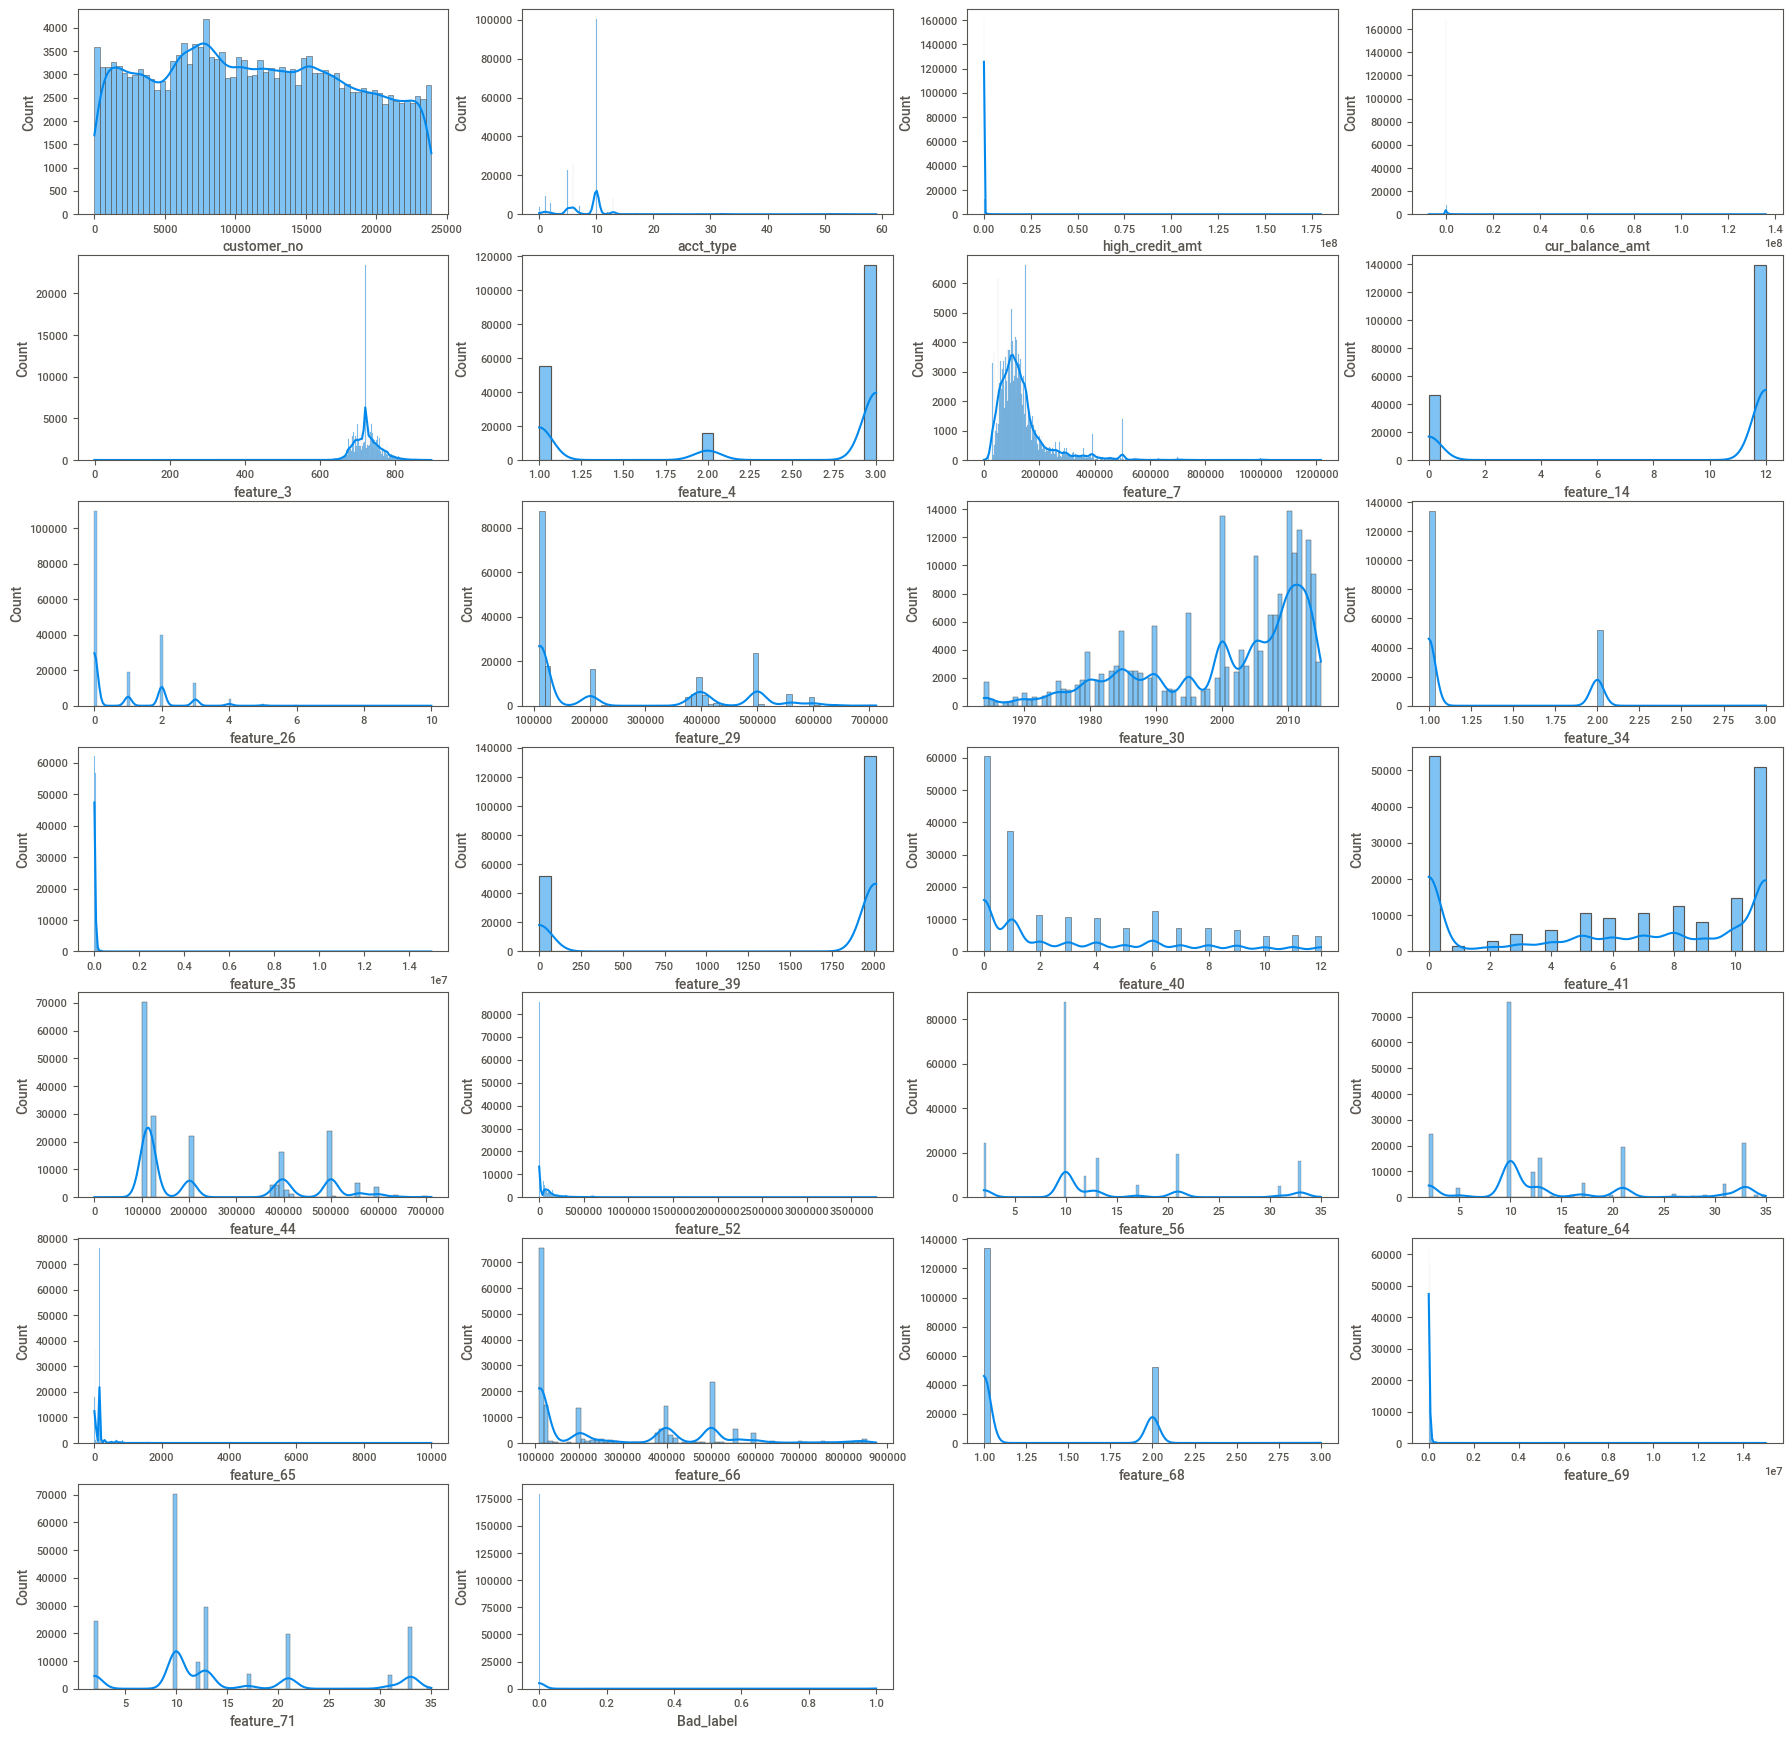

In [97]:
plt.figure(figsize=(22,25))
for i,col in enumerate(num,1):
    plt.subplot(8,4,i)
    sns.histplot(x=df[col],kde=1)
plt.show()

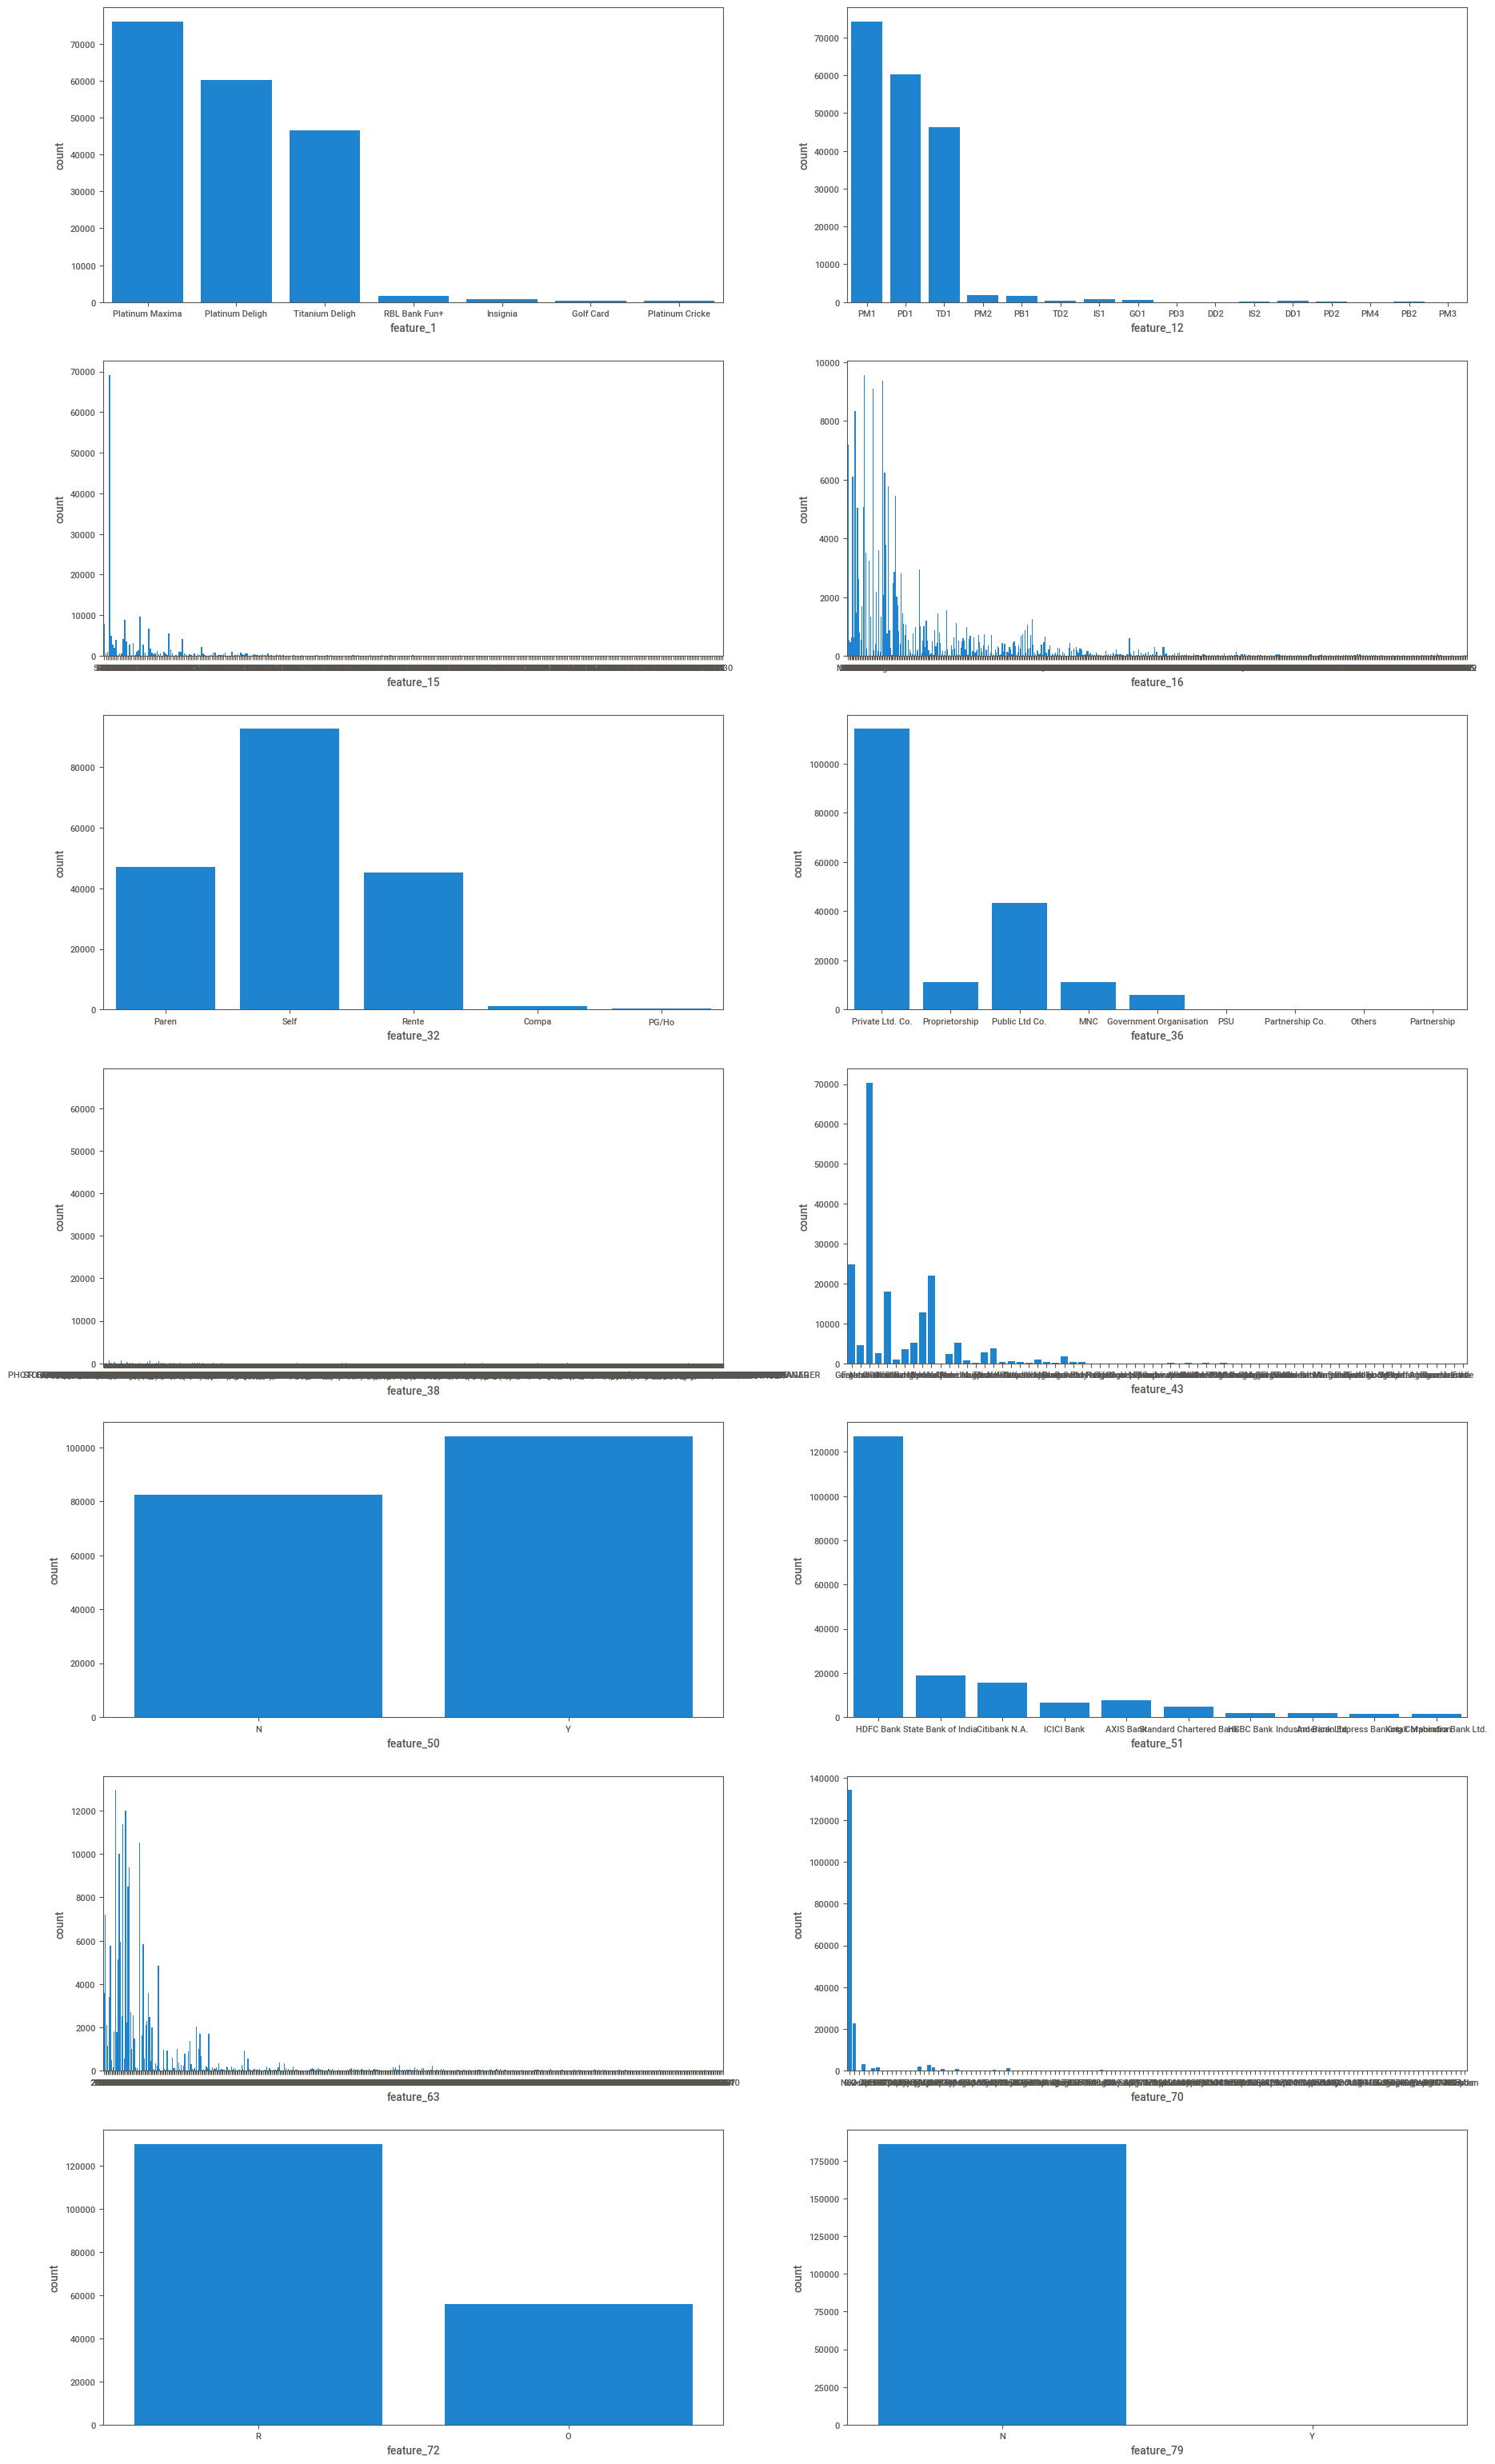

In [98]:
plt.figure(figsize=(22,45))
for j,cols in enumerate(obj,1):
    plt.subplot(8,2,j)
    sns.countplot(x=df[cols])
plt.show()

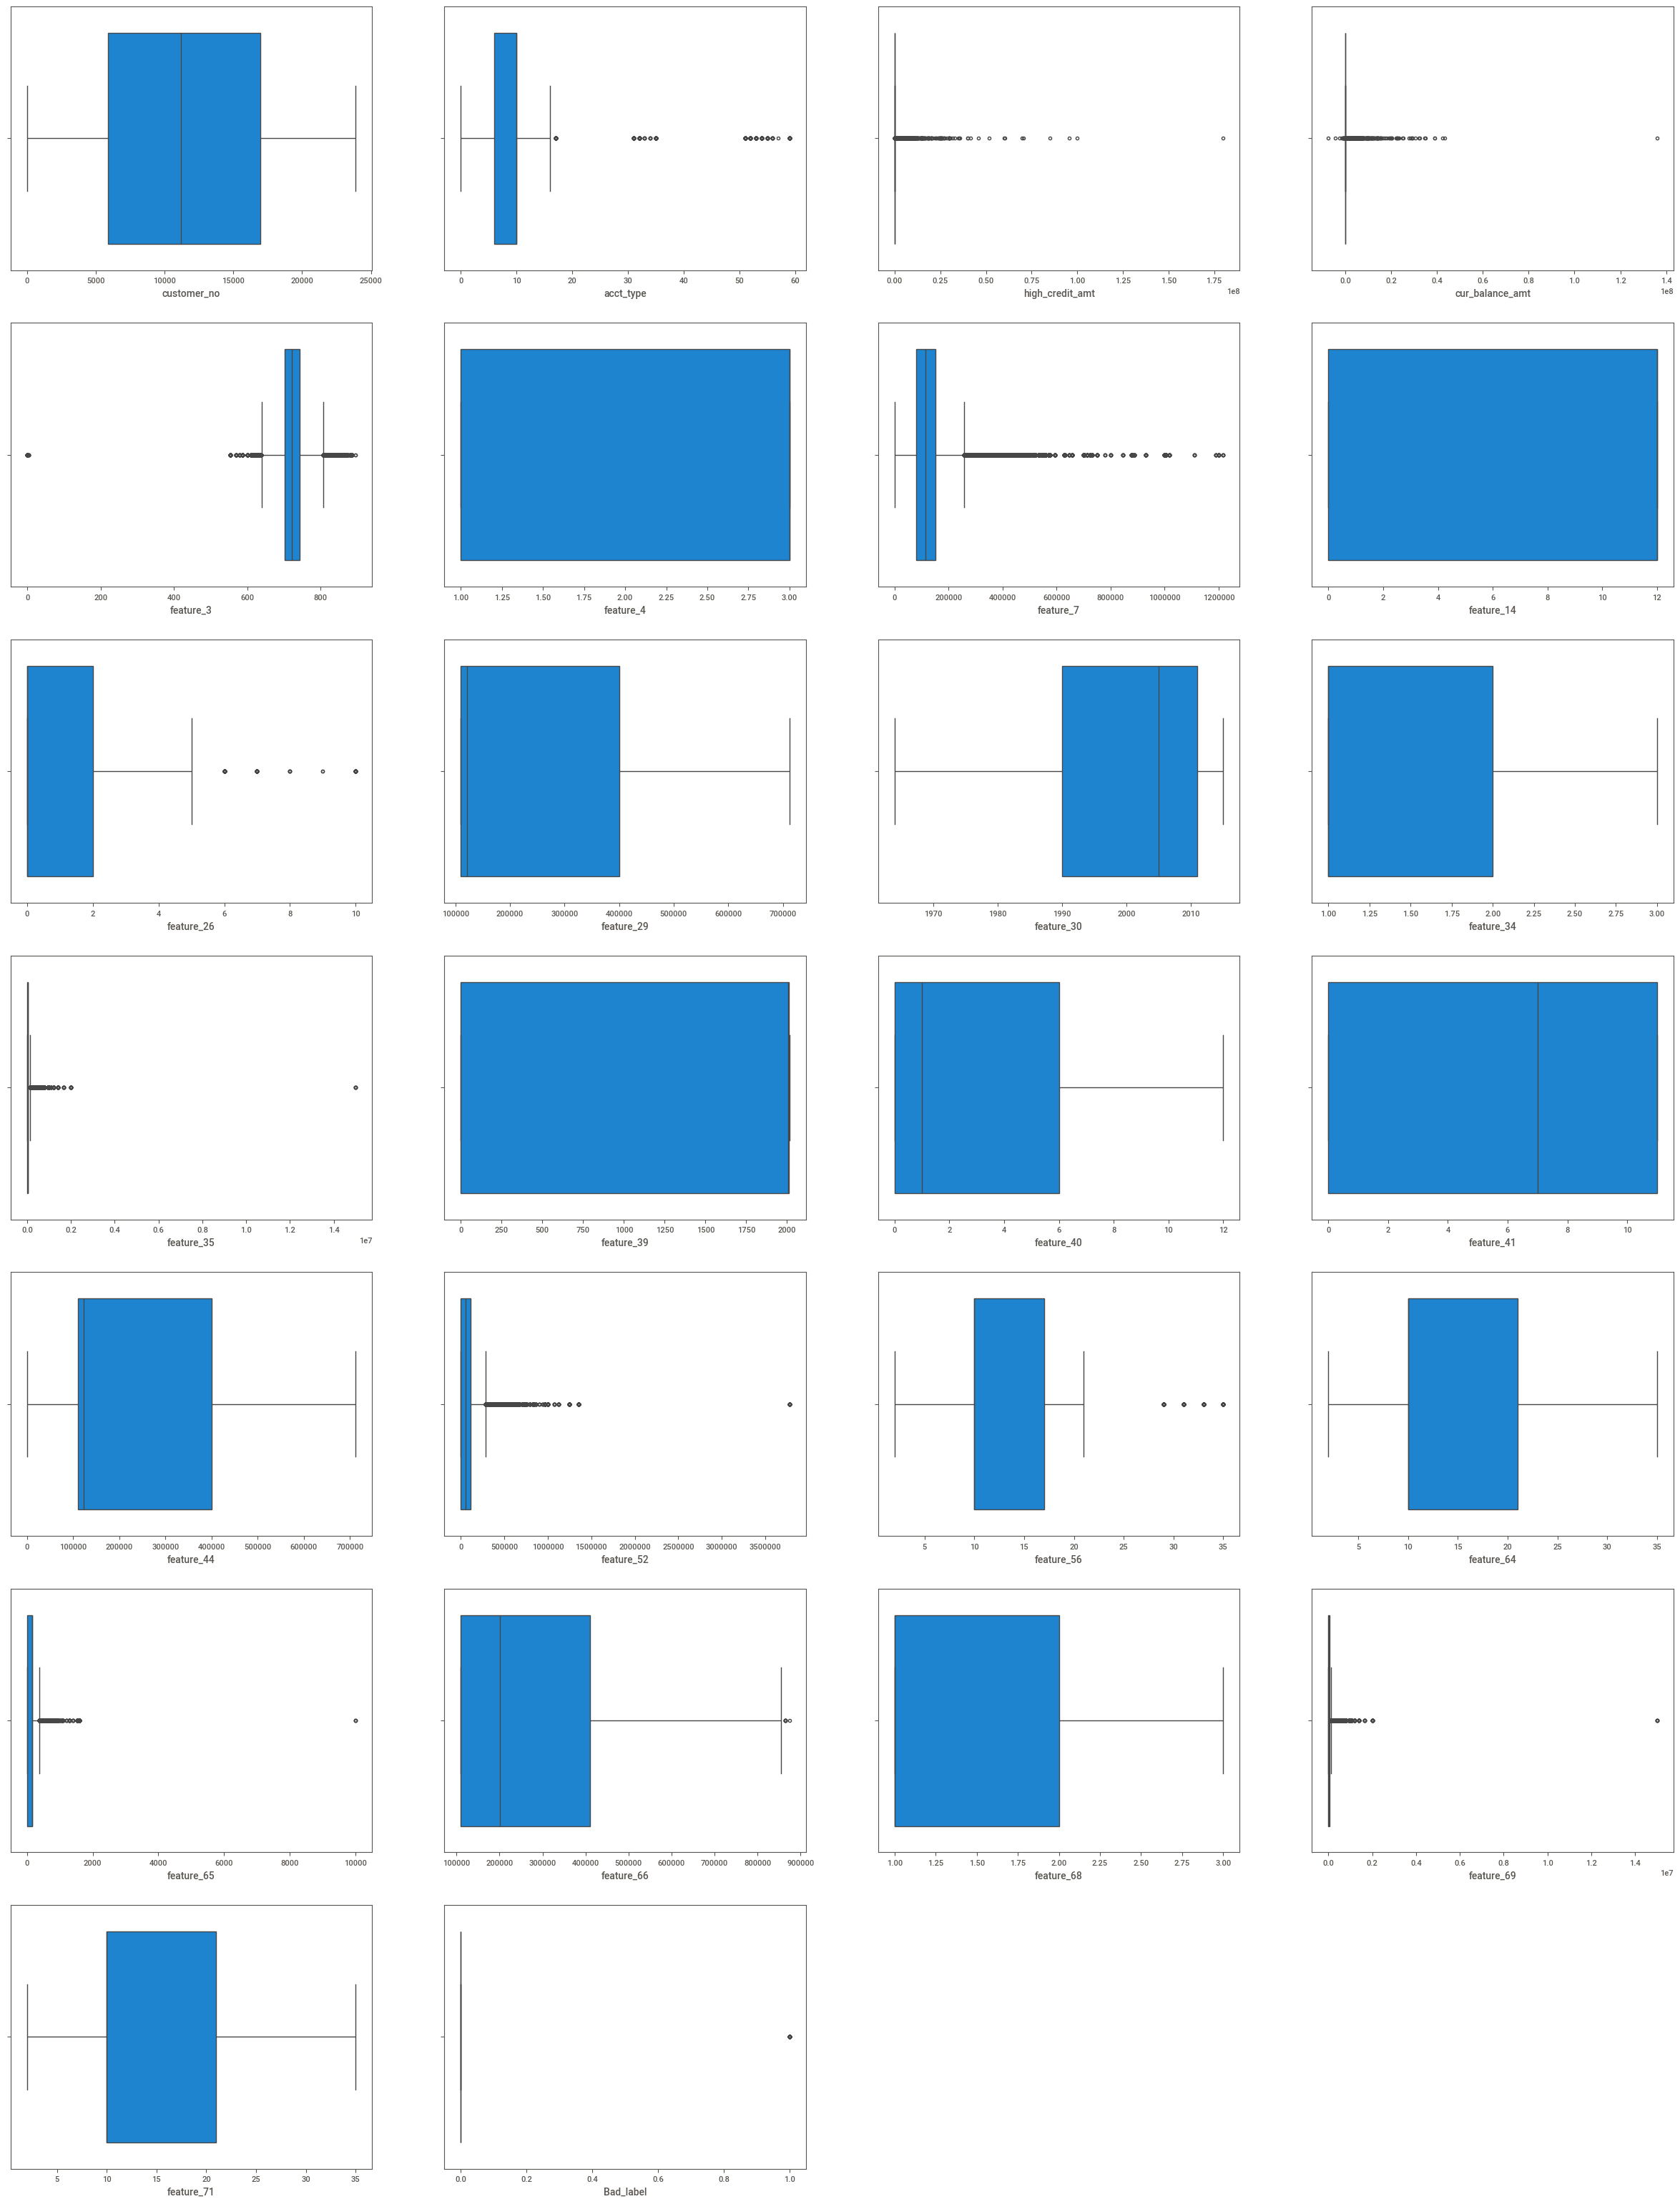

In [99]:
plt.figure(figsize=(30,45))
for k,column in enumerate(num,1):
    plt.subplot(8,4,k)
    sns.boxplot(x=df[column])
plt.show()

## bivariate analysis :

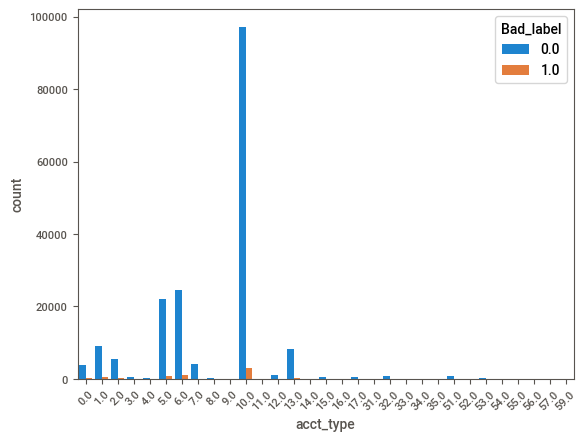

In [100]:
sns.countplot(data=df,x=df.acct_type,hue=df.Bad_label)
plt.xticks(rotation=45)
plt.show()

#### Insights from Bivariate Analysis: `acct_type` vs `Bad_label`

- Most of the accounts are `acct_type` 10 (about 97,000), then 6, 5 and 1
- Most of the other account types have very small counts
- Bad customers (`Bad_label` = 1) are very few in every account type, which shows the data is imbalanced
- The orange bars are only visible for a few types like 10, 6 and 5

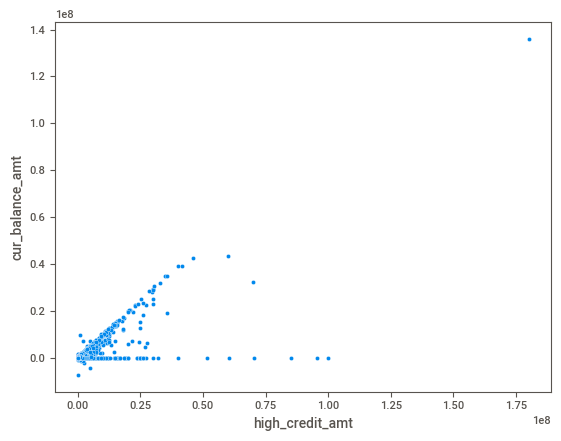

In [101]:
sns.scatterplot(data=df,x=df.high_credit_amt,y=df.cur_balance_amt)
plt.show()

#### Insights from Bivariate Analysis: `high_credit_amt` vs `cur_balance_amt`

- Positive relationship: when the high credit amount goes up, the current balance also goes up
- Most of the points are near 0, so most customers have small amounts
- Many points sit on the line where `cur_balance_amt` = 0, even for large credit amounts
- One extreme outlier is at about 1.8e8 credit and 1.35e8 balance
- A few points have a negative balance

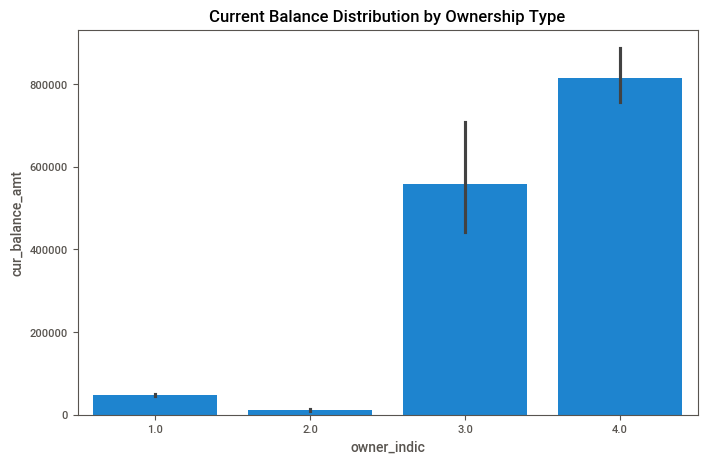

In [102]:
plt.figure(figsize=(8, 5))
sns.barplot(data=cad, x='owner_indic', y='cur_balance_amt')
plt.title('Current Balance Distribution by Ownership Type')
plt.show()

#### Insights from Bivariate Analysis: `owner_indic` vs `cur_balance_amt`

- Owner types 3 and 4 have a much higher average current balance than types 1 and 2
- Type 4 is the highest (about 800,000), then type 3 (about 560,000)
- Types 1 and 2 are very low (about 50,000 and 10,000)
- Type 3 has a long error bar, so its balance varies a lot

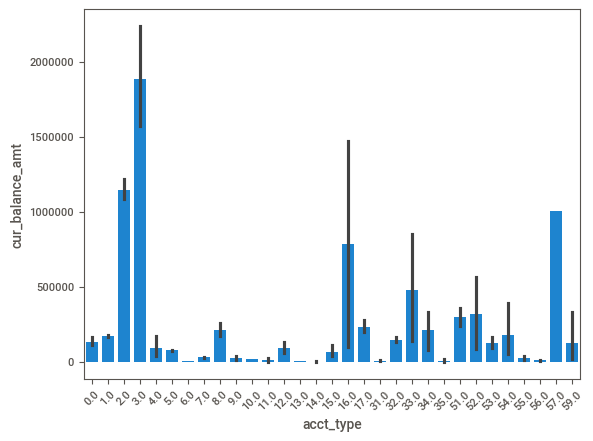

In [103]:
sns.barplot(data=df,x='acct_type',y='cur_balance_amt',estimator='mean')
plt.xticks(rotation=45)
plt.show()

#### Insights from Bivariate Analysis: `acct_type` vs `cur_balance_amt`

- Account type 3 has the highest average balance (about 1.9 million), then type 2 (about 1.15 million) and type 57 (about 1 million)
- Type 16 and type 33 also have high averages, but with very long error bars
- Most of the other account types have a low average balance, under 300,000
- Some types are almost 0

# Multivariate  Analysis :

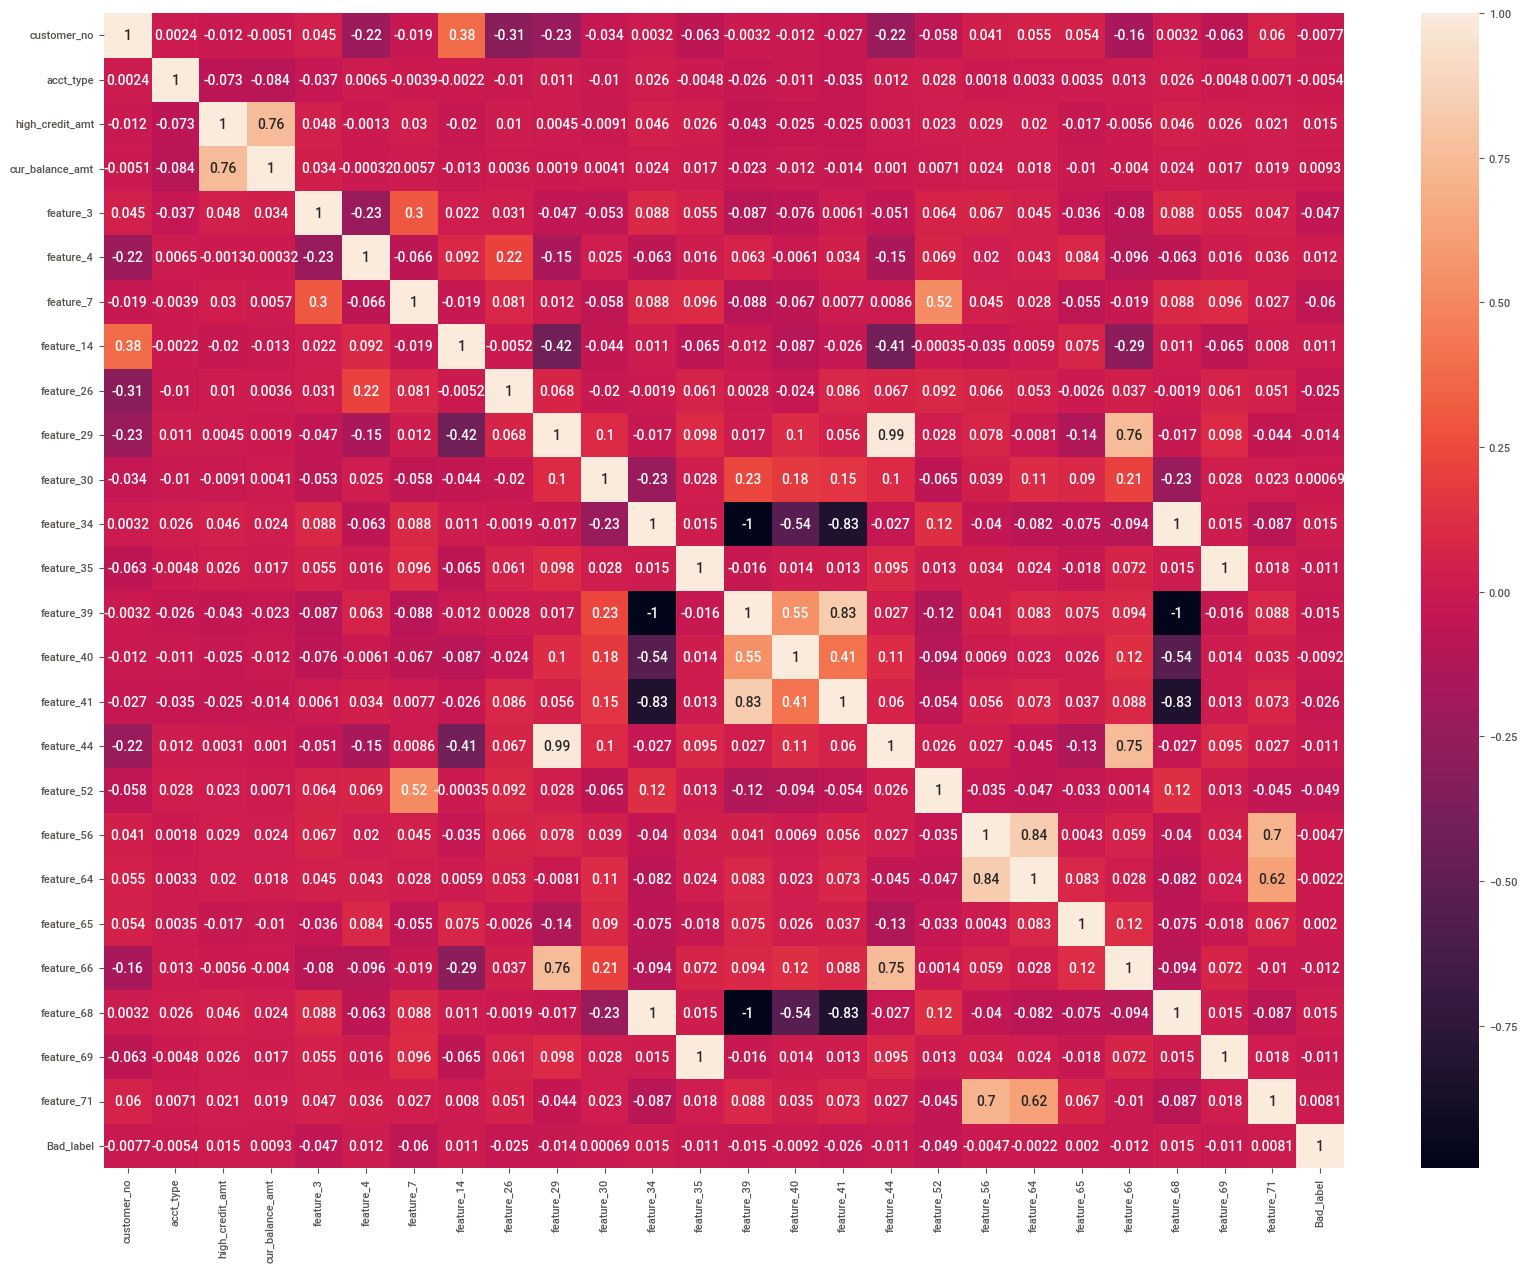

In [104]:
plt.figure(figsize=(20,15))
sns.heatmap(data=df.corr(numeric_only=True),annot=True)
plt.show()

#### Insights from `df`: Correlation Heatmap

- `high_credit_amt` and `cur_balance_amt` have a high correlation (0.76)
- `feature_29` and `feature_44` are almost the same (0.99). Both also correlate with `feature_66` (0.76 and 0.75)
- `feature_34`, `feature_39` and `feature_68` are perfectly correlated with each other (1 or -1), so they carry the same information
- `feature_41` is also strongly related to `feature_34`, `feature_39` and `feature_68` (0.83 or -0.83)
- `feature_35` and `feature_69` have a perfect correlation (1)
- `feature_56` and `feature_64` have a high correlation (0.84), and both are also related to the last column (0.7 and 0.62)
- `feature_7` and `feature_52` have a moderate correlation (0.52)
- All other pairs are close to 0, so there is almost no linear relationship
- Multicollinearity is present, so some of these columns can be dropped

# Data Splitting :

#### Split the data into input(x) and output(y):

In [105]:
# Account age in years from opened_dt
df['Years_old_acc'] = [(pd.Timestamp.now() - date).days / 365.25 for date in df['opened_dt']]

In [106]:
# Credit utilization ratio
df['credit_utilization_ratio'] = df['cur_balance_amt'] / (df['high_credit_amt'] + 1)

In [107]:
# Drop redundant columns
df = df.drop(['feature_29','feature_39','feature_56','feature_68','feature_41','feature_69','opened_dt','customer_no'], axis=1)

X = df.drop('Bad_label', axis=1)
y = df.Bad_label

#### Split the data into train and test :

In [108]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=43)
len(x_train),len(x_test),len(y_train),len(y_test)

(149063, 37266, 149063, 37266)

# Data preprocessing :

#### Null value imputation :

In [111]:
df.isnull().sum()

acct_type                   0
high_credit_amt             0
cur_balance_amt             0
feature_1                   0
feature_3                   0
feature_4                   0
feature_7                   0
feature_12                  0
feature_14                  0
feature_15                  0
feature_16                  0
feature_26                  0
feature_30                  0
feature_32                  0
feature_34                  0
feature_35                  0
feature_36                  0
feature_38                  0
feature_40                  0
feature_43                  0
feature_44                  0
feature_50                  0
feature_51                  0
feature_52                  0
feature_63                  0
feature_64                  0
feature_65                  0
feature_66                  0
feature_70                  0
feature_71                  0
feature_72                  0
feature_79                  0
Bad_label                   0
Years_old_

#### Handling Outliers :

In [112]:
o_col=['acct_type','high_credit_amt','cur_balance_amt','feature_3','feature_7','feature_26',
       'feature_35','feature_52','feature_65','feature_66','Years_old_acc','credit_utilization_ratio']
for i in o_col:
    Q1=x_train[i].quantile(0.25)
    Q3=x_train[i].quantile(0.75)
    IQR=Q3-Q1

    ub=Q3+1.5*IQR
    lb=Q1-1.5*IQR

    x_train[i]=x_train[i].clip(upper=ub,lower=lb)
    x_test[i]=x_test[i].clip(upper=ub,lower=lb)

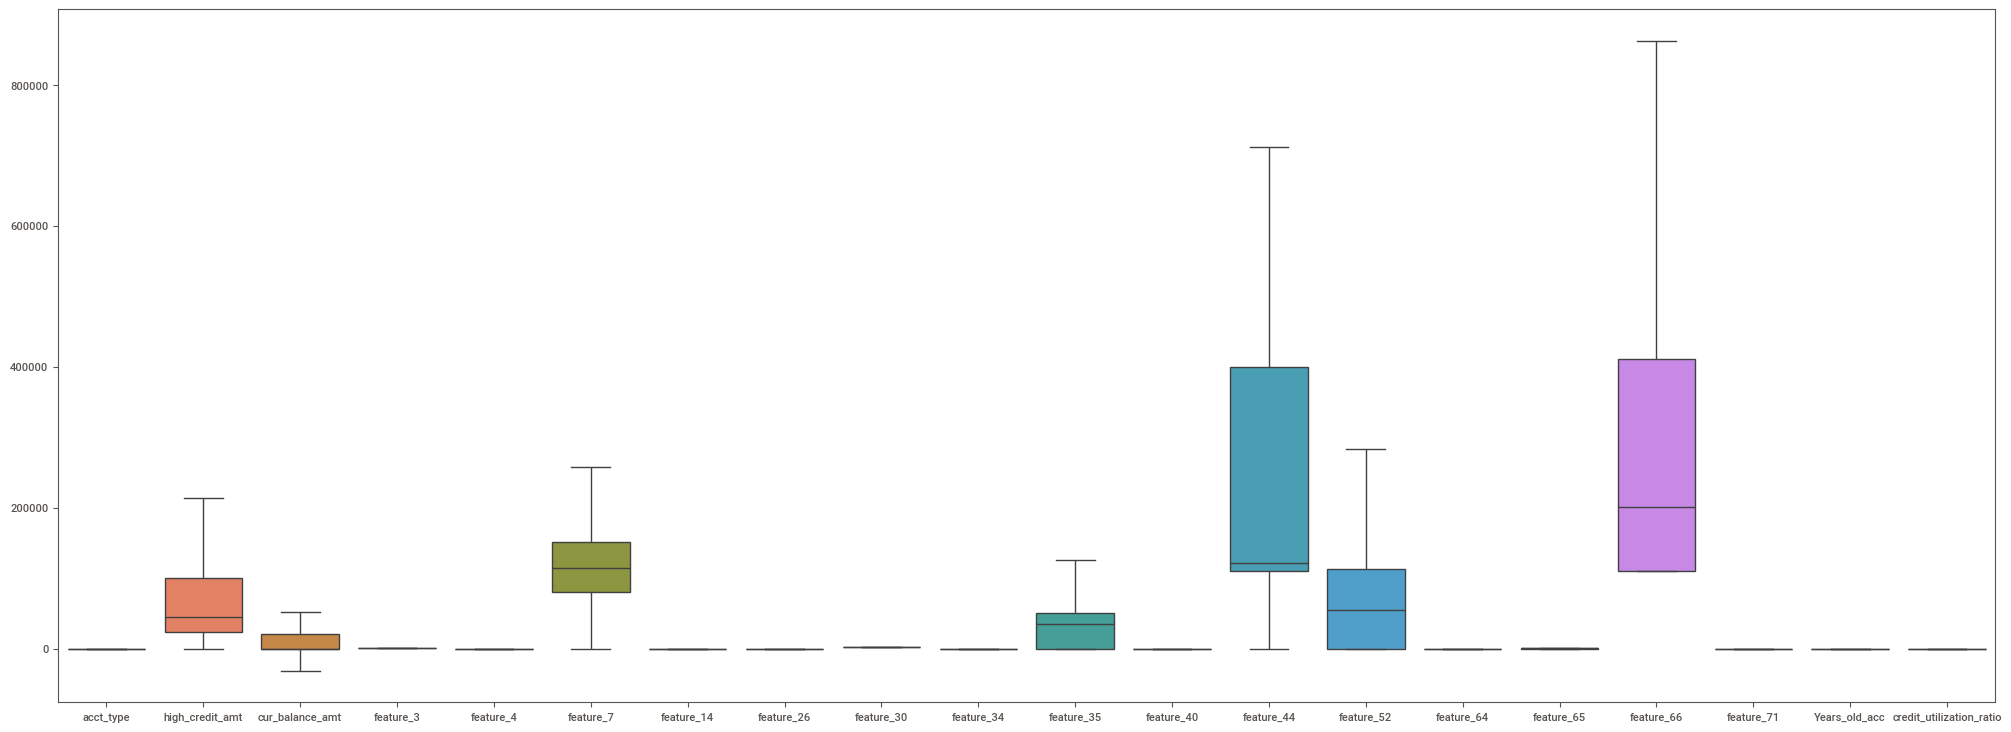

In [113]:
plt.figure(figsize=(25,9))
sns.boxplot(data=x_train.select_dtypes(include='number'))
plt.show()

#### Insights from `x_train`: Boxplot After Outlier Handling

- No outlier points are visible now, so the capping worked
- `feature_44` and `feature_66` have the widest range (up to about 700,000 and 860,000)
- `feature_66` has a median of about 200,000 and `feature_44` has a median of about 120,000
- In both, the median is closer to the lower part of the box, so they are still right-skewed
- `high_credit_amt`, `feature_7`, `feature_35` and `feature_52` have small to medium boxes, with a median below 120,000
- `cur_balance_amt` has some negative values (lower whisker below 0)
- Many columns look like a flat line near 0, because their scale is very small compared to the others

In [114]:
skewed=[]
for i in x_train.select_dtypes(include='number'):
    print(f'{i}==>{x_train[i].skew()}')
    if x_train[i].skew()>0.1:
        skewed.append(i)

acct_type==>-0.6269891760697046
high_credit_amt==>1.0846676302563516
cur_balance_amt==>1.2079069915275968
feature_3==>0.3159753727199296
feature_4==>-0.6648808222526608
feature_7==>0.7574561867149625
feature_14==>-1.148270248898108
feature_26==>1.1366455907927868
feature_30==>-0.9040943484262447
feature_34==>1.0206661195310884
feature_35==>0.9087239926992379
feature_40==>0.9991899715353526
feature_44==>0.7836420434827045
feature_52==>1.1000019193477466
feature_64==>0.8807132548831699
feature_65==>0.8503009603546406
feature_66==>0.9068243562046012
feature_71==>0.9243646396642977
Years_old_acc==>0.9323643123782533
credit_utilization_ratio==>0.9862769181936594


In [115]:
skewed

['high_credit_amt',
 'cur_balance_amt',
 'feature_3',
 'feature_7',
 'feature_26',
 'feature_34',
 'feature_35',
 'feature_40',
 'feature_44',
 'feature_52',
 'feature_64',
 'feature_65',
 'feature_66',
 'feature_71',
 'Years_old_acc',
 'credit_utilization_ratio']

In [116]:
from sklearn.preprocessing import PowerTransformer
pt=PowerTransformer(method='yeo-johnson')

In [117]:
x_train[skewed]=pt.fit_transform(x_train[skewed])
x_test[skewed]=pt.transform(x_test[skewed])

# Encoding :

In [118]:
for i in df.select_dtypes(include='O'):
    print(f"--- Column: {i} ---")
    print(df[i].value_counts())
    print("\n")

--- Column: feature_1 ---
feature_1
Platinum Maxima    76147
Platinum Deligh    60321
Titanium Deligh    46557
RBL Bank Fun+       1644
Insignia             874
Golf Card            465
Platinum Cricke      321
Name: count, dtype: int64


--- Column: feature_12 ---
feature_12
PM1    74293
PD1    60170
TD1    46212
PM2     1835
PB1     1587
IS1      750
GO1      465
TD2      346
DD1      297
PD2      150
IS2      124
PB2       57
DD2       24
PM3       16
PM4        2
PD3        1
Name: count, dtype: int64


--- Column: feature_15 ---
feature_15
SA03    69124
HA03     9568
SA01     8961
SA05     7859
W01      6648
        ...  
79          1
5           1
CD02        1
SA45        1
DA30        1
Name: count, Length: 364, dtype: int64


--- Column: feature_16 ---
feature_16
AS19    9562
AS03    9382
AS16    9106
AS17    8340
MA01    7190
        ... 
D026       1
6886       1
LS01       1
RV01       1
VO03       1
Name: count, Length: 522, dtype: int64


--- Column: feature_32 ---
featu

In [119]:
binary_col=['feature_50','feature_72','feature_79']
for col in binary_col:
    unique_vals=x_train[col].unique()
    x_train[col]=x_train[col].map({unique_vals[0]:1, unique_vals[1]: 0})
    x_test[col]=x_test[col].map({unique_vals[0]:1, unique_vals[1]: 0})

In [120]:
x_train[binary_col]

,feature_50,feature_72,feature_79
114537,1,1,1
31795,0,1,1
156816,0,1,1
77348,0,1,1
52880,1,1,1
...,...,...,...
129082,1,0,1
125205,1,1,1
40753,1,0,1
150848,1,1,1


In [121]:
from sklearn.preprocessing import OneHotEncoder
ohe_col=['feature_1','feature_12','feature_32','feature_36','feature_51']
ohe=OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore')
train_ohe=ohe.fit_transform(x_train[ohe_col])
train_ohe_df=pd.DataFrame(train_ohe,columns=ohe.get_feature_names_out(ohe_col),index=x_train.index)

test_ohe=ohe.transform(x_test[ohe_col])
test_ohe_df=pd.DataFrame(test_ohe,columns=ohe.get_feature_names_out(ohe_col),index=x_test.index)

x_train=x_train.drop(columns=ohe_col)
x_train=pd.concat([x_train,train_ohe_df],axis=1)

x_test=x_test.drop(columns=ohe_col)
x_test=pd.concat([x_test,test_ohe_df],axis=1)

In [122]:
high_card_cols = ['feature_15', 'feature_16', 'feature_38', 'feature_43', 'feature_63', 'feature_70']

for col in high_card_cols:
 
    freq_map = x_train[col].value_counts(normalize=True).to_dict()
    

    x_train[col] = x_train[col].map(freq_map).fillna(0)
    x_test[col] = x_test[col].map(freq_map).fillna(0)

# Scaling :

In [123]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()

In [124]:
numeric_col=x_train.select_dtypes(include='number').columns
x_train[numeric_col]=sc.fit_transform(x_train[numeric_col])
x_test[numeric_col]=sc.transform(x_test[numeric_col])

# Balancing :

In [126]:
df.Bad_label.value_counts()

Bad_label
0.0    179716
1.0      6613
Name: count, dtype: int64

In [127]:
from imblearn.over_sampling import SMOTE
smote=SMOTE()

In [128]:
x_train_smote,y_train_smote=smote.fit_resample(x_train,y_train)

In [129]:
from collections import Counter
print('actual classes',Counter(y_train))
print('smote classes',Counter(y_train_smote))

actual classes Counter({0.0: 143784, 1.0: 5279})
smote classes Counter({0.0: 143784, 1.0: 143784})


# Model building & Evaluation :

In [130]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(random_state=43)
model.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,43
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [131]:
y_pred=model.predict(x_test)
y_pred_train=model.predict(x_train_smote)

In [132]:
from sklearn.metrics import classification_report,f1_score,precision_score,accuracy_score,roc_auc_score

# Test set metrics
test_accuracy = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred)
test_roc_auc=roc_auc_score(y_test,y_pred)
test_report = classification_report(y_test, y_pred)

# Train set metrics
train_accuracy = accuracy_score(y_train_smote, y_pred_train)
train_f1 = f1_score(y_train_smote, y_pred_train)
train_precision = precision_score(y_train_smote, y_pred_train)
train_roc_auc=roc_auc_score(y_train_smote,y_pred_train)
train_report = classification_report(y_train_smote, y_pred_train)

# Print test results
print('test accuracy:', test_accuracy)
print('test f1_score:', test_f1)
print('test precision_score:', test_precision)
print('test_roc_auc_score:',test_roc_auc)
print('test classification_report:\n', test_report)

print('\ntrain accuracy:', train_accuracy)
print('train f1_score:', train_f1)
print('train precision_score:', train_precision)
print('train_roc_auc_score:',train_roc_auc)
print('train classification_report:\n', train_report)

test accuracy: 0.9642032952288949
test f1_score: 0.0
test precision_score: 0.0
test_roc_auc_score: 0.5
test classification_report:
               precision    recall  f1-score   support

         0.0       0.96      1.00      0.98     35932
         1.0       0.00      0.00      0.00      1334

    accuracy                           0.96     37266
   macro avg       0.48      0.50      0.49     37266
weighted avg       0.93      0.96      0.95     37266


train accuracy: 0.5000765036443554
train f1_score: 0.0003059677621239726
train precision_score: 1.0
train_roc_auc_score: 0.5000765036443554
train classification_report:
               precision    recall  f1-score   support

         0.0       0.50      1.00      0.67    143784
         1.0       1.00      0.00      0.00    143784

    accuracy                           0.50    287568
   macro avg       0.75      0.50      0.33    287568
weighted avg       0.75      0.50      0.33    287568



# K-Fold (Cross Validation Technique) : 

In [133]:
from sklearn.model_selection import KFold,cross_val_score

kf=KFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

score_lr=cross_val_score(model,x_train_smote,y_train_smote,cv=kf,scoring='accuracy')

In [134]:
print("logistic regression cv score:",score_lr)
print("logistic regression mean cv score:",score_lr.mean())
print("logistic regression std cv score",score_lr.std())

logistic regression cv score: [0.63780992 0.63746218 0.63619293 0.63686471 0.63832525]
logistic regression mean cv score: 0.6373309983306918
logistic regression std cv score 0.0007413157151852591


# decision tree :

In [135]:
from sklearn.tree import DecisionTreeClassifier
dtc=DecisionTreeClassifier(random_state=43)

In [136]:
dtc.fit(x_train_smote,y_train_smote)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,43
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [137]:
y_pred_dtc=dtc.predict(x_test)
y_pred_dtc_train=dtc.predict(x_train_smote)

In [138]:
test_accuracy_dtc = accuracy_score(y_test, y_pred_dtc)
test_f1_dtc = f1_score(y_test, y_pred_dtc)
test_precision_dtc = precision_score(y_test, y_pred_dtc)
test_roc_auc_dtc=roc_auc_score(y_test,y_pred_dtc)
test_report_dtc = classification_report(y_test, y_pred_dtc)

train_accuracy_dtc = accuracy_score(y_train_smote, y_pred_dtc_train)
train_f1_dtc = f1_score(y_train_smote, y_pred_dtc_train)
train_precision_dtc = precision_score(y_train_smote, y_pred_dtc_train)
train_roc_auc_dtc=roc_auc_score(y_train_smote,y_pred_dtc_train)
train_report_dtc = classification_report(y_train_smote, y_pred_dtc_train)

print('test accuracy:', test_accuracy_dtc)
print('test f1_score:', test_f1_dtc)
print('test precision_score:', test_precision_dtc)
print('test_roc_auc_score:',test_roc_auc_dtc)
print('test classification_report:\n', test_report_dtc)

print('\n\ntrain accuracy:', train_accuracy_dtc)
print('train f1_score:', train_f1_dtc)
print('train precision_score:', train_precision_dtc)
print('train_roc_auc_score:',train_roc_auc_dtc)
print('train classification_report:\n', train_report_dtc)

test accuracy: 0.9649814844630494
test f1_score: 0.5758856028599285
test precision_score: 0.5083189902467011
test_roc_auc_score: 0.8201586546702159
test classification_report:
               precision    recall  f1-score   support

         0.0       0.99      0.98      0.98     35932
         1.0       0.51      0.66      0.58      1334

    accuracy                           0.96     37266
   macro avg       0.75      0.82      0.78     37266
weighted avg       0.97      0.96      0.97     37266



train accuracy: 1.0
train f1_score: 1.0
train precision_score: 1.0
train_roc_auc_score: 1.0
train classification_report:
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00    143784
         1.0       1.00      1.00      1.00    143784

    accuracy                           1.00    287568
   macro avg       1.00      1.00      1.00    287568
weighted avg       1.00      1.00      1.00    287568



# K Fold(Cross validation Technique) :

In [139]:
score_dtc=cross_val_score(dtc,x_train_smote,y_train_smote,cv=kf,scoring='accuracy')

In [140]:
print('Logistic regression cv score:',score_dtc)
print('logistic regression mean cv score:',score_dtc.mean())
print('logistic regression std cv score:',score_dtc.std())

Logistic regression cv score: [0.97652745 0.97932677 0.97786626 0.98002191 0.97671831]
logistic regression mean cv score: 0.9780921401405406
logistic regression std cv score: 0.001388164493865256


# KFold (Cross validation Technique) :

In [185]:
score_xgb=cross_val_score(xgb,x_train_smote,y_train_smote,cv=kf,scoring='accuracy')

In [186]:
print('Logistic regression cv score:',score_xgb)
print('logistic regression mean cv score:',score_xgb.mean())
print('logistic regression std cv score:',score_xgb.std())

Logistic regression cv score: [0.97930939 0.98271725 0.97871823 0.98108254 0.98276911]
logistic regression mean cv score: 0.9809193026103241
logistic regression std cv score: 0.0016803356554711915


# Hyper perameter tuning :

In [187]:
param_grid_dtc={
    'min_samples_split':[2,3,4,5,6,7,8,9,11,23],
    'min_samples_leaf':[1,2,3,4,5,6,6,7,8,8,99],
    'criterion':['gini','entropy','log_loss'],
    'max_depth':[1,2,3,4,5,6,7,8,9,11],
    'max_features':['sqrt','log2',None],
    'splitter':['best','random']
}

In [188]:
from sklearn.model_selection import RandomizedSearchCV
grid_dtc=RandomizedSearchCV(dtc,param_distributions=param_grid_dtc,cv=7,verbose=True,scoring='accuracy',n_iter=30,n_jobs=-1)

In [189]:
grid_dtc.fit(x_train_smote,y_train_smote)

Fitting 7 folds for each of 30 candidates, totalling 210 fits


,estimator,DecisionTreeC...ndom_state=43)
,param_distributions,"{'criterion': ['gini', 'entropy', ...], 'max_depth': [1, 2, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,n_iter,30
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,7
,verbose,True
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [190]:
print(grid_dtc.best_params_)

{'splitter': 'best', 'min_samples_split': 5, 'min_samples_leaf': 5, 'max_features': None, 'max_depth': 11, 'criterion': 'log_loss'}


In [191]:
dt=DecisionTreeClassifier(splitter='random',min_samples_split=7,min_samples_leaf=5,max_features=None,max_depth=11,criterion='entropy')

In [192]:
dt.fit(x_train_smote,y_train_smote)

,criterion,'entropy'
,splitter,'random'
,max_depth,11
,min_samples_split,7
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [193]:
y_pred_dtct=dt.predict(x_test)
y_pred_dtct_train=dt.predict(x_train_smote)

In [194]:
test_accuracy_dtct = accuracy_score(y_test, y_pred_dtct)
test_f1_dtct = f1_score(y_test, y_pred_dtct)
test_precision_dtct = precision_score(y_test, y_pred_dtct)
test_roc_auc_dtct=roc_auc_score(y_test,y_pred_dtct)
test_report_dtct = classification_report(y_test, y_pred_dtct)

train_accuracy_dtct = accuracy_score(y_train_smote, y_pred_dtct_train)
train_f1_dtct = f1_score(y_train_smote, y_pred_dtct_train)
train_precision_dtct = precision_score(y_train_smote, y_pred_dtct_train)
train_roc_auc_dtct=roc_auc_score(y_train_smote,y_pred_dtct_train)
train_report_dtct = classification_report(y_train_smote, y_pred_dtct_train)

print('test accuracy:', test_accuracy_dtct)
print('test f1_score:', test_f1_dtct)
print('test precision_score:', test_precision_dtct)
print('test_roc_auc_score:',test_roc_auc_dtct)
print('test classification_report:\n', test_report_dtct)

print('\n\ntrain accuracy:', train_accuracy_dtct)
print('train f1_score:', train_f1_dtct)
print('train precision_score:', train_precision_dtct)
print('train_roc_auc_score:',train_roc_auc_dtct)
print('train classification_report:\n', train_report_dtct)

test accuracy: 0.6754950893575914
test f1_score: 0.14772006483895975
test precision_score: 0.08152469856087126
test_roc_auc_score: 0.7285071493530757
test classification_report:
               precision    recall  f1-score   support

         0.0       0.99      0.67      0.80     35932
         1.0       0.08      0.79      0.15      1334

    accuracy                           0.68     37266
   macro avg       0.53      0.73      0.47     37266
weighted avg       0.96      0.68      0.78     37266



train accuracy: 0.7532340176932065
train f1_score: 0.7717089177712007
train precision_score: 0.7179568527918782
train_roc_auc_score: 0.7532340176932065
train classification_report:
               precision    recall  f1-score   support

         0.0       0.80      0.67      0.73    143784
         1.0       0.72      0.83      0.77    143784

    accuracy                           0.75    287568
   macro avg       0.76      0.75      0.75    287568
weighted avg       0.76      0.75     

# Random forest :

In [195]:
from sklearn.ensemble import RandomForestClassifier
rfc=RandomForestClassifier(random_state=43)

In [196]:
rfc.fit(x_train_smote,y_train_smote)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [197]:
y_pred_rfc=rfc.predict(x_test)
y_pred_rfc_train=rfc.predict(x_train_smote)

In [198]:
test_accuracy_rfc = accuracy_score(y_test, y_pred_rfc)
test_f1_rfc = f1_score(y_test, y_pred_rfc)
test_precision_rfc = precision_score(y_test, y_pred_rfc)
test_roc_auc_rfc=roc_auc_score(y_test,y_pred_rfc)
test_report_rfc = classification_report(y_test, y_pred_rfc)

train_accuracy_rfc = accuracy_score(y_train_smote, y_pred_rfc_train)
train_f1_rfc = f1_score(y_train_smote, y_pred_rfc_train)
train_precision_rfc = precision_score(y_train_smote, y_pred_rfc_train)
train_roc_auc_rfc=roc_auc_score(y_train_smote,y_pred_rfc_train)
train_report_rfc = classification_report(y_train_smote, y_pred_rfc_train)

print('test accuracy:', test_accuracy_rfc)
print('test f1_score:', test_f1_rfc)
print('test precision_score:', test_precision_rfc)
print('test auc_roc score:',test_roc_auc_rfc)
print('test classification_report:\n', test_report_rfc)

print('\n\ntrain accuracy:', train_accuracy_rfc)
print('train f1_score:', train_f1_rfc)
print('train precision_score:', train_precision_rfc)
print('train roc_auc score:',train_roc_auc_rfc)
print('train classification_report:\n', train_report_rfc)

test accuracy: 0.9891321848333602
test f1_score: 0.8222904782799474
test precision_score: 0.9915343915343915
test auc_roc score: 0.8510880789150119
test classification_report:
               precision    recall  f1-score   support

         0.0       0.99      1.00      0.99     35932
         1.0       0.99      0.70      0.82      1334

    accuracy                           0.99     37266
   macro avg       0.99      0.85      0.91     37266
weighted avg       0.99      0.99      0.99     37266



train accuracy: 1.0
train f1_score: 1.0
train precision_score: 1.0
train roc_auc score: 1.0
train classification_report:
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00    143784
         1.0       1.00      1.00      1.00    143784

    accuracy                           1.00    287568
   macro avg       1.00      1.00      1.00    287568
weighted avg       1.00      1.00      1.00    287568



# Hyper perameter tuning :

In [199]:
param_grid_rf={
    'n_estimators':[1,3,4,5,6,7,],
    'min_samples_split':[2,3,4,5,6,7],
    'min_samples_leaf':[1,2,3,4,5,6,7,8],
    'criterion':['gini','log_loss','entropy'],
    'bootstrap':[True,False],
    'oob_score':[True,False]
}

In [200]:
grid_rf=RandomizedSearchCV(rfc,param_distributions=param_grid_rf,cv=5,verbose=True,scoring='accuracy',n_iter=25,n_jobs=-1)

In [201]:
grid_rf.fit(x_train_smote,y_train_smote)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


,estimator,RandomForestC...ndom_state=43)
,param_distributions,"{'bootstrap': [True, False], 'criterion': ['gini', 'log_loss', ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 3, ...], ...}"
,n_iter,25
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,True
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [202]:
print(grid_rf.best_params_)

{'oob_score': False, 'n_estimators': 6, 'min_samples_split': 2, 'min_samples_leaf': 3, 'criterion': 'log_loss', 'bootstrap': False}


In [203]:
rft=RandomForestClassifier(oob_score=False,n_estimators=7,min_samples_split=6,min_samples_leaf=2,criterion='entropy',bootstrap= False)

In [204]:
rft.fit(x_train_smote,y_train_smote)

,n_estimators,7
,criterion,'entropy'
,max_depth,None
,min_samples_split,6
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [205]:
y_pred_rft=rft.predict(x_test)
y_pred_rft_train=rft.predict(x_train_smote)

In [206]:
test_accuracy_rft = accuracy_score(y_test, y_pred_rft)
test_f1_rft = f1_score(y_test, y_pred_rft)
test_precision_rft = precision_score(y_test, y_pred_rft)
test_roc_auc_rft= roc_auc_score(y_test,y_pred_rft)
test_report_rft = classification_report(y_test, y_pred_rft)

train_accuracy_rft = accuracy_score(y_train_smote, y_pred_rft_train)
train_f1_rft = f1_score(y_train_smote, y_pred_rft_train)
train_precision_rft = precision_score(y_train_smote, y_pred_rft_train)
train_roc_auc_rft= roc_auc_score(y_train_smote,y_pred_rft_train)
train_report_rft = classification_report(y_train_smote, y_pred_rft_train)

print('test accuracy:', test_accuracy_rft)
print('test f1_score:', test_f1_rft)
print('test precision_score:', test_precision_rft)
print('test roc_auc score:',test_roc_auc_rft)
print('test classification_report:\n', test_report_rft)

print('\n\ntrain accuracy:', train_accuracy_rft)
print('train f1_score:', train_f1_rft)
print('train precision_score:', train_precision_rft)
print('train roc_auc score:',train_roc_auc_rft)
print('train classification_report:\n', train_report_rft)

test accuracy: 0.9859389255621747
test f1_score: 0.7709790209790209
test precision_score: 0.9245283018867925
test roc_auc score: 0.8295828151826347
test classification_report:
               precision    recall  f1-score   support

         0.0       0.99      1.00      0.99     35932
         1.0       0.92      0.66      0.77      1334

    accuracy                           0.99     37266
   macro avg       0.96      0.83      0.88     37266
weighted avg       0.99      0.99      0.98     37266



train accuracy: 0.9998782896567073
train f1_score: 0.9998782756881771
train precision_score: 0.9999930435266537
train roc_auc score: 0.9998782896567071
train classification_report:
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00    143784
         1.0       1.00      1.00      1.00    143784

    accuracy                           1.00    287568
   macro avg       1.00      1.00      1.00    287568
weighted avg       1.00      1.00      1

# XGboost:

In [207]:
from xgboost import XGBClassifier
xgb=XGBClassifier()

In [208]:
xgb.fit(x_train_smote,y_train_smote)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [209]:
y_pred_xgb=xgb.predict(x_test)
y_pred_xgb_train=xgb.predict(x_train_smote)

In [210]:
test_accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
test_f1_xgb = f1_score(y_test, y_pred_xgb)
test_precision_xgb = precision_score(y_test, y_pred_xgb)
test_roc_auc_xgb=roc_auc_score(y_test,y_pred_xgb)
test_report_xgb = classification_report(y_test, y_pred_xgb)

train_accuracy_xgb = accuracy_score(y_train_smote, y_pred_xgb_train)
train_f1_xgb = f1_score(y_train_smote, y_pred_xgb_train)
train_precision_xgb = precision_score(y_train_smote, y_pred_xgb_train)
train_roc_auc_xgb=roc_auc_score(y_train_smote,y_pred_xgb_train)
train_report_xgb = classification_report(y_train_smote, y_pred_xgb_train)

print('test accuracy:', test_accuracy_xgb)
print('test f1_score:', test_f1_xgb)
print('test precision_score:', test_precision_xgb)
print('test roc_auc score:',test_roc_auc_xgb)
print('test classification_report:\n', test_report_xgb)

print('\n\ntrain accuracy:', train_accuracy_xgb)
print('train f1_score:', train_f1_xgb)
print('train precision_score:', train_precision_xgb)
print('train roc_auc score:',train_roc_auc_xgb)
print('train classification_report:\n', train_report_xgb)

test accuracy: 0.9769226640905919
test f1_score: 0.6868171886380189
test precision_score: 0.6678470254957507
test roc_auc score: 0.8469220596759396
test classification_report:
               precision    recall  f1-score   support

         0.0       0.99      0.99      0.99     35932
         1.0       0.67      0.71      0.69      1334

    accuracy                           0.98     37266
   macro avg       0.83      0.85      0.84     37266
weighted avg       0.98      0.98      0.98     37266



train accuracy: 0.983840343849107
train f1_score: 0.9837730248799651
train precision_score: 0.9878884361565596
train roc_auc score: 0.983840343849107
train classification_report:
               precision    recall  f1-score   support

         0.0       0.98      0.99      0.98    143784
         1.0       0.99      0.98      0.98    143784

    accuracy                           0.98    287568
   macro avg       0.98      0.98      0.98    287568
weighted avg       0.98      0.98      0.9

# Hyper perameter tuning :

In [211]:
param_grid_xgb={
    'max_depth':[1,2,4,7,8,9],
    'learning_rate':[0.2,0.4,0.7,0.9],
    'n_estimators':[1,2,4,6,7,9,8],
    'gamma':[0,2,4,5,7,8,9],
    'min_child_weight':[0,2,4,5,6,7,8],
    'subsample':[0.2,0.3,0.5,0.6,0.7]
}

In [212]:
from sklearn.model_selection import GridSearchCV
grid_xgb=RandomizedSearchCV(xgb,param_distributions=param_grid_xgb,cv=5,verbose=True,scoring='accuracy',n_iter=25,n_jobs=-1)

In [213]:
grid_xgb.fit(x_train_smote,y_train_smote)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


,estimator,"XGBClassifier...ree=None, ...)"
,param_distributions,"{'gamma': [0, 2, ...], 'learning_rate': [0.2, 0.4, ...], 'max_depth': [1, 2, ...], 'min_child_weight': [0, 2, ...], ...}"
,n_iter,25
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,True
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [214]:
print(grid_xgb.best_params_)

{'subsample': 0.3, 'n_estimators': 9, 'min_child_weight': 6, 'max_depth': 9, 'learning_rate': 0.4, 'gamma': 0}


In [215]:
xgbt=XGBClassifier(subsample=0.3,n_estimators=9,min_child_weight=8,max_depth=9,learning_rate=0.2,gamma=7)

In [216]:
xgbt.fit(x_train_smote,y_train_smote)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [217]:
y_pred_xgbt=xgbt.predict(x_test)
y_pred_xgbt_train=xgbt.predict(x_train_smote)

In [218]:
test_accuracy_xgbt = accuracy_score(y_test, y_pred_xgbt)
test_f1_xgbt = f1_score(y_test, y_pred_xgbt)
test_precision_xgbt = precision_score(y_test, y_pred_xgbt)
test_roc_auc_xgbt=roc_auc_score(y_test,y_pred_xgbt)
test_report_xgbt = classification_report(y_test, y_pred_xgbt)

train_accuracy_xgbt = accuracy_score(y_train_smote, y_pred_xgbt_train)
train_f1_xgbt = f1_score(y_train_smote, y_pred_xgbt_train)
train_precision_xgbt = precision_score(y_train_smote, y_pred_xgbt_train)
train_roc_auc_xgbt=roc_auc_score(y_train_smote,y_pred_xgbt_train)
train_report_xgbt = classification_report(y_train_smote, y_pred_xgbt_train)

print('test accuracy:', test_accuracy_xgbt)
print('test f1_score:', test_f1_xgbt)
print('test precision_score:', test_precision_xgbt)
print('test roc_auc score:',test_roc_auc_xgbt)
print('test classification_report:\n', test_report_xgbt)

print('\n\ntrain accuracy:', train_accuracy_xgbt)
print('train f1_score:', train_f1_xgbt)
print('train precision_score:', train_precision_xgbt)
print('train roc_auc score:',train_roc_auc_xgbt)
print('train classification_report:\n', train_report_xgbt)

test accuracy: 0.9014919766006547
test f1_score: 0.2527986973336047
test precision_score: 0.173512154233026
test roc_auc score: 0.6915975386457945
test classification_report:
               precision    recall  f1-score   support

         0.0       0.98      0.92      0.95     35932
         1.0       0.17      0.47      0.25      1334

    accuracy                           0.90     37266
   macro avg       0.58      0.69      0.60     37266
weighted avg       0.95      0.90      0.92     37266



train accuracy: 0.9033758971791019
train f1_score: 0.9018363727575267
train precision_score: 0.9164381004351135
train roc_auc score: 0.9033758971791019
train classification_report:
               precision    recall  f1-score   support

         0.0       0.89      0.92      0.90    143784
         1.0       0.92      0.89      0.90    143784

    accuracy                           0.90    287568
   macro avg       0.90      0.90      0.90    287568
weighted avg       0.90      0.90      0.

# ANN (Artificial nural network) :

In [219]:
from sklearn.neural_network import MLPClassifier
ANN = MLPClassifier( hidden_layer_sizes=50,
                       learning_rate_init=0.1,
                       max_iter=50,random_state=43)

In [220]:
ANN.fit(x_train_smote,y_train_smote)

,hidden_layer_sizes,50
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.1
,power_t,0.5
,max_iter,50
,shuffle,True
,random_state,43


In [221]:
y_pred_ann=ANN.predict(x_test)
y_pred_ann_train=ANN.predict(x_train_smote)

In [222]:
test_accuracy_ann = accuracy_score(y_test, y_pred_ann)
test_f1_ann = f1_score(y_test, y_pred_ann)
test_precision_ann = precision_score(y_test, y_pred_ann)
test_roc_auc_ann=roc_auc_score(y_test,y_pred_ann)
test_report_ann = classification_report(y_test, y_pred_ann)

train_accuracy_ann = accuracy_score(y_train_smote, y_pred_ann_train)
train_f1_ann = f1_score(y_train_smote, y_pred_ann_train)
train_precision_ann = precision_score(y_train_smote, y_pred_ann_train)
train_roc_auc_ann=roc_auc_score(y_train_smote,y_pred_ann_train)
train_report_ann = classification_report(y_train_smote, y_pred_ann_train)

print('test accuracy:', test_accuracy_ann)
print('test f1_score:', test_f1_ann)
print('test precision_score:', test_precision_ann)
print('test roc_auc score:',test_roc_auc_ann)
print('test classification_report:\n', test_report_ann)

print('\n\ntrain accuracy:', train_accuracy_ann)
print('train f1_score:', train_f1_ann)
print('train precision_score:', train_precision_ann)
print('train roc_auc score:',train_roc_auc_ann)
print('train classification_report:\n', train_report_ann)

test accuracy: 0.8406858798905168
test f1_score: 0.2894075403949731
test precision_score: 0.17219769263637658
test roc_auc score: 0.8722734397022796
test classification_report:
               precision    recall  f1-score   support

         0.0       1.00      0.84      0.91     35932
         1.0       0.17      0.91      0.29      1334

    accuracy                           0.84     37266
   macro avg       0.58      0.87      0.60     37266
weighted avg       0.97      0.84      0.89     37266



train accuracy: 0.9113287987536861
train f1_score: 0.916975172975173
train precision_score: 0.8620799431863402
train roc_auc score: 0.9113287987536861
train classification_report:
               precision    recall  f1-score   support

         0.0       0.98      0.84      0.90    143784
         1.0       0.86      0.98      0.92    143784

    accuracy                           0.91    287568
   macro avg       0.92      0.91      0.91    287568
weighted avg       0.92      0.91      0

# Compare All Models :

In [223]:
model_score=pd.DataFrame({
    'model':['Logistic regression','Decision tree','Decision tree (tunned)','Random forest','Random forest (tunned)','ANN(Artificial nural network)','XGboost','XGboost (tunned)'],
    'test score':[test_accuracy,test_accuracy_dtc,test_accuracy_dtct,test_accuracy_rfc,test_accuracy_rft,test_accuracy_ann,test_accuracy_xgb,test_accuracy_xgbt],
    'train score':[train_accuracy,train_accuracy_dtc,train_accuracy_dtct,train_accuracy_rfc,train_accuracy_rft,train_accuracy_ann,train_accuracy_xgb,train_accuracy_xgbt]
})
model_score

,model,test score,train score
0,Logistic regression,0.964203,0.500077
1,Decision tree,0.964981,1.000000
2,Decision tree (tunned),0.675495,0.753234
3,Random forest,0.989132,1.000000
4,Random forest (tunned),0.985939,0.999878
5,ANN(Artificial nural network),0.840686,0.911329
6,XGboost,0.976923,0.983840
7,XGboost (tunned),0.901492,0.903376


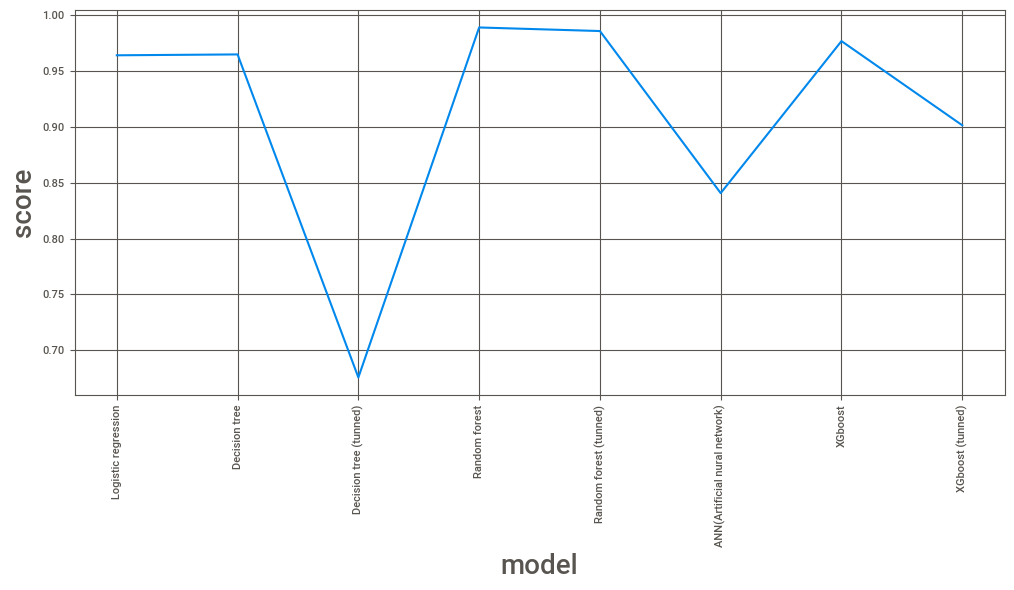

In [224]:
plt.figure(figsize=(12,5))
sns.lineplot(data=model_score,x='model',y='test score')
plt.xlabel('model',fontsize=20)
plt.ylabel('score',fontsize=20)
plt.xticks(rotation=90)
plt.grid()
plt.show()

# Compare all models for cross validation technique :

In [225]:
cv_result=pd.DataFrame({
    'model':['logistic regression','Decision tree','Random Forest','XGboost'],
    'mean cv score':[score_lr.mean(),score_dtc.mean(),score_rfc.mean(),score_xgb.mean()],
    'std cv score':[score_lr.std(),score_dtc.std(),score_rfc.std(),score_xgb.std()]
})
cv_result

,model,mean cv score,std cv score
0,logistic regression,0.637331,0.000741
1,Decision tree,0.978092,0.001388
2,Random Forest,0.997931,0.000196
3,XGboost,0.980919,0.001680


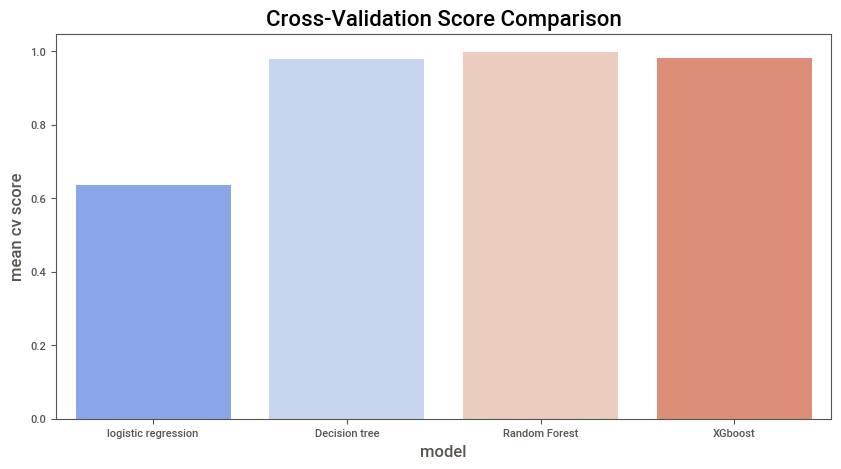

In [226]:
plt.figure(figsize=(10,5))
sns.barplot(data=cv_result,x='model',y='mean cv score',palette='coolwarm')
plt.xlabel('model',fontsize=12)
plt.ylabel('mean cv score',fontsize=12)
plt.title('Cross-Validation Score Comparison', fontsize=16)
plt.show()

important data
                    feature  importance
0                 acct_type    0.080813
5                 feature_7    0.038734
29       feature_1_Insignia    0.033156
37           feature_12_IS1    0.033061
42           feature_12_PD2    0.031132
..                      ...         ...
39           feature_12_PB1    0.000000
38           feature_12_IS2    0.000000
33  feature_1_RBL Bank Fun+    0.000000
26               feature_79    0.000000
35           feature_12_DD2    0.000000

[70 rows x 2 columns]


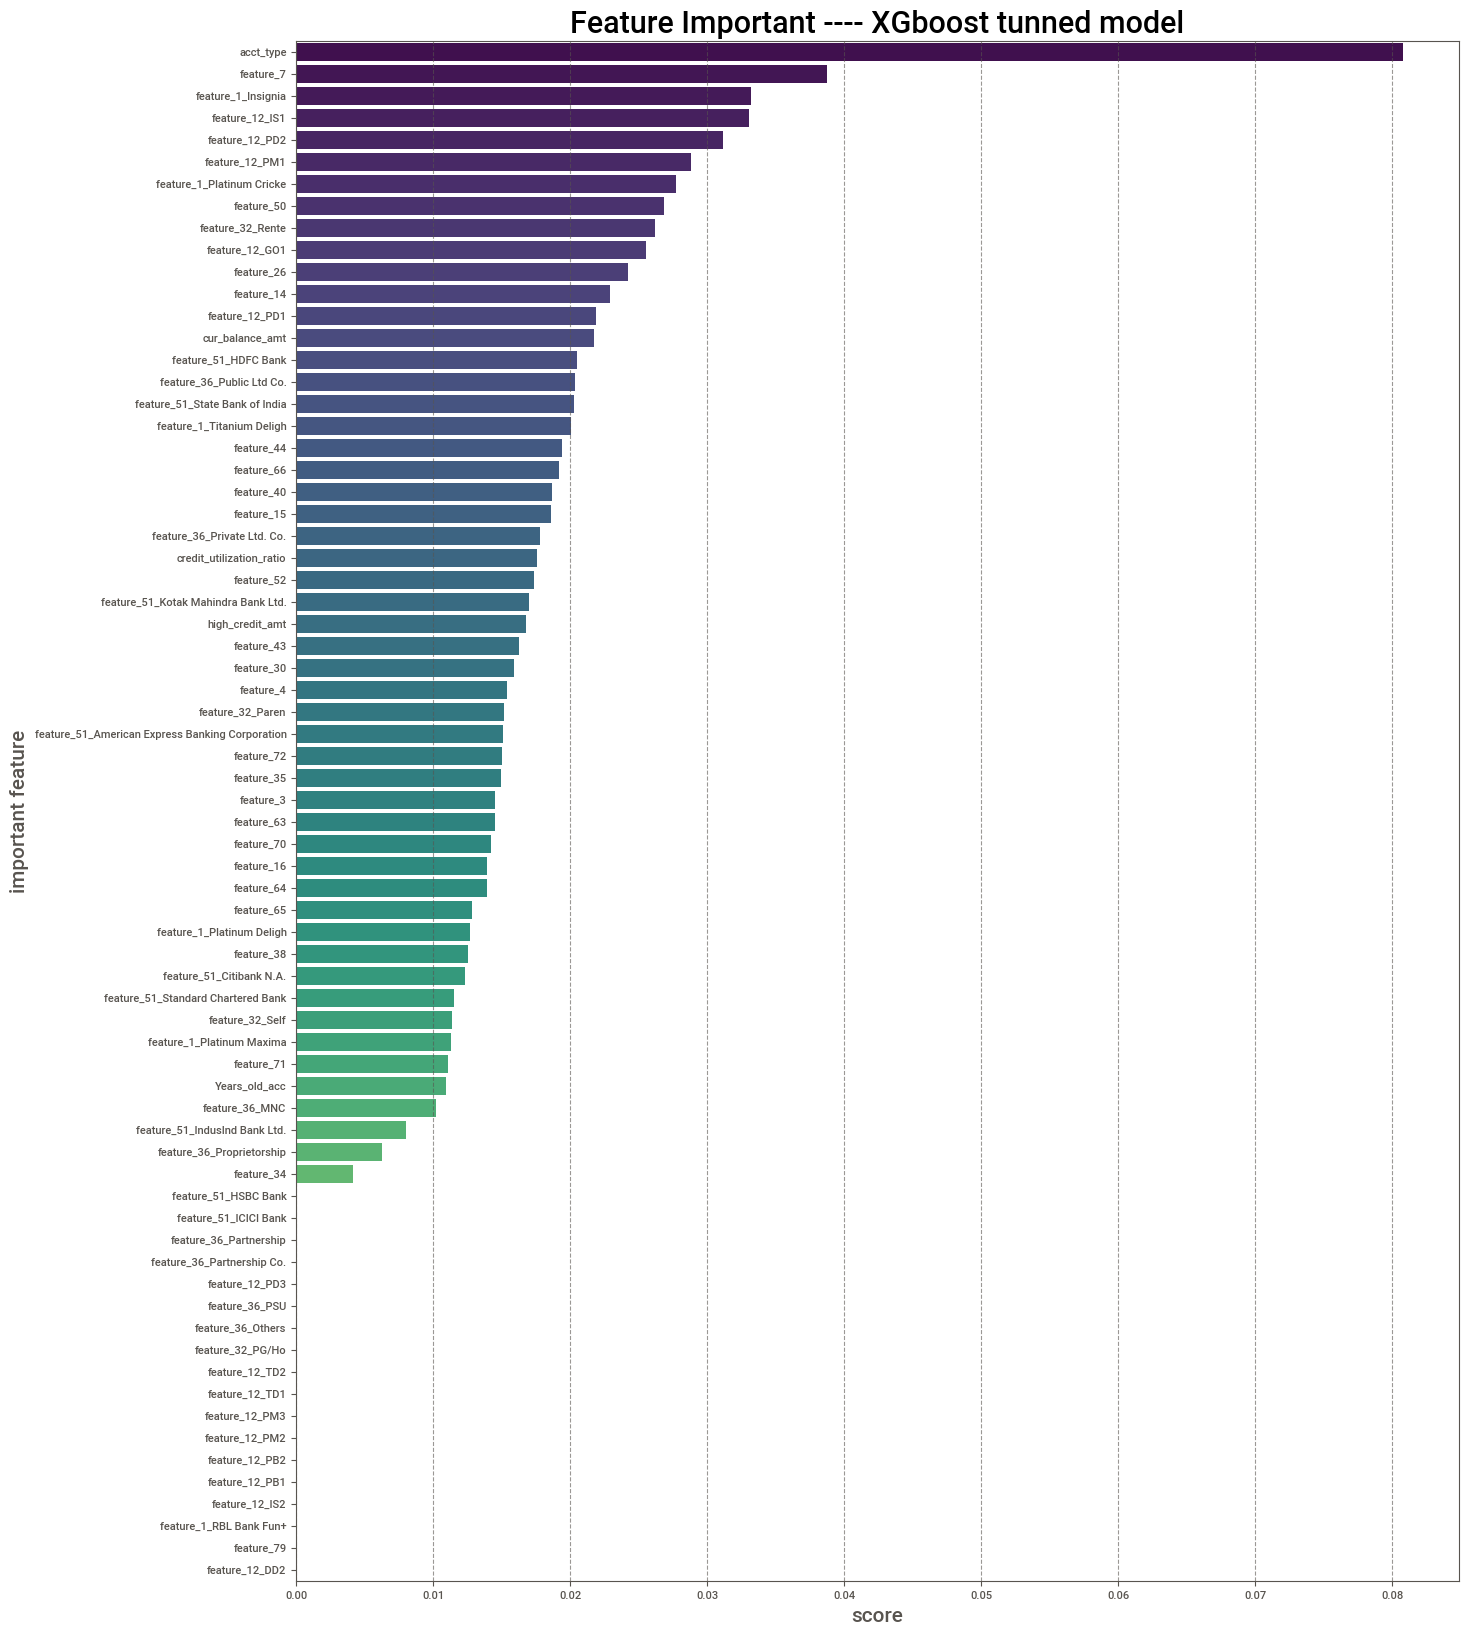

In [229]:
importance=xgbt.feature_importances_
important_feature=pd.DataFrame({
    'feature':x_train_smote.columns,
    'importance':importance
}).sort_values(by='importance',ascending=False)

print('important data')
print(important_feature)

plt.figure(figsize=(15,20))
sns.barplot(data=important_feature,x='importance',y='feature',palette='viridis')
plt.title('Feature Important ---- XGboost tunned model',fontsize=22)
plt.ylabel('important feature',fontsize=15)
plt.xlabel('score',fontsize=15)
plt.grid(axis='x',alpha=0.6,linestyle='--')
plt.show()

# Model Performance Comparison :

## Test set results

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC | Train Accuracy |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.9642 | 0.00 | 0.00 | 0.00 | 0.50 | 0.5001 |
| Decision Tree | 0.9650 | 0.51 | 0.66 | 0.58 | 0.82 | 1.0000 |
| Decision Tree (tuned) | 0.6755 | 0.08 | 0.79 | 0.15 | 0.73 | 0.7532 |
| **Random Forest** | **0.9891** | **0.99** | 0.70 | **0.82** | 0.85 | 1.0000 |
| Random Forest (tuned) | 0.9859 | 0.92 | 0.66 | 0.77 | 0.83 | 0.9999 |
| XGBoost | 0.9769 | 0.67 | 0.71 | 0.69 | 0.85 | 0.9838 |
| XGBoost (tuned) | 0.9015 | 0.17 | 0.47 | 0.25 | 0.69 | 0.9034 |
| ANN | 0.8407 | 0.17 | **0.91** | 0.29 | **0.87** | 0.9113 |

## Cross validation results (5-fold)

| Model | Mean CV Score | Std CV Score |
|---|---|---|
| Logistic Regression | 0.6373 | 0.0007 |
| Decision Tree | 0.9781 | 0.0014 |
| Random Forest | 0.9979 | 0.0002 |
| XGBoost | 0.9809 | 0.0017 |

# Final conclusion :

- The data is highly imbalanced. Only about 3.6% of the customers are bad, so accuracy alone can be misleading. A model that says "good customer" for everyone still gets 96.4% accuracy.
- Logistic Regression did exactly this. It got 96.4% accuracy, but its recall and F1-score for bad customers are 0. It is not useful for this problem.
- **Random Forest is the best model.** It has the highest test accuracy (98.9%), precision (0.99) and F1-score (0.82) for bad customers, and it also has the best CV score (0.9979).
- XGBoost is the second best. Its precision and recall are more balanced (0.67 and 0.71), but its F1-score (0.69) is lower than Random Forest.
- ANN has the highest recall (0.91) and ROC-AUC (0.87), so it finds most bad customers. But its precision is only 0.17, so it flags too many good customers as bad.
- The tuned models did not improve the results. Tuned Decision Tree and tuned XGBoost became much worse than the default models.
- Random Forest has train accuracy of 1.0 against test accuracy of 0.989, so there is some overfitting. But the test result is still strong.
- **Final choice: Random Forest.** Its weak point is that it still misses about 30% of the bad customers (recall 0.70). This can be improved with threshold tuning, class weights or better hyperparameter tuning.

# Model save :

In [231]:
import joblib
joblib.dump(xgbt,'bank good credit.pkl')
print('model save successfully')

model save successfully


 ---- Thank you ----